# BO6 — Garment Classification & Automatic Description

Dataset audit → taxonomy → leakage-safe split → transfer learning → bounded tuning → description
pipeline → verified export, in one Run-All notebook.

**Scope (V1):** one mostly visible garment per image; users review and correct every prediction.
**Deferred (not built here):** multi-garment detection, segmentation, label OCR, image-quality scoring, deployment.

**Working dataset:** Fashion Product Images (catalog photos). Whether it transfers to real DressMe
phone photos is **not** established by this notebook unless you supply phone photos.

## 1. Objective and experiment protocol

1. Audit and repair metadata into one authoritative table, `styles_clean`.
2. Build leakage groups from exact duplicates and *accepted* near-duplicate links.
3. Freeze the Apparel taxonomy before any training.
4. Group-aware 70/15/15 split; the catalog test split stays closed during development.
5. Majority baseline, ResNet-18, MobileNetV3-Small on identical splits; a third model only if the budget allows.
6. Select on **validation macro-F1**; at most three tuning trials on the strongest candidate.
7. Description is a separate pipeline: deterministic template over the category and weak-label attribute heads; optional local VLM.
8. Export every trained candidate; verify the selected bundle in a fresh Python process.

**Failure policy.** Record-level defects are quarantined. A broken invariant stops its stage through an
explicit gate (reported, never silently downgraded). Optional inputs are skipped with a status.
Statuses: `measured`, `provisional`, `skipped`, `pending`, `failed`. A skipped stage is never a pass.

## 2. Configuration and environment

One cell holds every setting. `BO6_MODE=SMOKE` runs a fast software check (tiny images, random init
allowed and labelled). `STANDARD` targets about 2–3 hours of model experiments — a planning budget.

In [1]:
import copy, csv, gc, hashlib, importlib.util, io, json, os, platform, random, re, shutil, subprocess, sys, time, zipfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageFile, ImageOps
from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = False   # truncated files must raise, not be padded

MODE = os.environ.get("BO6_MODE", "STANDARD").upper()
assert MODE in {"SMOKE", "STANDARD"}
STD = MODE == "STANDARD"

INPUT_ROOT = Path(os.environ.get("BO6_INPUT_ROOT", "/kaggle/input"))
WORK = Path(os.environ.get("BO6_WORK_ROOT", "/kaggle/working")) / "bo6"

CFG = {
    "mode": MODE,
    "seed": 42,
    "input_root": str(INPUT_ROOT),
    "work_root": str(WORK),
    "canonical_unit_override": None,        # path string to pin the dataset unit

    # --- preprocessing ---
    "image_size": 224 if STD else 64,
    "pad_fill": [255, 255, 255],            # pad to square: keeps the whole garment
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
    "exif_transpose": True,                 # phone photos carry orientation tags

    # --- loaders / caches ---
    "batch_size": 32 if STD else 8,
    "num_workers": int(os.environ.get("BO6_WORKERS", "2" if STD else "0")),
    "use_cache": True,                      # image-integrity manifest
    "pixel_cache": True,                    # preprocessed uint8 pixels, built once
    "pixel_cache_dir": None,                # None -> /kaggle/temp if present, else work/cache
    "resume": True,                         # reuse finished experiments, resume interrupted ones

    # --- duplicates / leakage ---
    "dhash_side": 8,
    "thumb_side": 12,                       # 12x12 RGB thumbnail: the pixel-similarity signal
    "near_dup_hamming": 6,                  # dHash is only a candidate generator (it matches poses, not products)
    "near_dup_bands": 8,
    "near_dup_max_bucket": 30000,
    "near_dup_report_mad": 8.0,             # pairs kept for the leakage diagnostic (mean abs thumbnail difference)
    "near_dup_strict_mad": 3.0,             # near-identical pixels
    "near_dup_max_pairs": 5_000_000,        # cap on KEPT pairs; reaching it is reported as partial coverage
    "near_dup_policy": "report",            # "report": exact-SHA groups only, near pairs measured (protocol of record)
                                            # "group": strict near pairs also join leakage groups (changes the split)
    "near_dup_max_group": 60,               # "group" policy only: a larger component stops the run

    # --- taxonomy (source articleType -> DressMe label), frozen before training ---
    "taxonomy_version": "dressme-v0.2",
    "target_map": {
        "Tshirts": "t-shirt", "Shirts": "shirt", "Tops": "top", "Jeans": "jeans",
        "Trousers": "trousers", "Track Pants": "trousers", "Shorts": "shorts",
        "Skirts": "skirt", "Dresses": "dress", "Jackets": "jacket",
        "Sweaters": "sweater", "Sweatshirts": "sweatshirt",   # not "hoodie": a hood needs evidence
    },
    "out_of_scope": {
        **{k: "underwear / sleepwear / swimwear: outside the V1 wardrobe scope" for k in [
            "Bra", "Briefs", "Innerwear Vests", "Boxers", "Trunk", "Shapewear", "Camisoles",
            "Stockings", "Baby Dolls", "Nightdress", "Night suits", "Lounge Pants",
            "Lounge Tshirts", "Lounge Shorts", "Robe", "Bath Robe", "Swimwear"]},
        **{k: "multi-piece set: violates the one-garment-per-image contract" for k in [
            "Clothing Set", "Salwar and Dupatta", "Lehenga Choli", "Tracksuits", "Suits"]},
        **{k: "draped item or accessory, not a V1 garment class" for k in [
            "Sarees", "Dupatta", "Stoles", "Suspenders", "Belts", "Socks"]},
    },
    "min_class_rows": 100 if STD else 8,    # per TARGET class, eligible rows
    "min_class_groups": 60 if STD else 6,   # per TARGET class, independent leakage groups
    "min_pool_rows": 200 if STD else 40,
    "min_pool_fraction": 0.25,              # pool smaller than this share of mapped rows = stop
    "split_fracs": [0.70, 0.15, 0.15],

    # --- training ---
    "run_training": True,
    "architectures": ["resnet18", "mobilenet_v3_small"],
    "optional_architecture": "efficientnet_b0",   # only if the measured budget allows
    "head_epochs": 2 if STD else 1,
    "finetune_epochs": 6 if STD else 2,
    "early_stop_patience": 2,               # per phase
    "lr_head": 3e-3,
    "lr_head_finetune": 1e-3,
    "lr_backbone": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,
    "class_weighting": "auto",              # auto | always | never
    "imbalance_ratio_threshold": 8.0,
    "class_weight_power": 0.5,              # sqrt-inverse-frequency: moderate, not aggressive
    "allow_random_init": not STD,           # random init is a SMOKE-only debugging path
    "local_weights": {},                    # {"resnet18": "/kaggle/input/.../resnet18-f37072fd.pth"}
    "allow_weight_download": True,

    # --- tuning / selection ---
    "import_previous_run": None,            # "auto" or a folder holding models/ and experiments/ of an earlier run
                                            # (e.g. bo6_results.zip attached as a dataset): reuse, do not retrain
    "on_import_mismatch": "stop",           # "stop" | "retrain" when an imported run does not match this data/config
    "run_tuning": True,
    "max_tuning_trials": 3,
    "tuning_min_gain": 0.003,               # stop tuning when gains stay below this
    "selection_tolerance": 0.01,            # prefer the lighter model within this macro-F1
    "force_selected_experiment": None,      # manual override, recorded in the selection report
    "review_target_error": 0.05,            # error tolerated among auto-accepted predictions

    # --- budget (planning target for model experiments, not a promise) ---
    "budget_minutes": 150 if STD else 6,

    # --- description ---
    "run_description": True,
    "description_version": "tmpl-v0.4-attributes",
    "run_attributes": True,                 # sleeve / pattern / colour heads on top of the selected classifier
    "attribute_policy": {"sleeve_length": 0.0,   # stated for eligible garments (provisional reviewed-demo policy)
                         "pattern": 0.97,        # stated only at or above this uncalibrated score
                         "color": None},         # never stated: suggestion for the user to confirm
    "attribute_min_class_coverage": 0.5,    # a garment type is eligible if the catalog labels the attribute this often
    "color_map": {"Black": "black", "White": "white", "Off White": "white", "Grey": "grey", "Grey Melange": "grey",
                  "Charcoal": "grey", "Silver": "grey", "Steel": "grey", "Navy Blue": "navy", "Blue": "blue",
                  "Turquoise Blue": "blue", "Red": "red", "Maroon": "red", "Burgundy": "red", "Green": "green",
                  "Olive": "green", "Lime Green": "green", "Sea Green": "green", "Fluorescent Green": "green",
                  "Yellow": "yellow", "Mustard": "yellow", "Gold": "yellow", "Orange": "orange", "Pink": "pink",
                  "Peach": "pink", "Magenta": "pink", "Rose": "pink", "Purple": "purple", "Lavender": "purple",
                  "Mauve": "purple", "Brown": "brown", "Coffee Brown": "brown", "Mushroom Brown": "brown",
                  "Tan": "brown", "Beige": "beige", "Cream": "beige", "Khaki": "beige", "Nude": "beige",
                  "Skin": "beige", "Taupe": "beige"},
    "pattern_map": {"Printed": "printed", "Solid": "solid", "Striped": "striped", "Checked": "checked"},
    "sleeve_map": {"Short Sleeves": "short", "Long Sleeves": "long", "Sleeveless": "sleeveless", "No Sleeves": "sleeveless"},
    "description_sample": 40 if STD else 6,
    "description_review_csv": None,         # completed copy of description_review_template.csv
    "run_vlm": False,
    "vlm_checkpoint": None,                 # local directory of an image-text-to-text model
    "vlm_max_images": 20,
    "vlm_max_new_tokens": 96,

    # --- evaluation / export ---
    "run_final_test": False,                # stays OFF until model choices are frozen
    "dressme_dev_dir": None,                # <dir>/<class>/<img>  or  <dir>/<class>/<garment>/<img>
    "dressme_final_dir": None,
    "export_onnx": False,
    "reload_tolerance": 1e-4,
}
# Optional overrides without editing the cell (recorded in the config dump).
_ovr = json.loads(os.environ.get("BO6_CFG_OVERRIDES", "{}"))
unknown_keys = set(_ovr) - set(CFG)
assert not unknown_keys, f"unknown config override keys: {unknown_keys}"
CFG.update(_ovr)
CFG["overrides_applied"] = sorted(_ovr)

SEED = CFG["seed"]
random.seed(SEED); np.random.seed(SEED)

for sub in ["audit", "taxonomy", "splits", "experiments", "models", "description", "reports",
            "cache", "figures"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
(WORK / "reports" / "config.json").write_text(json.dumps(CFG, indent=2), encoding="utf-8")

RUN_STARTED = datetime.now(timezone.utc)
T_RUN0 = time.time()
STATUS = {}            # stage -> measured | skipped | failed | pending | provisional
def set_status(stage, state, detail=""):
    STATUS[stage] = {"state": state, "detail": detail}
    print(f"[{state.upper():8}] {stage}" + (f" — {detail}" if detail else ""))

def fp_of(obj, n=16):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:n]

print(f"MODE={MODE} | input={INPUT_ROOT} | work={WORK}")
if not INPUT_ROOT.exists():
    raise FileNotFoundError(f"{INPUT_ROOT} missing — attach the dataset (Add Input), then Run All.")

MODE=STANDARD | input=/kaggle/input | work=/kaggle/working/bo6


In [2]:
# Hardware / framework detection. Nothing about the accelerator is assumed.
TORCH_OK, TORCH_ERR = True, ""
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    import torchvision
    from torchvision import transforms
    from torchvision import models as tvm
except Exception as exc:                      # the audit still runs without torch
    TORCH_OK, TORCH_ERR = False, f"{type(exc).__name__}: {exc}"

def native_bf16():
    # is_bf16_supported() also reports *emulated* support on GPUs without native BF16.
    try:
        return bool(torch.cuda.is_bf16_supported(including_emulation=False))
    except TypeError:        # older torch cannot tell native from emulated -> do not assume
        return False
    except Exception:
        return False

DEVICE, AMP_DTYPE, GPU_NAME, VRAM_GB, BF16_NATIVE = "cpu", None, None, None, None
if TORCH_OK:
    if torch.cuda.is_available():
        DEVICE = "cuda"
        GPU_NAME = torch.cuda.get_device_name(0)
        VRAM_GB = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1)
        BF16_NATIVE = native_bf16()
        AMP_DTYPE = "bfloat16" if BF16_NATIVE else "float16"   # FP16 + GradScaler otherwise
    torch.manual_seed(SEED)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(SEED)

ENV = {
    "run_started_utc": RUN_STARTED.isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "pillow": PIL.__version__, "matplotlib": matplotlib.__version__,
    "torch": torch.__version__ if TORCH_OK else None,
    "torchvision": torchvision.__version__ if TORCH_OK else None,
    "torch_error": TORCH_ERR or None,
    "device": DEVICE, "gpu": GPU_NAME, "vram_gb": VRAM_GB,
    "bf16_native": BF16_NATIVE, "amp_dtype": AMP_DTYPE,
    "cpu_count": os.cpu_count(), "seed": SEED, "mode": MODE,
}
try:
    import sklearn
    from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
    ENV["scikit_learn"] = sklearn.__version__
except Exception as exc:
    ENV["scikit_learn"] = None
    TORCH_OK, TORCH_ERR = False, TORCH_ERR or f"scikit-learn unavailable: {exc}"
display(pd.Series(ENV).to_frame("value"))

if TORCH_OK and DEVICE == "cpu" and CFG["run_training"] and STD:
    print("\nWARNING: no CUDA device detected. STANDARD training on CPU will take many hours.\n"
          "         Enable a GPU accelerator, or set BO6_MODE=SMOKE for a software check.")
print("\nNote: fixed seeds do not guarantee bit-identical GPU results "
      "(cuDNN kernel selection, non-deterministic atomics, AMP).")
(WORK / "reports" / "environment.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")

,value
run_started_utc,2026-10-08T01:13:33+00:00
python,3.13.15
platform,Linux-6.18.48+-x86_64-with-glibc2.39
numpy,2.1.3
pandas,2.3.3
pillow,12.3.0
matplotlib,3.10.0
torch,2.11.0+cu128
torchvision,0.26.0+cu128
torch_error,None



Note: fixed seeds do not guarantee bit-identical GPU results (cuDNN kernel selection, non-deterministic atomics, AMP).


492

## 3. Dataset discovery and canonical-unit selection

A *dataset unit* is any directory directly containing `styles.csv`. The Kaggle package ships a
nested copy; counting both would double every statistic. Selection is ranked on completeness
evidence first, then deterministic tie-breakers, with a manual override in `CFG`.

In [3]:
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()


IMAGE_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif"}

def scan_tree(root: Path):
    per_dir, per_bytes, small = defaultdict(Counter), defaultdict(int), []
    for dirpath, _dirs, names in os.walk(root):
        d = Path(dirpath)
        for name in names:
            p = d / name
            try:
                size = p.stat().st_size
            except OSError:
                size = -1
            ext = p.suffix.lower() or "[none]"
            per_dir[d][ext] += 1
            per_bytes[d] += max(size, 0)
            if ext not in IMAGE_EXT:
                small.append({"path": str(p), "ext": ext, "size_bytes": size})
    rows = [{"dir": str(d), "n_files": sum(c.values()),
             "n_images": sum(v for e, v in c.items() if e in IMAGE_EXT),
             "total_bytes": per_bytes[d],
             "extensions": ", ".join(f"{e}:{v}" for e, v in sorted(c.items()))}
            for d, c in per_dir.items()]
    return (pd.DataFrame(rows).sort_values("dir").reset_index(drop=True),
            pd.DataFrame(small, columns=["path", "ext", "size_bytes"]).sort_values("path").reset_index(drop=True))


dir_summary, non_image_files = scan_tree(INPUT_ROOT)
TOTAL_FILES = int(dir_summary["n_files"].sum())
print(f"Dirs: {len(dir_summary):,} | files: {TOTAL_FILES:,} "
      f"| images: {int(dir_summary['n_images'].sum()):,} | other: {len(non_image_files):,}")
display(dir_summary.sort_values("n_files", ascending=False).head(10))

# Fingerprint the small side files (CSV etc.). Per-product JSON files are counted, not hashed.
non_image_files["sha256"] = [
    sha256_file(Path(p)) if (0 <= s <= 200e6 and e != ".json") else None
    for p, s, e in zip(non_image_files["path"], non_image_files["size_bytes"], non_image_files["ext"])]
dir_summary.to_csv(WORK / "audit" / "dataset_manifest.csv", index=False)
non_image_files.to_csv(WORK / "audit" / "non_image_files.csv", index=False)

Dirs: 22 | files: 177,952 | images: 88,903 | other: 89,049


,dir,n_files,n_images,total_bytes,extensions
21,/kaggle/input/datasets/paramaggarwal/fashion-p...,44446,0,782055991,.json:44446
19,/kaggle/input/datasets/paramaggarwal/fashion-p...,44446,0,782055991,.json:44446
20,/kaggle/input/datasets/paramaggarwal/fashion-p...,44441,44441,14919662043,.jpg:44441
18,/kaggle/input/datasets/paramaggarwal/fashion-p...,44441,44441,14919662043,.jpg:44441
3,/kaggle/input/datasets/aymendhieb/bo6-results/...,22,0,800854,".csv:16, .npz:6"
12,/kaggle/input/datasets/aymendhieb/bo6-results/...,19,0,16464564,".json:12, .md:2, .npz:1, .pt:1, .py:2, .txt:1"
13,/kaggle/input/datasets/aymendhieb/bo6-results/...,19,0,16464564,".json:12, .md:2, .npz:1, .pt:1, .py:2, .txt:1"
0,/kaggle/input/datasets/aymendhieb/bo6-results/...,16,0,55272142,.csv:16
4,/kaggle/input/datasets/aymendhieb/bo6-results/...,15,15,2025879,.png:15
5,/kaggle/input/datasets/aymendhieb/bo6-results/...,10,0,44825678,".json:8, .md:1, .pt:1"


In [4]:
def dir_signature(d: Path, sample=64):
    entries = sorted((p.name, p.stat().st_size) for p in d.iterdir() if p.is_file())
    step = max(1, len(entries) // sample)
    return len(entries), tuple(entries[::step][:sample])


csv_paths = [Path(p) for p in non_image_files["path"] if Path(p).name.lower() == "styles.csv"]
if not csv_paths:
    raise FileNotFoundError("No styles.csv under the input root. Attach the dataset.")

rows = []
for d in sorted({p.parent for p in csv_paths}, key=lambda p: (len(p.parts), str(p))):
    img, stl = d / "images", d / "styles"
    n_img = sum(1 for _ in img.iterdir()) if img.is_dir() else 0
    rows.append({
        "unit_dir": str(d), "depth": len(d.parts),
        "styles_csv_sha256": sha256_file(d / "styles.csv"),
        "styles_csv_bytes": (d / "styles.csv").stat().st_size,
        "has_images_dir": img.is_dir(), "n_images": n_img,
        "has_images_csv": (d / "images.csv").is_file(),
        "has_styles_dir": stl.is_dir(),
        "n_style_json": sum(1 for _ in stl.iterdir()) if stl.is_dir() else 0,
        "images_sig": str(dir_signature(img)) if img.is_dir() else "",
        "styles_sig": str(dir_signature(stl)) if stl.is_dir() else "",
    })
units = pd.DataFrame(rows)
display(units.drop(columns=["images_sig", "styles_sig"]))

# Identical CSV hashes say nothing about the image/JSON trees — check those separately.
same_csv = units["styles_csv_sha256"].nunique() == 1
same_img_sig = units.loc[units["has_images_dir"], "images_sig"].nunique() <= 1
print(f"styles.csv identical across units : {same_csv}")
same_json_sig = units.loc[units["has_styles_dir"], "styles_sig"].nunique() <= 1
print(f"images/ signature identical       : {same_img_sig}")
print(f"styles/ signature identical       : {same_json_sig}")
print("  (file count + sampled name/size signature: evidence of equal trees, NOT a byte-level proof)")
if not same_csv:
    print("WARNING: units carry different styles.csv content — these are different dataset "
          "versions. Pin one via CFG['canonical_unit_override'].")

units["completeness"] = (units["has_images_dir"].astype(int) + units["has_images_csv"].astype(int)
                         + units["has_styles_dir"].astype(int))
ranked = units.sort_values(["completeness", "n_images", "depth", "unit_dir"],
                           ascending=[False, False, True, True]).reset_index(drop=True)

if CFG["canonical_unit_override"]:
    UNIT = Path(CFG["canonical_unit_override"])
    if str(UNIT) not in set(units["unit_dir"]):
        raise ValueError(f"Override {UNIT} is not among discovered units.")
    print("Canonical unit pinned by config.")
else:
    UNIT = Path(ranked.loc[0, "unit_dir"])
    if len(ranked) > 1 and (ranked.loc[0, "completeness"] == ranked.loc[1, "completeness"]
                            and ranked.loc[0, "n_images"] == ranked.loc[1, "n_images"]):
        print("NOTE: units tie on completeness; depth/lexicographic tie-break applied.")

STYLES_CSV, IMAGES_DIR = UNIT / "styles.csv", UNIT / "images"
IMAGES_CSV, JSON_DIR = UNIT / "images.csv", UNIT / "styles"
IGNORED_UNITS = [u for u in units["unit_dir"] if Path(u) != UNIT]

print(f"\nCanonical unit: {UNIT}")
print(f"  images/ {IMAGES_DIR.is_dir()} | images.csv {IMAGES_CSV.is_file()} | styles/ {JSON_DIR.is_dir()}")
print("Ignored units (never read again):", ", ".join(IGNORED_UNITS) or "none")
ranked.to_csv(WORK / "audit" / "dataset_units.csv", index=False)
set_status("discovery", "measured", f"{len(units)} unit(s), canonical={UNIT.name}")

,unit_dir,depth,styles_csv_sha256,styles_csv_bytes,has_images_dir,n_images,has_images_csv,has_styles_dir,n_style_json
0,/kaggle/input/datasets/paramaggarwal/fashion-p...,7,cd86bd2d71b4065ed91786a52aa6ccc0eed343949791c6...,4332000,True,44441,True,True,44446
1,/kaggle/input/datasets/paramaggarwal/fashion-p...,8,cd86bd2d71b4065ed91786a52aa6ccc0eed343949791c6...,4332000,True,44441,True,True,44446


styles.csv identical across units : True
images/ signature identical       : True
styles/ signature identical       : True
  (file count + sampled name/size signature: evidence of equal trees, NOT a byte-level proof)
NOTE: units tie on completeness; depth/lexicographic tie-break applied.

Canonical unit: /kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset
  images/ True | images.csv True | styles/ True
Ignored units (never read again): /kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/fashion-dataset
[MEASURED] discovery — 2 unit(s), canonical=fashion-dataset


## 4. CSV structure, repair, quarantine, missingness

Parsed with `csv.reader` — no silent bad-line skipping. Joining overflow fields into
`productDisplayName` is a **hypothesis**, checked per record: a contradiction (id, year, JSON id)
quarantines it; unseen vocabulary sends it to review unless the product JSON corroborates the repair.

In [5]:
COLS = ["id", "gender", "masterCategory", "subCategory", "articleType",
        "baseColour", "season", "year", "usage", "productDisplayName"]
NCOL = len(COLS)

raw = STYLES_CSV.read_bytes()
STYLES_SHA = hashlib.sha256(raw).hexdigest()
raw_lines = re.split(r"\r\n|\r|\n", raw.decode("utf-8-sig"))    # same line breaks csv.reader counts

valid_recs, malformed = [], []
with open(STYLES_CSV, "r", encoding="utf-8-sig", newline="") as f:
    rd = csv.reader(f)
    header = next(rd)
    if header != COLS:
        raise ValueError(f"Schema drift.\nexpected {COLS}\nfound    {header}")
    prev_line, rec_idx = rd.line_num, 0
    for row in rd:
        if not row:
            continue
        rec = {"record_index": rec_idx, "line_start": prev_line + 1,
               "line_end": rd.line_num, "fields": row, "n_fields": len(row)}
        (valid_recs if len(row) == NCOL else malformed).append(rec)
        prev_line, rec_idx = rd.line_num, rec_idx + 1

TOTAL_RECORDS = len(valid_recs) + len(malformed)
print(f"file            : {STYLES_CSV}")
print(f"sha256          : {STYLES_SHA}")
print(f"bytes           : {len(raw):,}")
print(f"records         : {TOTAL_RECORDS:,}")
print(f"  structurally valid : {len(valid_recs):,}")
print(f"  malformed          : {len(malformed):,}")
print("malformed field counts:", dict(sorted(Counter(m["n_fields"] for m in malformed).items())))

print(f"records spanning >1 physical line: {sum(1 for r in valid_recs + malformed if r['line_end'] != r['line_start'])}")
if malformed:
    prev = pd.DataFrame([{"record_index": m["record_index"], "line": m["line_start"],
                          "n_fields": m["n_fields"],
                          "raw": raw_lines[m["line_start"] - 1][:150] if m["line_start"] <= len(raw_lines) else ""}
                         for m in malformed])
    with pd.option_context("display.max_colwidth", 150):
        display(prev.head(30))

file            : /kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/styles.csv
sha256          : cd86bd2d71b4065ed91786a52aa6ccc0eed343949791c663be9af35f105a128c
bytes           : 4,332,000
records         : 44,446
  structurally valid : 44,424
  malformed          : 22
malformed field counts: {11: 20, 12: 2}
records spanning >1 physical line: 0


,record_index,line,n_fields,raw
0,6042,6044,11,"44065,Men,Personal Care,Fragrance,Perfume and Body Mist,Blue,Spring,2017,Casual,Boss Men Perfume, After Shave Balm and Shower Gel Set"
1,6567,6569,11,"3413,Men,Apparel,Topwear,Tshirts,White,Summer,2011,Casual,Myntra Men's Yes, its all about me White T-shirt"
2,7397,7399,11,"23101,Men,Accessories,Accessories,Accessory Gift Set,Pink,Fall,2011,Formal,Turtle Men Formal Pink Tie, Cufflink and Pocket Square Combo Set"
3,7937,7939,11,"23108,Men,Accessories,Accessories,Accessory Gift Set,Purple,Fall,2011,Formal,Turtle Men Formal Purple Tie, Cufflink and Pocket Square Combo Set"
4,9024,9026,11,"4854,Unisex,Footwear,Shoes,Casual Shoes,White,Winter,2012,Casual,Newfeel Unisex White, Blue and Orange Casual Shoes"
5,10262,10264,11,"23109,Men,Accessories,Accessories,Accessory Gift Set,Purple,Fall,2011,Formal,Turtle Men Formal Purple Tie, Cufflink and Pocket Square Combo Set"
6,10425,10427,11,"23100,Men,Accessories,Accessories,Accessory Gift Set,Navy Blue,Fall,2011,Formal,Turtle Men Formal Navy Blue Tie, Cufflink and Pocket Square Combo Set"
7,10903,10905,11,"23107,Men,Accessories,Accessories,Accessory Gift Set,Purple,Fall,2011,Formal,Turtle Men Formal Purple Tie, Cufflink and Pocket Square Combo Set"
8,11371,11373,11,"59768,Women,Accessories,Jewellery,Earrings,Gold,Winter,2016,Casual,Estelle Women Gold, Silver and Copper Toned Earrings"
9,11943,11945,11,"23114,Men,Accessories,Accessories,Accessory Gift Set,Black,Fall,2011,Formal,Turtle Men Formal Black Tie, Cufflink and Pocket Square Combo Set"


In [6]:
valid_df = pd.DataFrame([r["fields"] for r in valid_recs], columns=COLS)
CAT_COLS = ["gender", "masterCategory", "subCategory", "articleType", "baseColour", "season", "usage"]
VOCAB = {c: set(valid_df[c].str.strip().unique()) for c in CAT_COLS}
PAIR_MS = set(map(tuple, valid_df[["masterCategory", "subCategory"]].to_numpy()))
PAIR_SA = set(map(tuple, valid_df[["subCategory", "articleType"]].to_numpy()))
yr = pd.to_numeric(valid_df["year"], errors="coerce").dropna()
YEAR_LO, YEAR_HI = (int(yr.min()), int(yr.max())) if len(yr) else (0, 9999)
VALID_IDS = set(valid_df["id"].str.strip())

def raw_span(m):
    return "\n".join(raw_lines[m["line_start"] - 1:m["line_end"]])

# Light checks on structurally valid rows too (reported, not auto-quarantined).
vid = valid_df["id"].str.strip()
print(f"valid rows: non-integer id {int((~vid.str.fullmatch(r'[0-9]+')).sum())} | "
      f"blank id {int(vid.eq('').sum())} | "
      f"non-numeric non-blank year {int((pd.to_numeric(valid_df['year'], errors='coerce').isna() & valid_df['year'].str.strip().ne('')).sum())}")

# Corroborating evidence: the per-product JSON, when the dataset ships it.
def json_evidence(pid: str):
    p = JSON_DIR / f"{pid}.json"
    if not (JSON_DIR.is_dir() and p.is_file()):
        return None
    try:
        d = json.loads(p.read_text(encoding="utf-8"))
        d = d.get("data", d)
    except Exception:
        return None
    at = d.get("articleType")
    return {"json_articleType": at.get("typeName") if isinstance(at, dict) else at,
            "json_baseColour": d.get("baseColour"), "json_id": str(d.get("id", ""))}


def validate(cand):
    """(hard, review, soft): hard = contradiction, review = unseen vocabulary, soft = note."""
    hard, review, soft = [], [], []
    pid, gender, master, sub, art, colour, season, year, usage, name = [c.strip() for c in cand]
    if not pid.isdigit():
        hard.append("id_not_integer")
    if pid in VALID_IDS:
        hard.append("id_collides_with_valid_record")
    if not (year.isdigit() and YEAR_LO <= int(year) <= YEAR_HI):
        hard.append("year_implausible")
    if not name:
        hard.append("empty_productDisplayName")
    for col, val in zip(CAT_COLS, [gender, master, sub, art, colour, season, usage]):
        if val not in VOCAB[col]:
            review.append(f"{col}_unseen_value")
    if (master, sub) not in PAIR_MS:
        review.append("masterCategory_subCategory_pair_unseen")
    if (sub, art) not in PAIR_SA:
        review.append("subCategory_articleType_pair_unseen")
    ev = json_evidence(pid)
    corroborated = False
    if ev:
        if ev["json_id"] and ev["json_id"] != pid:
            hard.append("json_id_mismatch")
        corroborated = bool(ev["json_articleType"]) and ev["json_articleType"] == art
        if ev["json_articleType"] and not corroborated:
            soft.append(f"json_articleType={ev['json_articleType']}")
        if ev["json_baseColour"] and colour and ev["json_baseColour"] != colour:
            soft.append(f"json_baseColour={ev['json_baseColour']}")
    else:
        soft.append("no_json_evidence")
    return hard, review, soft, corroborated


repaired, repair_log, quarantine = [], [], []
for m in malformed:
    row, idx, rawtxt = m["fields"], m["record_index"], raw_span(m)
    base = {"record_index": idx, "line": m["line_start"], "n_fields": len(row),
            "id_guess": row[0].strip() if row else "", "original_raw": rawtxt,
            "original_fields": json.dumps(row)}
    if len(row) < NCOL:
        quarantine.append({**base, "reason": "too_few_fields", "checks": f"{len(row)}<{NCOL}"})
        continue
    cand = row[:NCOL - 1] + [",".join(row[NCOL - 1:]).strip()]     # the repair HYPOTHESIS
    hard, review, soft, corroborated = validate(cand)
    if hard:
        quarantine.append({**base, "reason": "failed_validation", "checks": ";".join(hard + review)})
    elif review and not corroborated:
        # Unseen vocabulary is not proof of corruption, but nothing corroborates the repair.
        quarantine.append({**base, "reason": "needs_review_unseen_vocabulary", "checks": ";".join(review)})
    else:
        repaired.append(cand)
        repair_log.append({**base, "id": cand[0].strip(), "overflow_fields": len(row) - NCOL,
                           "hypothesis": "join fields[9:] -> productDisplayName",
                           "repaired_fields": json.dumps(cand),
                           "repaired_productDisplayName": cand[9],
                           "evidence": "vocabulary+pairs" + ("+json_articleType" if corroborated else ""),
                           "review_flags": ";".join(review), "soft_flags": ";".join(soft)})

repair_log_df, quarantine_df = pd.DataFrame(repair_log), pd.DataFrame(quarantine)
print(f"malformed {len(malformed)} -> repaired {len(repair_log_df)} | quarantined {len(quarantine_df)}")
if not repair_log_df.empty:
    with pd.option_context("display.max_colwidth", 60):
        display(repair_log_df[["record_index", "id", "n_fields", "overflow_fields",
                               "repaired_productDisplayName", "evidence", "review_flags", "soft_flags"]].head(30))
if not quarantine_df.empty:
    print("Quarantined (not repaired, nothing invented):")
    with pd.option_context("display.max_colwidth", 110):
        display(quarantine_df[["record_index", "line", "n_fields", "id_guess", "reason", "checks"]])
repair_log_df.to_csv(WORK / "audit" / "metadata_repair_log.csv", index=False)
quarantine_df.to_csv(WORK / "audit" / "metadata_quarantine.csv", index=False)

valid rows: non-integer id 0 | blank id 0 | non-numeric non-blank year 0
malformed 22 -> repaired 22 | quarantined 0


,record_index,id,n_fields,overflow_fields,repaired_productDisplayName,evidence,review_flags,soft_flags
0,6042,44065,11,1,"Boss Men Perfume, After Shave Balm and Shower Gel Set",vocabulary+pairs+json_articleType,,
1,6567,3413,11,1,"Myntra Men's Yes, its all about me White T-shirt",vocabulary+pairs+json_articleType,,
2,7397,23101,11,1,"Turtle Men Formal Pink Tie, Cufflink and Pocket Square C...",vocabulary+pairs+json_articleType,,
3,7937,23108,11,1,"Turtle Men Formal Purple Tie, Cufflink and Pocket Square...",vocabulary+pairs+json_articleType,,
4,9024,4854,11,1,"Newfeel Unisex White, Blue and Orange Casual Shoes",vocabulary+pairs+json_articleType,,
5,10262,23109,11,1,"Turtle Men Formal Purple Tie, Cufflink and Pocket Square...",vocabulary+pairs+json_articleType,,
6,10425,23100,11,1,"Turtle Men Formal Navy Blue Tie, Cufflink and Pocket Squ...",vocabulary+pairs+json_articleType,,
7,10903,23107,11,1,"Turtle Men Formal Purple Tie, Cufflink and Pocket Square...",vocabulary+pairs+json_articleType,,
8,11371,59768,11,1,"Estelle Women Gold, Silver and Copper Toned Earrings",vocabulary+pairs+json_articleType,,
9,11943,23114,11,1,"Turtle Men Formal Black Tie, Cufflink and Pocket Square ...",vocabulary+pairs+json_articleType,,


In [7]:
# ---- styles_clean: the ONE authoritative metadata table ----
styles_clean = pd.DataFrame([r["fields"] for r in valid_recs] + repaired, columns=COLS)
styles_clean["id"] = styles_clean["id"].astype(str).str.strip()
styles_clean["source"] = ["valid"] * len(valid_recs) + ["repaired"] * len(repaired)

# ---- duplicate ids: identical rows collapse, conflicting rows are quarantined ----
dups = styles_clean[styles_clean["id"].duplicated(keep=False)]
distinct = dups.drop_duplicates(subset=COLS)
conflicting = set(distinct["id"][distinct["id"].duplicated(keep=False)])
dup_conflict_rows = styles_clean[styles_clean["id"].isin(conflicting)].copy()
dup_conflict_rows["reason"] = "duplicate_id_conflicting_metadata"
dup_conflict_rows.to_csv(WORK / "audit" / "duplicate_id_conflicts.csv", index=False)
styles_clean = styles_clean[~styles_clean["id"].isin(conflicting)]
n_before = len(styles_clean)
styles_clean = styles_clean.drop_duplicates(subset=["id"], keep="first").reset_index(drop=True)
N_COLLAPSED = n_before - len(styles_clean)
N_QUARANTINED = len(quarantine) + len(dup_conflict_rows)
print(f"duplicate ids: {dups['id'].nunique()} | conflicting ids quarantined: {len(conflicting)} "
      f"({len(dup_conflict_rows)} rows) | identical duplicate rows collapsed: {N_COLLAPSED}")

# Every source record is accounted for exactly once.
n_valid_kept = int((styles_clean["source"] == "valid").sum())
n_rep_kept = int((styles_clean["source"] == "repaired").sum())
assert styles_clean["id"].is_unique
assert n_valid_kept + n_rep_kept + N_COLLAPSED + N_QUARANTINED == TOTAL_RECORDS, "record accounting broken"
print(f"accounting: {n_valid_kept:,} valid + {n_rep_kept} repaired + {N_QUARANTINED} quarantined "
      f"(+ {N_COLLAPSED} identical duplicates collapsed) = {TOTAL_RECORDS:,}  OK")

# ---- missingness: genuine nulls vs blanks vs literal sentinels, per column ----
SENTINELS = {"NA", "N/A", "na", "n/a", "null", "NULL", "None", "none", "nan", "NaN", "-", "undefined"}
rows = []
for c in COLS:
    s = styles_clean[c].astype("string")
    st = s.str.strip()
    blank, sent = st.eq("").fillna(False), st.isin(list(SENTINELS)).fillna(False)
    rows.append({"column": c, "null": int(s.isna().sum()), "blank_or_ws": int(blank.sum()),
                 "literal_sentinel": int(sent.sum()), "n_unique": int(s.nunique(dropna=False)),
                 "sentinel_values": ", ".join(sorted(set(st[sent]))[:4])})
missingness = pd.DataFrame(rows)
display(missingness)
missingness.to_csv(WORK / "audit" / "missingness_report.csv", index=False)

# Column-specific meaning: "NA" in `usage` is a catalog category, not a missing value.
# Raw values are preserved; a parallel *_isnull column records the interpretation.
SENTINEL_IS_VALUE = {"usage"}
for c in COLS:
    st = styles_clean[c].astype("string").str.strip()
    flag = st.eq("") | st.isna()
    if c not in SENTINEL_IS_VALUE:
        flag = flag | st.isin(list(SENTINELS))
    styles_clean[f"{c}_isnull"] = flag.fillna(True).astype(bool)
print("\nsentinels kept as real values in:", sorted(SENTINEL_IS_VALUE),
      "| elsewhere flagged missing (raw value untouched).")
print("Missing auxiliary metadata does not exclude a row from category training; "
      "only a missing articleType or image does.")

styles_clean.to_csv(WORK / "audit" / "styles_clean.csv", index=False)
print(f"\nstyles_clean: {styles_clean.shape}")
display(styles_clean.head(3))
set_status("metadata_audit", "measured",
           f"{len(styles_clean):,} rows, {n_rep_kept} repaired, {N_QUARANTINED} quarantined")

duplicate ids: 0 | conflicting ids quarantined: 0 (0 rows) | identical duplicate rows collapsed: 0
accounting: 44,424 valid + 22 repaired + 0 quarantined (+ 0 identical duplicates collapsed) = 44,446  OK


,column,null,blank_or_ws,literal_sentinel,n_unique,sentinel_values
0,id,0,0,0,44446,
1,gender,0,0,0,5,
2,masterCategory,0,0,0,7,
3,subCategory,0,0,0,45,
4,articleType,0,0,0,143,
5,baseColour,0,0,15,47,NA
6,season,0,21,0,5,
7,year,0,1,0,14,
8,usage,0,1,316,10,NA
9,productDisplayName,0,0,7,31137,NA



sentinels kept as real values in: ['usage'] | elsewhere flagged missing (raw value untouched).
Missing auxiliary metadata does not exclude a row from category training; only a missing articleType or image does.

styles_clean: (44446, 21)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,...,id_isnull,gender_isnull,masterCategory_isnull,subCategory_isnull,articleType_isnull,baseColour_isnull,season_isnull,year_isnull,usage_isnull,productDisplayName_isnull
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Turtle Check Men Navy Blue Shirt,...,False,False,False,False,False,False,False,False,False,False
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012,Casual,Peter England Men Party Blue Jeans,...,False,False,False,False,False,False,False,False,False,False
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016,Casual,Titan Women Silver Watch,...,False,False,False,False,False,False,False,False,False,False


[MEASURED] metadata_audit — 44,446 rows, 22 repaired, 0 quarantined


## 5. Image inventory and integrity

The directory is inventoried first; `{id}.jpg` is checked, not assumed. Every canonical image file
(orphans included) is fully decoded with truncation treated as an error — `verify()` alone would miss it.

In [8]:
all_files = sorted(p for p in IMAGES_DIR.iterdir() if p.is_file())
img_files = [p for p in all_files if p.suffix.lower() in IMAGE_EXT]
other_files = [p for p in all_files if p.suffix.lower() not in IMAGE_EXT]

stems = defaultdict(list)
for p in img_files:
    stems[p.stem].append(p)
ambiguous = {s: ps for s, ps in stems.items() if len(ps) > 1}

print(f"files {len(all_files):,} | images {len(img_files):,} | non-image {len(other_files)}")
print("extensions:", dict(Counter(p.suffix.lower() for p in all_files)))
print(f"distinct stems {len(stems):,} | ambiguous stems {len(ambiguous)}")
if ambiguous:
    display(pd.DataFrame([{"stem": s, "files": ", ".join(x.name for x in ps)}
                          for s, ps in list(ambiguous.items())[:20]]))
if other_files:
    print("non-image files present:", [p.name for p in other_files[:8]])
non_jpg = [p for p in img_files if p.suffix.lower() not in {".jpg", ".jpeg"}]
print(f"non-JPEG images: {len(non_jpg)}" + (f" e.g. {[p.name for p in non_jpg[:6]]}" if non_jpg else ""))

def pick(ps):
    return sorted(ps, key=lambda p: (p.suffix.lower() not in {".jpg", ".jpeg"}, p.name))[0]
stem_file = {s: pick(ps) for s, ps in stems.items()}

files 44,441 | images 44,441 | non-image 0
extensions: {'.jpg': 44441}
distinct stems 44,441 | ambiguous stems 0
non-JPEG images: 0


In [9]:
meta_ids = set(styles_clean["id"])
styles_clean["image_path"] = styles_clean["id"].map(lambda i: str(stem_file[i]) if i in stem_file else None)
styles_clean["image_relpath"] = styles_clean["id"].map(
    lambda i: str(stem_file[i].relative_to(UNIT)) if i in stem_file else None)   # reusable manifests
styles_clean["has_image"] = styles_clean["image_path"].notna()

orphans = sorted(set(stems) - meta_ids)
# ids of every record that did not reach styles_clean (malformed-quarantined, id conflicts)
unclean_ids = {q["id_guess"] for q in quarantine if q["id_guess"].isdigit()} | set(dup_conflict_rows["id"])
orphan_set = set(orphans)
corr = {
    "metadata_rows": len(styles_clean),
    "metadata_with_image": int(styles_clean["has_image"].sum()),
    "metadata_without_image": int((~styles_clean["has_image"]).sum()),
    "image_stems": len(stems),
    "orphan_images": len(orphans),
    "quarantined_record_ids": len(unclean_ids),
    "orphan_ids_that_are_quarantined_ids": len(orphan_set & unclean_ids),
    "quarantined_ids_without_image": len(unclean_ids - set(stems)),
    "orphan_ids_unexplained": len(orphan_set - unclean_ids),
}
display(pd.Series(corr).to_frame("value"))
print("ID-set comparison, not a count comparison: equal counts would not prove equal sets.")
pd.DataFrame({"orphan_stem": orphans,
              "explained_by_quarantined_record": [o in unclean_ids for o in orphans]}
             ).to_csv(WORK / "audit" / "orphan_images.csv", index=False)
styles_clean.loc[~styles_clean["has_image"], ["id", "masterCategory", "articleType", "productDisplayName"]] \
    .assign(exclusion_reason="no image file").to_csv(WORK / "audit" / "metadata_without_image.csv", index=False)
display(styles_clean.loc[~styles_clean["has_image"], ["id", "masterCategory", "articleType"]].head(10))

,value
metadata_rows,44446
metadata_with_image,44441
metadata_without_image,5
image_stems,44441
orphan_images,0
quarantined_record_ids,0
orphan_ids_that_are_quarantined_ids,0
quarantined_ids_without_image,0
orphan_ids_unexplained,0


ID-set comparison, not a count comparison: equal counts would not prove equal sets.


,id,masterCategory,articleType
6695,39403,Apparel,Shirts
16194,39410,Apparel,Shirts
32309,39401,Apparel,Jeans
36381,39425,Apparel,Tshirts
40000,12347,Apparel,Suits


In [10]:
DHASH, TH = CFG["dhash_side"], CFG["thumb_side"]

def inspect(arg):
    key, path_str = arg
    p = Path(path_str)
    r = {"key": key, "filename": p.name, "path": path_str, "decoded": False, "error": "",
         "width": None, "height": None, "aspect": None, "format": None, "mode": None,
         "size_bytes": None, "sha256": None, "dhash": None, "thumb": None}
    try:
        data = p.read_bytes()
        r["size_bytes"] = len(data)
        r["sha256"] = hashlib.sha256(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            r["width"], r["height"], r["format"], r["mode"] = im.width, im.height, im.format, im.mode
            im.draft("RGB", (96, 96))        # JPEG: reduced-size decode, still reads the whole scan
            rgb = im.convert("RGB")          # real decode — raises on truncated data
            g = rgb.convert("L").resize((DHASH + 1, DHASH), Image.BILINEAR)
            t = rgb.resize((TH, TH), Image.BILINEAR)
        a = np.asarray(g, dtype=np.int16)
        r["dhash"] = f"{int(np.packbits((a[:, 1:] > a[:, :-1]).flatten()).view('>u8')[0]):016x}"
        r["thumb"] = np.asarray(t, dtype=np.uint8).tobytes()
        r["aspect"] = round(r["width"] / r["height"], 4)
        r["decoded"] = True
    except Exception as exc:
        r["error"] = f"{type(exc).__name__}: {exc}"
    return r


targets = [(r.id, r.image_path) for r in
           styles_clean.loc[styles_clean["has_image"], ["id", "image_path"]].itertuples()]
targets += [(f"orphan:{s}", str(stem_file[s])) for s in orphans]

# Cache key: every file's name+size, the keys, and the algorithm settings.
FP = fp_of({"algo": "v3-decode+sha256+dhash+thumb", "dhash": DHASH, "thumb": TH,
            "files": sorted((k, Path(p).name, Path(p).stat().st_size) for k, p in targets)})
cache_fp = WORK / "cache" / f"image_manifest_{FP}.parquet"

images_df = None
if CFG["use_cache"] and cache_fp.exists():
    try:
        images_df = pd.read_parquet(cache_fp)
        images_df["path"] = images_df["filename"].map(lambda n: str(IMAGES_DIR / n))
        print(f"loaded cached manifest {cache_fp.name} ({len(images_df):,} rows; "
              f"decode checks were performed when it was built)")
    except Exception as e:
        print("cache unreadable, recomputing:", e)
if images_df is None:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=min(8, (os.cpu_count() or 2) * 2)) as pool:
        recs = list(pool.map(inspect, targets, chunksize=64))
    images_df = pd.DataFrame(recs).sort_values("filename").reset_index(drop=True)
    print(f"inspected {len(images_df):,} files in {time.time()-t0:.1f}s (full decode, truncation is an error)")
    if CFG["use_cache"]:
        try:
            images_df.to_parquet(cache_fp, index=False)
        except Exception as e:
            print("manifest cache not written (results unaffected):", e)

bad = images_df[~images_df["decoded"]]
print(f"decode failures: {len(bad)}")
if not bad.empty:
    with pd.option_context("display.max_colwidth", 80):
        display(bad[["key", "filename", "size_bytes", "error"]].head(20))
images_df.drop(columns=["thumb", "path"]).to_csv(WORK / "audit" / "image_integrity_manifest.csv", index=False)
bad.drop(columns=["thumb", "path"]).assign(exclusion_reason="decode_failed") \
    .to_csv(WORK / "audit" / "image_excluded.csv", index=False)
set_status("image_integrity", "measured", f"{len(images_df):,} inspected, {len(bad)} failed")

inspected 44,441 files in 175.4s (full decode, truncation is an error)
decode failures: 0
[MEASURED] image_integrity — 44,441 inspected, 0 failed


,count,mean,std,min,25%,50%,75%,max
width,44441.0,1397.14,367.21,150.00,1080.00,1080.00,1800.00,3744.0
height,44441.0,1862.87,489.97,200.00,1440.00,1440.00,2400.00,5616.0
aspect,44441.0,0.75,0.00,0.66,0.75,0.75,0.75,1.0
size_bytes,44441.0,335718.41,184758.49,2727.00,233714.00,313634.00,379021.00,4692328.0


,count
mode,
RGB,44441


,count
format,
JPEG,44441


distinct (w,h): 44


,,count
width,height,
1080,1440,24459
1800,2400,19721
150,200,119
360,480,60
540,720,21


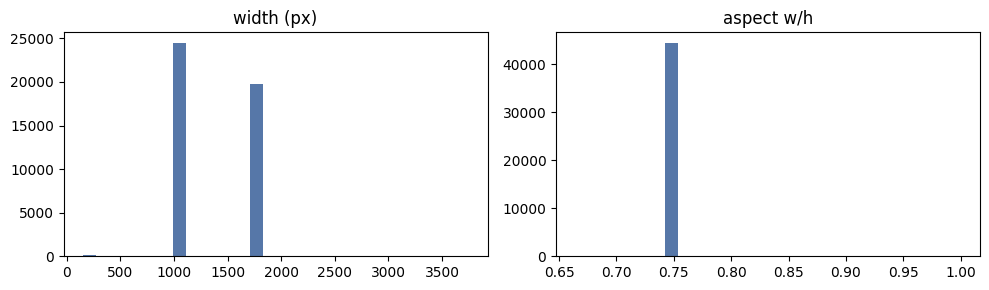

rows with a usable image: 44441


In [11]:
good = images_df[images_df["decoded"]].copy().reset_index(drop=True)
if good.empty:
    raise RuntimeError("no image decoded — stop and investigate the image directory")
good["id"] = good["key"].str.replace("^orphan:", "", regex=True)
assert good["id"].is_unique
display(good[["width", "height", "aspect", "size_bytes"]].astype(float).describe().T.round(2))
display(good["mode"].value_counts().to_frame("count"))
display(good["format"].value_counts().to_frame("count"))
sizes = good.groupby(["width", "height"]).size().sort_values(ascending=False)
print(f"distinct (w,h): {len(sizes)}")
display(sizes.head(5).to_frame("count"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(good["width"].astype(float), bins=30, color="#5677a8"); ax[0].set_title("width (px)")
ax[1].hist(good["aspect"].astype(float), bins=30, color="#5677a8"); ax[1].set_title("aspect w/h")
plt.tight_layout(); plt.savefig(WORK / "figures" / "image_dimensions.png", dpi=90); plt.show()

# Record image usability in the authoritative table and persist it.
bad_names = set(bad["filename"])
styles_clean["image_ok"] = [isinstance(p, str) and Path(p).name not in bad_names for p in styles_clean["image_path"]]
print("rows with a usable image:", int(styles_clean["image_ok"].sum()))
styles_clean.drop(columns=["image_path"]).to_csv(WORK / "audit" / "styles_clean.csv", index=False)

## 6. Exact duplicates and near-duplicate measurement

SHA-256 proves exact copies; those never cross splits. Perceptual hashes alone proved unreliable on this
catalog (they match the model's pose, not the product), so a hash match is only a candidate and is kept
only when the pixels are also close. Near pairs are **measured and reported**; under the default
`report` policy they do not change the split. Product identity is not established by any of this.

In [12]:
TARGET_MAP = dict(CFG["target_map"])
meta = styles_clean.set_index("id")
exact = good.loc[good["sha256"].duplicated(keep=False), ["id", "filename", "sha256"]].copy()
exact["dup_group"] = exact.groupby("sha256").ngroup()
exact = exact.merge(styles_clean[["id", "masterCategory", "articleType", "productDisplayName"]],
                    on="id", how="left")
exact["target"] = [TARGET_MAP.get(a, f"<unmapped:{a}>") if isinstance(a, str) else None
                   for a in exact["articleType"]]

n_groups = int(exact["dup_group"].nunique())
print(f"exact-duplicate groups (SHA-256): {n_groups} | files involved: {len(exact)} "
      f"| redundant copies: {len(exact) - n_groups}")
SRC_CONFLICT, TGT_CONFLICT = set(), set()
if n_groups:
    g = exact.groupby("dup_group")
    SRC_CONFLICT = set(g["articleType"].nunique(dropna=True).loc[lambda s: s > 1].index)
    TGT_CONFLICT = set(g["target"].nunique(dropna=True).loc[lambda s: s > 1].index)
    exact["source_label_conflict"] = exact["dup_group"].isin(SRC_CONFLICT)
    exact["target_label_conflict"] = exact["dup_group"].isin(TGT_CONFLICT)
    print(f"groups with conflicting articleType     : {len(SRC_CONFLICT)}")
    print(f"groups with conflicting DressMe target  : {len(TGT_CONFLICT)}")
    with pd.option_context("display.max_colwidth", 40):
        display(exact[exact["source_label_conflict"]].sort_values(["dup_group", "id"])[
            ["dup_group", "id", "filename", "articleType", "target", "target_label_conflict"]].head(20))
exact.sort_values(["dup_group", "id"]).to_csv(WORK / "audit" / "exact_duplicate_groups.csv", index=False)
# Policy: identical pixels with contradictory DressMe targets cannot both be right -> every
# member is excluded from training and kept in the audit. Same-target source conflicts are kept.
CONFLICT_IDS = set(exact.loc[exact["dup_group"].isin(TGT_CONFLICT), "id"])
print(f"ids excluded from training by the duplicate-target-conflict policy: {len(CONFLICT_IDS)}")

exact-duplicate groups (SHA-256): 652 | files involved: 1431 | redundant copies: 779
groups with conflicting articleType     : 7
groups with conflicting DressMe target  : 7


,dup_group,id,filename,articleType,target,target_label_conflict
513,54,33259,33259.jpg,Shorts,shorts,True
820,54,39336,39336.jpg,Capris,<unmapped:Capris>,True
346,223,28345,28345.jpg,Sunglasses,<unmapped:Sunglasses>,True
348,223,28347,28347.jpg,Free Gifts,<unmapped:Free Gifts>,True
1148,277,51073,51073.jpg,Free Gifts,<unmapped:Free Gifts>,True
1149,277,51101,51101.jpg,Sarees,<unmapped:Sarees>,True
92,311,1165,1165.jpg,Tshirts,t-shirt,True
1136,311,5062,5062.jpg,Watches,<unmapped:Watches>,True
248,386,21810,21810.jpg,Wallets,<unmapped:Wallets>,True
270,386,23810,23810.jpg,Casual Shoes,<unmapped:Casual Shoes>,True


ids excluded from training by the duplicate-target-conflict policy: 14


hash candidates examined: 52,557,066 in 76s -> pixel-similar pairs kept: 1,500,333 (near-identical: 55,914)
coverage: partial | skipped buckets 0 | cap reached True
These are automatic similarity links, NOT product identity and NOT exhaustive: a duplicate whose hash differs by more than the candidate rule is not found.

policy 'report': 652 leakage groups hold more than one image; largest = 4


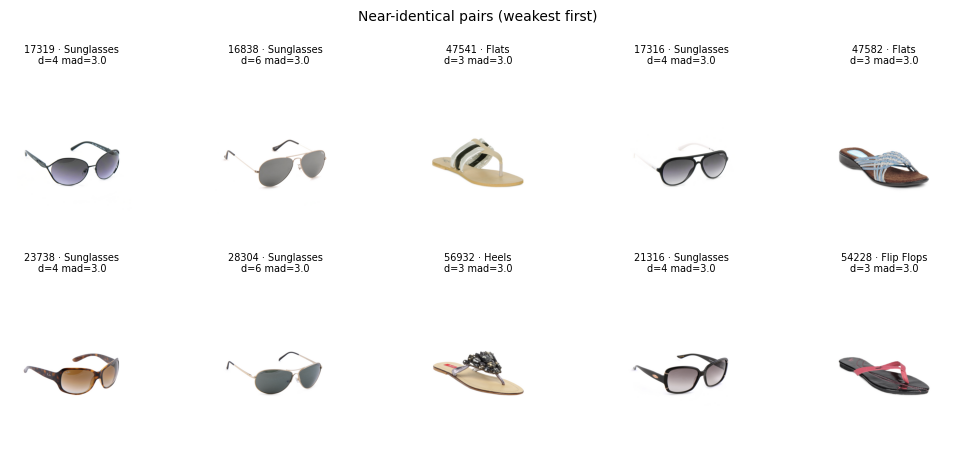

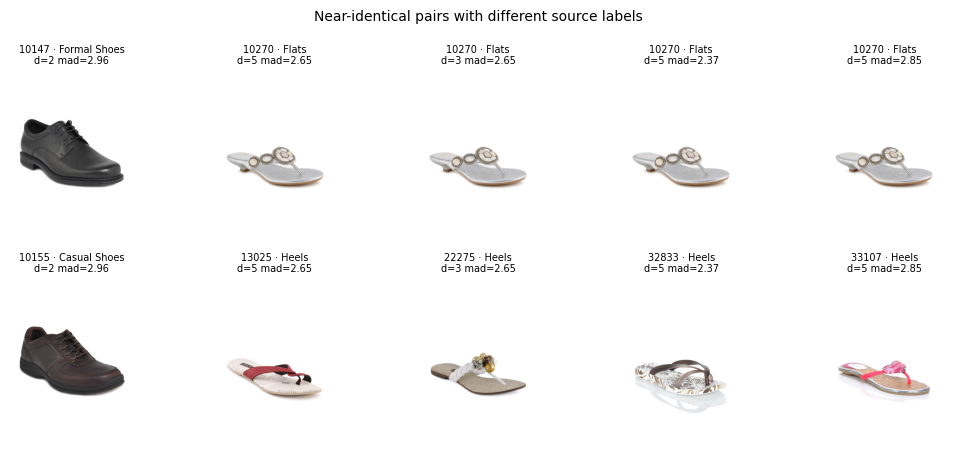

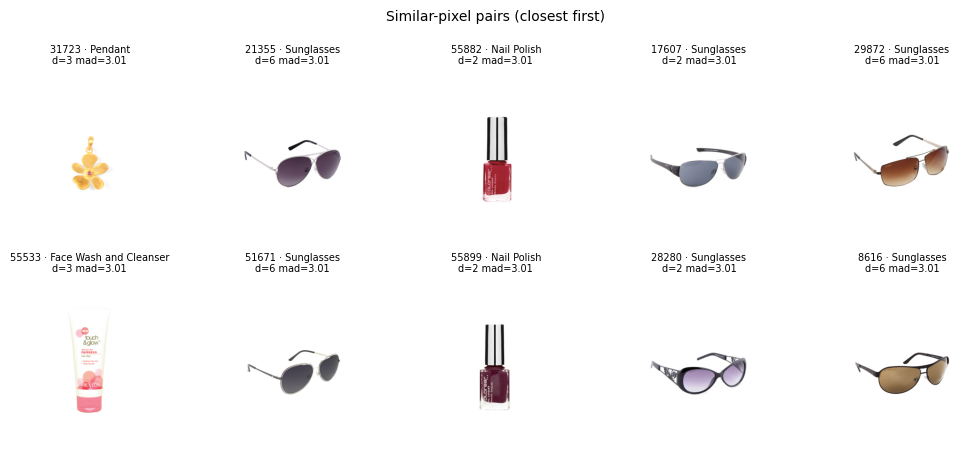

[MEASURED] duplicate_audit — 652 exact groups; 55914 near-identical + 1444419 similar pairs measured; policy=report; coverage partial


In [13]:
# Near-duplicate measurement. dHash only proposes candidates (on this catalog it matches the model's
# pose, not the product); a pair is KEPT only if its pixels are also close (thumbnail difference).
h = np.array([int(x, 16) for x in good["dhash"]], dtype=np.uint64)
ids = good["id"].to_numpy()
sha = good["sha256"].to_numpy()
N = len(h)
THUMBS = np.stack([np.frombuffer(b, dtype=np.uint8) for b in good["thumb"]]).astype(np.int16)
if hasattr(np, "bitwise_count"):
    popcount = np.bitwise_count
else:
    _POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def popcount(x):
        x = np.ascontiguousarray(x)
        return _POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(-1)

THR, bands = CFG["near_dup_hamming"], CFG["near_dup_bands"]
MAD_REPORT, MAD_STRICT = CFG["near_dup_report_mad"], CFG["near_dup_strict_mad"]
bb = 64 // bands
KA, KB, KD, KM, n_kept, n_candidates = [], [], [], [], 0, 0
TRUNCATED, skipped_buckets, skipped_files = False, 0, set()
t0 = time.time()
for b in range(bands):
    if TRUNCATED:
        break
    key = (h >> np.uint64(b * bb)) & np.uint64((1 << bb) - 1)
    order = np.argsort(key, kind="stable")
    sk = key[order]
    starts = np.flatnonzero(np.r_[True, sk[1:] != sk[:-1]])
    for s, e in zip(starts, np.r_[starts[1:], len(sk)]):
        sel = order[s:e]
        if len(sel) < 2:
            continue
        if len(sel) > CFG["near_dup_max_bucket"]:
            skipped_buckets += 1; skipped_files.update(sel.tolist())
            continue
        hs = h[sel]
        for s0 in range(0, len(sel), 256):                 # blocked: bounded memory
            D = popcount(hs[s0:s0 + 256, None] ^ hs[None, :])
            ii, jj = np.nonzero(D <= THR)
            m = (ii + s0) < jj
            a, c, d = sel[ii[m] + s0], sel[jj[m]], D[ii[m], jj[m]]
            n_candidates += len(a)
            for c0 in range(0, len(a), 200_000):
                mad = np.abs(THUMBS[a[c0:c0 + 200_000]] - THUMBS[c[c0:c0 + 200_000]]).mean(1)
                k = mad <= MAD_REPORT
                KA.append(np.minimum(a[c0:c0 + 200_000], c[c0:c0 + 200_000])[k])
                KB.append(np.maximum(a[c0:c0 + 200_000], c[c0:c0 + 200_000])[k])
                KD.append(d[c0:c0 + 200_000][k]); KM.append(mad[k]); n_kept += int(k.sum())
        if n_kept > CFG["near_dup_max_pairs"]:
            TRUNCATED = True
            break

near_df = pd.DataFrame({"ia": np.concatenate(KA) if KA else [], "ib": np.concatenate(KB) if KB else [],
                        "hamming": np.concatenate(KD) if KD else [], "thumb_mad": np.concatenate(KM) if KM else []})
near_df = near_df.drop_duplicates(["ia", "ib"]).astype({"ia": int, "ib": int, "hamming": int}).reset_index(drop=True)
near_df["exact"] = sha[near_df["ia"]] == sha[near_df["ib"]]
near_df = near_df[~near_df["exact"]].drop(columns="exact").reset_index(drop=True)     # exact copies are handled by SHA-256
at_map = styles_clean.set_index("id")["articleType"].to_dict()
near_df["id_a"], near_df["id_b"] = ids[near_df["ia"]], ids[near_df["ib"]]
near_df["articleType_a"], near_df["articleType_b"] = near_df["id_a"].map(at_map), near_df["id_b"].map(at_map)
near_df["thumb_mad"] = near_df["thumb_mad"].round(2)
near_df["level"] = np.where(near_df["thumb_mad"] <= MAD_STRICT, "near_identical_pixels", "similar_pixels")

COVERAGE = "partial" if (TRUNCATED or skipped_buckets) else "complete within the candidate rule"
COVERAGE_DETAIL = {"candidate_rule": f"dHash-64 distance <= {THR} ({bands}x{bb}-bit bands)", "kept_rule": f"thumbnail MAD <= {MAD_REPORT}",
                   "hash_candidates_examined": int(n_candidates), "pairs_kept": int(len(near_df)),
                   "pair_cap_reached": TRUNCATED, "oversized_buckets_skipped": skipped_buckets,
                   "files_in_skipped_buckets": len(skipped_files)}
print(f"hash candidates examined: {n_candidates:,} in {time.time() - t0:.0f}s -> pixel-similar pairs kept: {len(near_df):,} "
      f"(near-identical: {int((near_df['level'] == 'near_identical_pixels').sum()):,})")
print(f"coverage: {COVERAGE} | skipped buckets {skipped_buckets} | cap reached {TRUNCATED}")
print("These are automatic similarity links, NOT product identity and NOT exhaustive: a duplicate whose "
      "hash differs by more than the candidate rule is not found.")

# Leakage groups: exact SHA-256 copies always; strict near pairs only under the "group" policy.
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)
for _, grp_idx in good.groupby("sha256").indices.items():
    for m in grp_idx[1:]:
        union(int(grp_idx[0]), int(m))
if CFG["near_dup_policy"] == "group":
    for r in near_df[near_df["level"] == "near_identical_pixels"].itertuples():
        union(int(r.ia), int(r.ib))
good["leak_group"] = [f"g{find(i):06d}" for i in range(N)] if CFG["near_dup_policy"] == "group" else good["sha256"]
gs = good["leak_group"].value_counts()
print(f"\npolicy '{CFG['near_dup_policy']}': {int((gs > 1).sum()):,} leakage groups hold more than one image; largest = {int(gs.iloc[0])}")
if CFG["near_dup_policy"] == "group" and gs.iloc[0] > CFG["near_dup_max_group"]:
    raise RuntimeError(f"A near-duplicate component has {int(gs.iloc[0])} images (> {CFG['near_dup_max_group']}): transitive "
                       f"chaining. Lower CFG['near_dup_strict_mad'] or use near_dup_policy='report'.")

path_of = good.set_index("id")["path"].to_dict()
def show_pairs(df, title, n=5):
    df = df.head(n)
    if df.empty:
        print(f"[{title}] none"); return
    fig, axes = plt.subplots(2, len(df), figsize=(2.1 * len(df), 4.6), squeeze=False)
    for j, r in enumerate(df.itertuples()):
        for i, pid in enumerate([r.id_a, r.id_b]):
            with Image.open(path_of[pid]) as im:
                axes[i, j].imshow(im.convert("RGB"))
            axes[i, j].set_title(f"{pid} · {at_map.get(pid, 'orphan')}\nd={r.hamming} mad={r.thumb_mad}", fontsize=7)
            axes[i, j].axis("off")
    fig.suptitle(title, fontsize=10); plt.tight_layout()
    plt.savefig(WORK / "figures" / (re.sub(r"\W+", "_", title).strip("_") + ".png"), dpi=85); plt.show()

strict = near_df[near_df["level"] == "near_identical_pixels"]
show_pairs(strict.sort_values("thumb_mad", ascending=False), "Near-identical pairs (weakest first)")
show_pairs(strict[strict["articleType_a"] != strict["articleType_b"]], "Near-identical pairs with different source labels")
show_pairs(near_df[near_df["level"] == "similar_pixels"].sort_values("thumb_mad"), "Similar-pixel pairs (closest first)")

good[["id", "filename", "sha256", "dhash", "leak_group"]].to_csv(WORK / "audit" / "leakage_groups.csv", index=False)
near_df.drop(columns=["ia", "ib"]).to_csv(WORK / "audit" / "near_duplicate_pairs.csv", index=False)
set_status("duplicate_audit", "measured", f"{n_groups} exact groups; {len(strict)} near-identical + "
           f"{len(near_df) - len(strict)} similar pairs measured; policy={CFG['near_dup_policy']}; coverage {COVERAGE}")

## 7. Side-table audit — provenance only, never classifier features

In [14]:
if IMAGES_CSV.is_file():
    icsv = pd.read_csv(IMAGES_CSV)
    print("images.csv:", icsv.shape, list(icsv.columns))
    display(icsv.head(3))
    col = icsv.columns[0]
    cstems = set(icsv[col].astype(str).str.replace(r"\.[A-Za-z0-9]+$", "", regex=True))
    print(f"listed {len(cstems):,} | on disk too {len(cstems & set(stems)):,} | "
          f"listed-not-on-disk {len(cstems - set(stems)):,} | on-disk-not-listed {len(set(stems) - cstems):,}")
    print("Role: filename -> hosted URL index. Provenance/cross-check only. Not merged, not a feature.")
    set_status("images_csv_audit", "measured", f"{len(icsv):,} rows")
else:
    set_status("images_csv_audit", "skipped", "images.csv absent")

images.csv: (44446, 2) ['filename', 'link']


,filename,link
0,15970.jpg,http://assets.myntassets.com/v1/images/style/p...
1,39386.jpg,http://assets.myntassets.com/v1/images/style/p...
2,59263.jpg,http://assets.myntassets.com/v1/images/style/p...


listed 44,446 | on disk too 44,441 | listed-not-on-disk 5 | on-disk-not-listed 0
Role: filename -> hosted URL index. Provenance/cross-check only. Not merged, not a feature.
[MEASURED] images_csv_audit — 44,446 rows


In [15]:
if JSON_DIR.is_dir():
    jfiles = sorted(JSON_DIR.iterdir())
    jids = {p.stem for p in jfiles}
    print(f"styles/*.json: {len(jfiles):,} | csv records: {TOTAL_RECORDS:,}")
    print(f"json ids ∩ metadata ids: {len(jids & meta_ids):,} | json-only: {len(jids - meta_ids):,} "
          f"| metadata-only: {len(meta_ids - jids):,}")
    rng = np.random.default_rng(SEED)
    sample = [jfiles[i] for i in rng.choice(len(jfiles), min(300, len(jfiles)), replace=False)]
    keys, views, ndesc = Counter(), Counter(), 0
    for p in sample:
        try:
            d = json.loads(p.read_text(encoding="utf-8"))
            d = d.get("data", d)
        except Exception:
            continue
        keys.update(d.keys())
        v = d.get("styleImages")
        if isinstance(v, dict):
            views.update(v.keys())
        desc = (d.get("productDescriptors") or {}).get("description") or {}
        ndesc += bool(isinstance(desc, dict) and desc.get("value"))
    print(f"\nsampled {len(sample)} json files (deeper parse is a sample, the count above is complete)")
    display(pd.Series(dict(keys.most_common(15))).to_frame("files_with_key"))
    print(f"records with a free-text description: {ndesc}/{len(sample)}")
    if views:
        print("styleImages views:", dict(views),
              "-> remote URLs only; NOT fetched. Same-product view groups do not exist locally.")
    print("\nBrand/name/description/season/usage/gender/URLs/ids are NOT classifier inputs. "
          "The classifier consumes the image only. Descriptions may later support weak "
          "supervision but are not validated visual ground truth.")
    set_status("styles_json_audit", "measured", f"{len(jfiles):,} files, {len(sample)} parsed")
else:
    set_status("styles_json_audit", "skipped", "styles/ absent")

styles/*.json: 44,446 | csv records: 44,446
json ids ∩ metadata ids: 44,446 | json-only: 0 | metadata-only: 0

sampled 300 json files (deeper parse is a sample, the count above is complete)


,files_with_key
id,300
price,300
discountedPrice,300
styleType,300
productTypeId,300
articleNumber,300
visualTag,300
productDisplayName,300
variantName,300
myntraRating,300


records with a free-text description: 300/300
styleImages views: {'default': 300, 'size_representation': 212, 'search': 300, 'back': 263, 'left': 203, 'front': 277, 'right': 230, 'top': 108} -> remote URLs only; NOT fetched. Same-product view groups do not exist locally.

Brand/name/description/season/usage/gender/URLs/ids are NOT classifier inputs. The classifier consumes the image only. Descriptions may later support weak supervision but are not validated visual ground truth.
[MEASURED] styles_json_audit — 44,446 files, 300 parsed


## 8. Apparel taxonomy and class review

The source → DressMe mapping lives in the config cell and is frozen before training. Classes are
candidates: one that lacks rows or independent groups is reported as unsupported, not forced in.
Unmapped labels stay visible under `review`; nothing is swept into an "other" class.

In [16]:
OUT_OF_SCOPE = dict(CFG["out_of_scope"])
apparel = styles_clean[styles_clean["masterCategory"].str.strip().str.casefold() == "apparel"].copy()
apparel["articleType"] = apparel["articleType"].str.strip()
apparel["leak_group"] = apparel["id"].map(good.set_index("id")["leak_group"])
apparel["sha256"] = apparel["id"].map(good.set_index("id")["sha256"])
apparel["target"] = apparel["articleType"].map(TARGET_MAP)
at_counts = apparel["articleType"].value_counts()
print(f"Apparel rows {len(apparel):,} ({len(apparel)/len(styles_clean):.1%}) | source labels {len(at_counts)}")

apparel["exclusion_reason"] = ""
for reason, mask in [("missing articleType", apparel["articleType_isnull"]),
                     ("no decodable image", ~apparel["image_ok"]),
                     ("exact duplicate with conflicting target", apparel["id"].isin(CONFLICT_IDS))]:
    apparel.loc[mask & apparel["exclusion_reason"].eq(""), "exclusion_reason"] = reason
eligible = apparel["exclusion_reason"].eq("")

# Support is judged per TARGET class, in rows and in independent leakage groups.
el = apparel[eligible & apparel["target"].notna()]
tgt_support = el.groupby("target").agg(rows=("id", "size"), groups=("leak_group", "nunique"))
TARGET_OK = set(tgt_support[(tgt_support["rows"] >= CFG["min_class_rows"])
                            & (tgt_support["groups"] >= CFG["min_class_groups"])].index)
n_sources = Counter(TARGET_MAP.values())

rows = []
for art, cnt in at_counts.items():
    m = eligible & (apparel["articleType"] == art)
    tgt = TARGET_MAP.get(art)
    if art in OUT_OF_SCOPE:
        act, why, tgt = "exclude", OUT_OF_SCOPE[art], None
    elif tgt is None:
        act, why = "review", "no mapping decided; unsupported until reviewed"
    elif tgt not in TARGET_OK:
        s = tgt_support.loc[tgt] if tgt in tgt_support.index else {"rows": 0, "groups": 0}
        act, why = "exclude", (f"target '{tgt}' has {int(s['rows'])} rows / {int(s['groups'])} groups "
                               f"(< {CFG['min_class_rows']} / {CFG['min_class_groups']}): unsupported in this version")
    elif n_sources[tgt] > 1:
        act, why = "merge", f"merged into '{tgt}' with another source label"
    else:
        act, why = "keep", ""
    rows.append({"articleType": art, "count": int(cnt), "eligible_rows": int(m.sum()),
                 "eligible_groups": int(apparel.loc[m, "leak_group"].nunique()),
                 "action": act, "target": tgt or "", "reason": why})
taxonomy_tbl = pd.DataFrame(rows).sort_values(["action", "eligible_rows"], ascending=[True, False])
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 70):
    display(taxonomy_tbl)
coverage = taxonomy_tbl.groupby("action")["count"].sum().to_frame("apparel_rows")
coverage["share"] = (coverage["apparel_rows"] / len(apparel)).round(3)
display(coverage)

ACTIVE = {r.articleType: r.target for r in taxonomy_tbl.itertuples() if r.action in {"keep", "merge"}}
CLASSES = sorted(set(ACTIVE.values()))
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
TAX_FP = fp_of({"version": CFG["taxonomy_version"], "map": ACTIVE, "classes": CLASSES})
print(f"\ntarget classes ({len(CLASSES)}): {CLASSES}")
print("candidate classes dropped for support:", sorted(set(TARGET_MAP.values()) - set(CLASSES)) or "none")
print("Mapping is PROVISIONAL: assigned from label strings, not from human visual verification.")

mapped = apparel["articleType"].isin(ACTIVE)
train_pool = apparel[eligible & mapped].copy().reset_index(drop=True)
train_pool["label"] = train_pool["articleType"].map(ACTIVE)
train_pool["label_idx"] = train_pool["label"].map(CLASS_TO_IDX).astype(int)
assert train_pool["leak_group"].notna().all() and train_pool["id"].is_unique

lost = apparel[mapped & ~eligible]["exclusion_reason"].value_counts()
pool_fraction = len(train_pool) / max(int(mapped.sum()), 1)
print(f"\nmodelling pool: {len(train_pool):,} of {int(mapped.sum()):,} mapped Apparel rows "
      f"({pool_fraction:.1%}) | {train_pool['leak_group'].nunique():,} independent groups")
print("mapped rows removed by exclusion policy:", lost.to_dict() or "none")
POOL_OK = (len(CLASSES) >= 2 and len(train_pool) >= CFG["min_pool_rows"]
           and pool_fraction >= CFG["min_pool_fraction"])
if not POOL_OK:
    print(f"POOL NOT USABLE: need >= 2 classes, >= {CFG['min_pool_rows']} rows and >= "
          f"{CFG['min_pool_fraction']:.0%} of mapped rows. Check the taxonomy table and CFG['min_class_rows'].")
if len(train_pool):
    display(train_pool["label"].value_counts().to_frame("rows")
            .join(train_pool.groupby("label")["leak_group"].nunique().to_frame("groups")))

TAXONOMY = {"version": CFG["taxonomy_version"], "fingerprint": TAX_FP, "classes": CLASSES,
            "class_to_idx": CLASS_TO_IDX, "source_map": ACTIVE,
            "unsupported_source_labels": {r.articleType: f"{r.action}: {r.reason}"
                                          for r in taxonomy_tbl.itertuples() if r.action in {"exclude", "review"}},
            "review_status": "provisional_no_human_verification",
            "scope": "Apparel masterCategory only; one garment per image"}
(WORK / "taxonomy" / "taxonomy.json").write_text(json.dumps(TAXONOMY, indent=2), encoding="utf-8")
(WORK / "taxonomy" / "class_mapping.json").write_text(json.dumps(
    {"classes": CLASSES, "class_to_idx": CLASS_TO_IDX}, indent=2), encoding="utf-8")
taxonomy_tbl.to_csv(WORK / "taxonomy" / "taxonomy_mapping.csv", index=False)
coverage.to_csv(WORK / "taxonomy" / "taxonomy_coverage.csv")
apparel.loc[~(eligible & mapped), ["id", "articleType", "target", "exclusion_reason"]] \
    .to_csv(WORK / "taxonomy" / "taxonomy_exclusions.csv", index=False)
set_status("taxonomy", "provisional", f"{len(CLASSES)} classes, fp={TAX_FP}, no human review")

Apparel rows 21,400 (48.1%) | source labels 58


,articleType,count,eligible_rows,eligible_groups,action,target,reason
4,Briefs,849,849,847,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
8,Bra,477,477,477,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
10,Sarees,427,425,425,exclude,,"draped item or accessory, not a V1 garment class"
15,Innerwear Vests,242,242,242,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
18,Nightdress,189,189,189,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
21,Night suits,141,141,141,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
22,Trunk,140,140,140,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
24,Dupatta,116,116,115,exclude,,"draped item or accessory, not a V1 garment class"
26,Lounge Pants,61,61,61,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope
27,Boxers,52,52,52,exclude,,underwear / sleepwear / swimwear: outside the V1 wardrobe scope


,apparel_rows,share
action,,
exclude,2960,0.138
keep,14616,0.683
merge,834,0.039
review,2990,0.140



target classes (11): ['dress', 'jacket', 'jeans', 'shirt', 'shorts', 'skirt', 'sweater', 'sweatshirt', 't-shirt', 'top', 'trousers']
candidate classes dropped for support: none
Mapping is PROVISIONAL: assigned from label strings, not from human visual verification.

modelling pool: 15,441 of 15,450 mapped Apparel rows (99.9%) | 14,748 independent groups
mapped rows removed by exclusion policy: {'exact duplicate with conflicting target': 5, 'no decodable image': 4}


,rows,groups
label,,
t-shirt,7065,6867
shirt,3215,2929
top,1761,1666
trousers,834,832
jeans,608,587
shorts,546,499
dress,464,439
sweatshirt,285,283
sweater,277,277


[PROVISIONAL] taxonomy — 11 classes, fp=923229a357d78e97, no human review


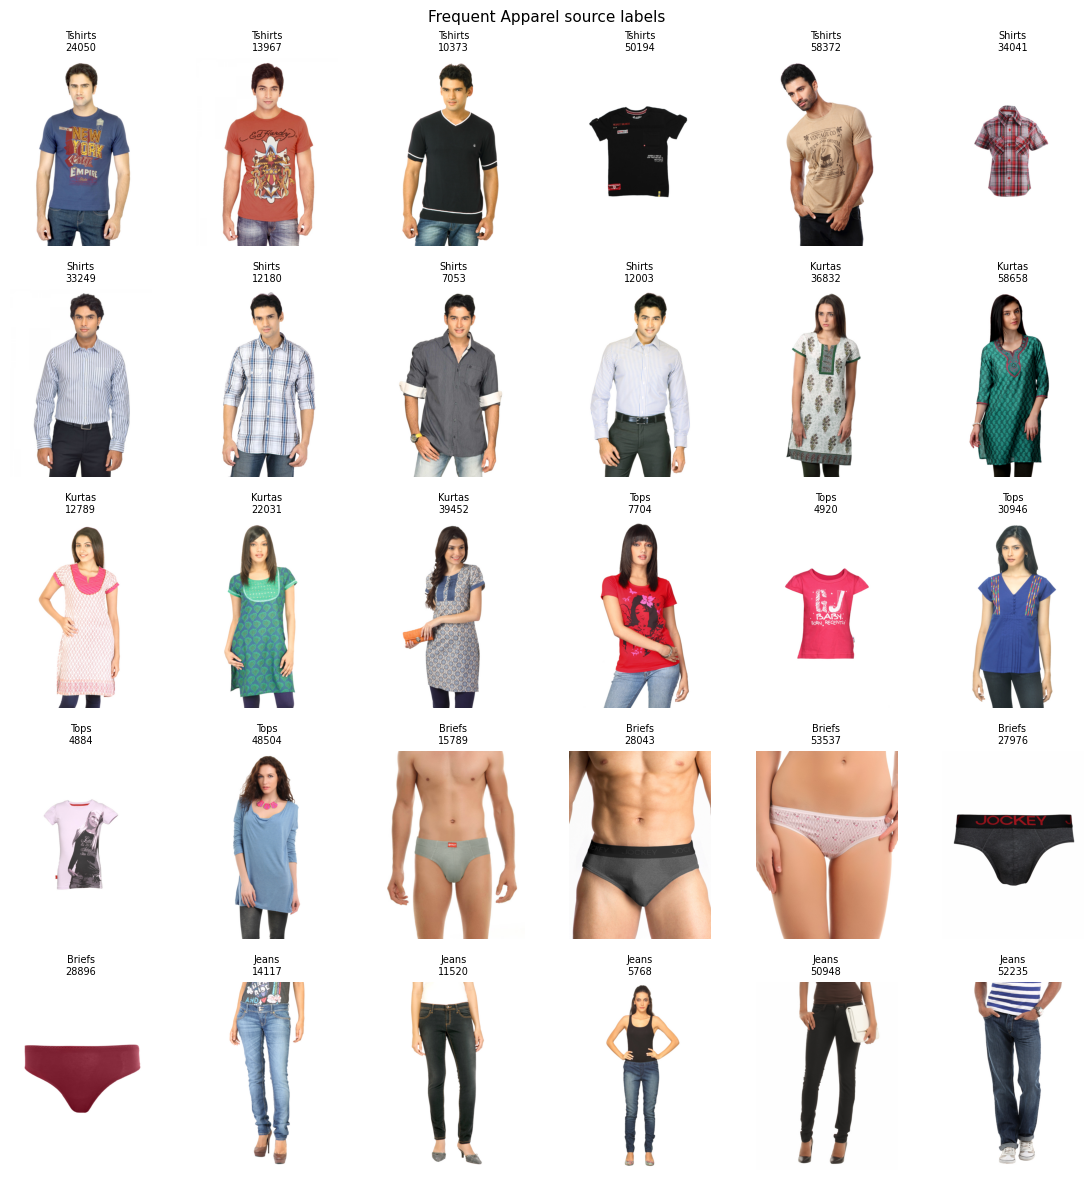

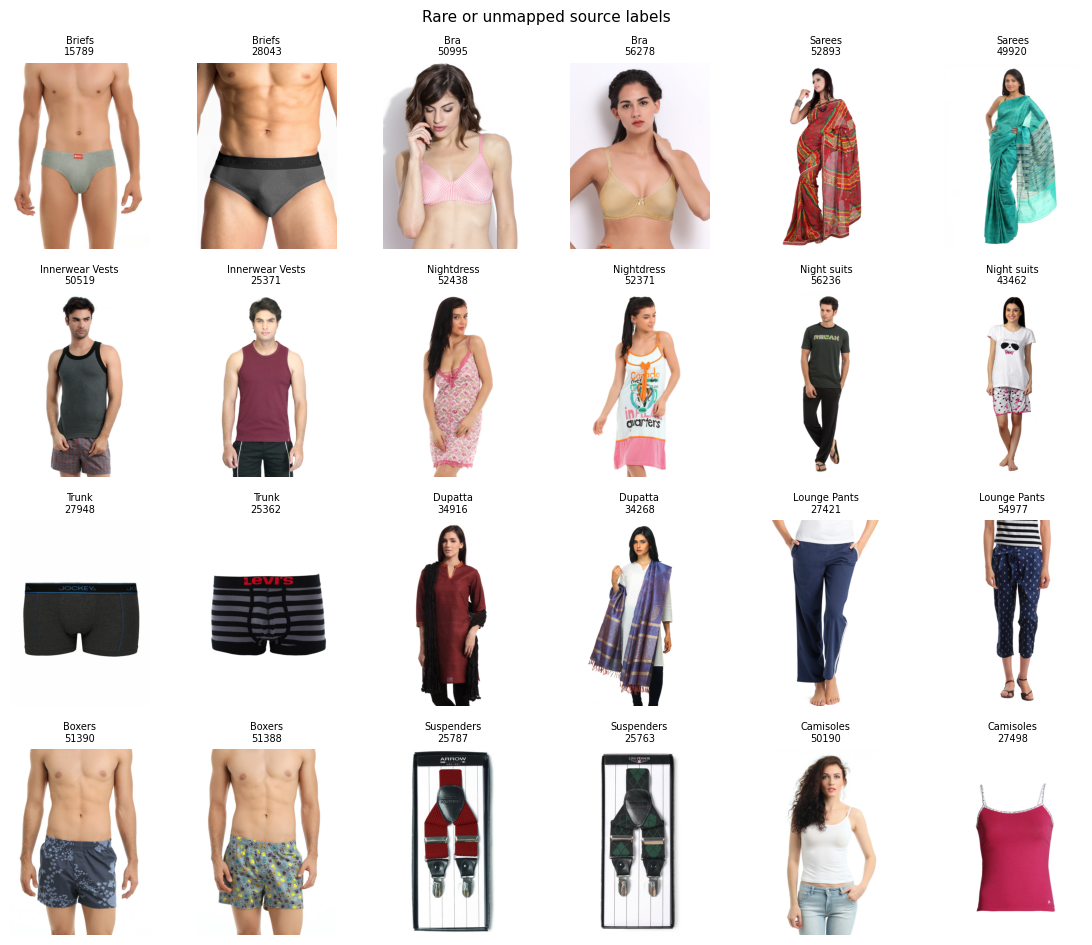

In [17]:
def show_grid(df, title, ncols=6, label_col="articleType", n=None):
    df = df.head(n) if n else df
    if df.empty:
        print(f"[{title}] empty"); return
    nrows = int(np.ceil(len(df) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.9 * ncols, 2.4 * nrows))
    axes = np.atleast_1d(axes).flatten()
    for ax, (_, r) in zip(axes, df.iterrows()):
        try:
            with Image.open(r["image_path"]) as im:
                ax.imshow(im.convert("RGB"))
        except Exception as e:
            ax.text(.5, .5, type(e).__name__, ha="center", fontsize=7)
        ax.set_title(f"{r[label_col]}\n{r['id']}", fontsize=7); ax.axis("off")
    for ax in axes[len(df):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11); plt.tight_layout()
    plt.savefig(WORK / "figures" / (re.sub(r"\W+", "_", title).strip("_") + ".png"), dpi=85)
    plt.show()


freq = at_counts.head(6).index.tolist()
samp = pd.concat([apparel[(apparel["articleType"] == c) & apparel["image_ok"]]
                  .sample(min(5, int(((apparel["articleType"] == c) & apparel["image_ok"]).sum())),
                          random_state=SEED) for c in freq if (apparel["articleType"] == c).any()])
show_grid(samp, "Frequent Apparel source labels")

rare = taxonomy_tbl[taxonomy_tbl["action"].isin(["review", "exclude"])].head(12)["articleType"].tolist()
samp2 = pd.concat([apparel[(apparel["articleType"] == c) & apparel["image_ok"]]
                   .sample(min(2, int(((apparel["articleType"] == c) & apparel["image_ok"]).sum())),
                           random_state=SEED) for c in rare
                   if ((apparel["articleType"] == c) & apparel["image_ok"]).any()]) \
    if rare else pd.DataFrame()
show_grid(samp2, "Rare or unmapped source labels")

## 9. Split by class and leakage group (70/15/15), validity gates

Whole leakage groups are split per class with a fixed seed. Under the default policy a leakage group is one
exact-image group, so this is a **provisional exact-image-safe split**; the pixel-similar pairs that cross
it are counted here and their effect on validation is measured in section 14.

In [18]:
from sklearn.model_selection import train_test_split
SPLITS = ["train", "val", "test"]
f_train, f_val, f_test = CFG["split_fracs"]
assign = {}
for label, part in train_pool.groupby("label", sort=True):       # per class, whole leakage groups only
    groups = part["leak_group"].drop_duplicates().to_numpy()
    g_train, g_hold = train_test_split(groups, test_size=f_val + f_test, random_state=SEED)
    g_val, g_test = train_test_split(g_hold, test_size=f_test / (f_val + f_test), random_state=SEED)
    assign.update({g: "train" for g in g_train}); assign.update({g: "val" for g in g_val}); assign.update({g: "test" for g in g_test})
train_pool["split"] = train_pool["leak_group"].map(assign) if len(train_pool) else pd.Series(dtype=object)
assert train_pool["split"].notna().all()

counts = train_pool.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(index=SPLITS, columns=CLASSES, fill_value=0)
display(counts)
print("split shares:", train_pool["split"].value_counts(normalize=True).round(3).to_dict())
display(train_pool.groupby(["split", "label"])["leak_group"].nunique().unstack(fill_value=0)
        .reindex(index=SPLITS, columns=CLASSES, fill_value=0).rename_axis("independent groups"))

# ---- checks of THIS split (not historical statistics) ----
sp = train_pool.set_index("id")["split"].to_dict()
sa, sb = near_df["id_a"].map(sp), near_df["id_b"].map(sp)
cross = near_df[sa.notna() & sb.notna() & (sa != sb)]
NEAR_CROSS = {"near_identical_pairs_crossing_splits": int((cross["level"] == "near_identical_pixels").sum()),
              "similar_pairs_crossing_splits": int((cross["level"] == "similar_pixels").sum())}
checks = {
    "ids_unique_and_disjoint": bool(train_pool["id"].is_unique),
    "leakage_groups_crossing_splits": int((train_pool.groupby("leak_group")["split"].nunique() > 1).sum()),
    "exact_sha256_crossing_splits": int((train_pool.groupby("sha256")["split"].nunique() > 1).sum()),
    **NEAR_CROSS,
    "all_classes_in_train_and_val": bool(len(CLASSES) and (counts.loc[["train", "val"]] > 0).all().all()),
    "all_classes_in_test": bool(len(CLASSES) and (counts.loc["test"] > 0).all()),
    "min_class_rows_val": int(counts.loc["val"].min()) if len(CLASSES) else 0,
}
display(pd.Series(checks).to_frame("value"))
assert checks["leakage_groups_crossing_splits"] == 0 and checks["exact_sha256_crossing_splits"] == 0, "split leaks"

protocol = "exact_sha256_only_provisional" if CFG["near_dup_policy"] == "report" else "exact_plus_near_identical_groups"
SPLIT_FP = fp_of({"protocol": protocol, "taxonomy": TAX_FP, "rows": sorted(zip(train_pool["id"], train_pool["split"]))})
SPLIT_ASSURANCE = ("PROVISIONAL: exact SHA-256 copies never cross splits; near-duplicates are measured, not removed "
                   f"({NEAR_CROSS['near_identical_pairs_crossing_splits']} near-identical and "
                   f"{NEAR_CROSS['similar_pairs_crossing_splits']} similar-pixel pairs cross splits; search coverage {COVERAGE})"
                   if CFG["near_dup_policy"] == "report" else
                   f"exact copies and near-identical pairs are grouped; search coverage {COVERAGE}; product identity is not established")
print("split assurance:", SPLIT_ASSURANCE)
train_pool[["id", "label", "label_idx", "leak_group", "split", "image_relpath", "sha256", "articleType"]] \
    .to_csv(WORK / "splits" / "split_manifest.csv", index=False)
(WORK / "splits" / "split_meta.json").write_text(json.dumps(
    {"fingerprint": SPLIT_FP, "protocol": protocol, "taxonomy_fingerprint": TAX_FP, "fracs": CFG["split_fracs"],
     "seed": SEED, "checks": checks, "assurance": SPLIT_ASSURANCE, "near_duplicate_search": COVERAGE_DETAIL,
     "n": train_pool["split"].value_counts().to_dict()}, indent=2, default=str), encoding="utf-8")
print("split fingerprint:", SPLIT_FP, "(stored in split_meta.json, every model bundle and every experiment fingerprint)")
set_status("split", "provisional" if CFG["near_dup_policy"] == "report" else "measured",
           f"fp={SPLIT_FP}, protocol={protocol}, catalog test held closed")

# ---- validity gates for everything downstream. A blocked stage is reported, never downgraded ----
AUDIT_SECONDS = time.time() - T_RUN0
GATES = {"torch_and_sklearn": TORCH_OK, "pool_ok": POOL_OK, "split_ok": checks["all_classes_in_train_and_val"]}
DATA_OK = all(GATES.values())
display(pd.Series(GATES).to_frame("passed"))
if not DATA_OK:
    print(f"MODEL STAGES BLOCKED by {[k for k, v in GATES.items() if not v]}"
          + (f" ({TORCH_ERR})" if not TORCH_OK else "") +
          ". Training on data with this defect would produce numbers that look fine and mean nothing.")
print(f"audit phase: {AUDIT_SECONDS/60:.1f} min (reported separately from the model budget)")

# Defaults so every later cell and the final report work on every path.
RESULTS, VALPREDS, HISTORY, SELECTED, exp_df = [], {}, {}, None, pd.DataFrame()
MODELS_OK, TRAIN_OK, PRETRAINED, IMPORTED = False, False, {}, set()
SEED_STABILITY = {"status": "not_measured"}
REVIEW_POLICY = {"review_threshold": None, "always_review": True, "score_type": "uncalibrated_softmax",
                 "status": "provisional — no validated threshold; every prediction needs user review"}
DESC_STATUS, VLM_STATUS = "skipped", "skipped"
ATTR, LEAK_DIAG, SELFTEST = {"status": "skipped"}, {"status": "not_measured"}, {"status": "skipped"}
DRESSME_DEV = {"status": "absent", "note": "no development photos supplied — NOT a passed evaluation"}
FINAL = {"catalog_test": "pending", "dressme_final": "pending"}
VERIFY, ONNX_STATUS, PIXEL_CACHE_SECONDS = {"status": "skipped"}, "disabled", 0.0

label,dress,jacket,jeans,shirt,shorts,skirt,sweater,sweatshirt,t-shirt,top,trousers
split,,,,,,,,,,,
train,327,179,421,2249,385,88,193,200,4931,1239,583
val,67,38,91,476,83,21,42,42,1061,263,126
test,70,41,96,490,78,19,42,43,1073,259,125


split shares: {'train': 0.699, 'test': 0.151, 'val': 0.15}


label,dress,jacket,jeans,shirt,shorts,skirt,sweater,sweatshirt,t-shirt,top,trousers
independent groups,,,,,,,,,,,
train,307,178,410,2050,349,79,193,198,4806,1166,582
val,66,38,88,439,75,17,42,42,1030,250,125
test,66,39,89,440,75,18,42,43,1031,250,125


,value
ids_unique_and_disjoint,True
leakage_groups_crossing_splits,0
exact_sha256_crossing_splits,0
near_identical_pairs_crossing_splits,457
similar_pairs_crossing_splits,17588
all_classes_in_train_and_val,True
all_classes_in_test,True
min_class_rows_val,21


split assurance: PROVISIONAL: exact SHA-256 copies never cross splits; near-duplicates are measured, not removed (457 near-identical and 17588 similar-pixel pairs cross splits; search coverage partial)
split fingerprint: f7f11d3ef7d2963e (stored in split_meta.json, every model bundle and every experiment fingerprint)
[PROVISIONAL] split — fp=f7f11d3ef7d2963e, protocol=exact_sha256_only_provisional, catalog test held closed


,passed
torch_and_sklearn,True
pool_ok,True
split_ok,True


audit phase: 15.0 min (reported separately from the model budget)


## 10. Preprocessing and training-data EDA

Pad-to-square then resize keeps the whole garment (a centre crop would cut sleeves and hems, which
define the category). The same evaluation pipeline serves every architecture and the exported
`inference.py`. Augmentation is mild: horizontal flip, ±8° rotation, light colour jitter; none on
validation/test. EDA below uses training data only.

In [19]:
PREPROCESS = {"version": "pad-resize-v2", "image_size": CFG["image_size"], "pad_to_square": True,
              "pad_fill": CFG["pad_fill"], "resize": "bilinear, antialias", "to_rgb": True,
              "exif_transpose": CFG["exif_transpose"],
              "mean": CFG["normalize_mean"], "std": CFG["normalize_std"],
              "eval_pipeline": "exif_transpose -> RGB -> pad to square -> resize SxS -> ToTensor -> Normalize",
              "train_augment": "hflip 0.5, rotation +-8deg @0.3, colour jitter (0.15, 0.10, 0.10)",
              "note": "identical for every architecture; no centre crop"}
PIX_PATH = None
if not DATA_OK:
    set_status("preprocessing", "skipped", "blocked by validity gates")
else:
    S = CFG["image_size"]

    class PadSquare:
        """Pad to a square canvas so the resize never distorts or crops the garment."""
        def __init__(self, fill):
            self.fill = tuple(fill)
        def __call__(self, im):
            w, h = im.size
            if w == h:
                return im
            side = max(w, h)
            canvas = Image.new("RGB", (side, side), self.fill)
            canvas.paste(im, ((side - w) // 2, (side - h) // 2))
            return canvas

    def load_rgb(path):
        with Image.open(path) as im:
            if CFG["exif_transpose"]:
                im = ImageOps.exif_transpose(im)
            return im.convert("RGB")

    _pad = PadSquare(CFG["pad_fill"])
    _resize = transforms.Resize((S, S), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True)
    def to_canvas(im):                       # PIL RGB -> PIL RGB, S x S (deterministic)
        return _resize(_pad(im))
    TO_TENSOR = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(CFG["normalize_mean"], CFG["normalize_std"])])
    def EVAL_TF(im):                         # the one evaluation pipeline, also used by inference.py
        return TO_TENSOR(to_canvas(im))
    TRAIN_AUG = transforms.Compose([         # mild and semantically safe; applied to the canvas
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomApply([transforms.RandomRotation(8, fill=tuple(CFG["pad_fill"]))], p=0.3),
        transforms.ColorJitter(brightness=0.15, contrast=0.10, saturation=0.10)])

    # ---- pixel cache: decode + pad + resize once instead of every epoch (lossless uint8) ----
    ROW_OF = {pid: i for i, pid in enumerate(train_pool["id"])}
    if CFG["pixel_cache"]:
        pdir = Path(CFG["pixel_cache_dir"]) if CFG["pixel_cache_dir"] else (
            Path("/kaggle/temp/bo6_cache") if Path("/kaggle").is_dir() else WORK / "cache")
        try:
            pdir.mkdir(parents=True, exist_ok=True)
            pix_fp = fp_of({"pre": PREPROCESS["version"], "S": S, "fill": CFG["pad_fill"],
                            "exif": CFG["exif_transpose"],
                            "rows": list(zip(train_pool["id"], train_pool["sha256"]))})
            cand, done = pdir / f"pixels_{pix_fp}.npy", pdir / f"pixels_{pix_fp}.done"
            need = len(train_pool) * S * S * 3
            if done.exists() and cand.exists():
                PIX_PATH = cand
                print(f"pixel cache reused: {cand.name} ({need/1e9:.2f} GB)")
            elif shutil.disk_usage(pdir).free < need * 1.2:
                print(f"pixel cache skipped: needs {need/1e9:.2f} GB, not enough free space in {pdir}")
            else:
                t0 = time.time()
                arr = np.lib.format.open_memmap(cand, mode="w+", dtype=np.uint8, shape=(len(train_pool), S, S, 3))
                paths = train_pool["image_path"].tolist()
                def _fill(i):
                    arr[i] = np.asarray(to_canvas(load_rgb(paths[i])))
                with ThreadPoolExecutor(max_workers=min(8, (os.cpu_count() or 2) * 2)) as pool:
                    list(pool.map(_fill, range(len(paths)), chunksize=32))
                arr.flush(); del arr
                done.write_text("ok")
                PIX_PATH, PIXEL_CACHE_SECONDS = cand, time.time() - t0
                print(f"pixel cache built: {len(paths):,} images, {need/1e9:.2f} GB, {PIXEL_CACHE_SECONDS/60:.1f} min")
        except OSError as e:
            PIX_PATH = None
            print("pixel cache unavailable, decoding on the fly instead:", e)
    if PIX_PATH is None:
        print("images are decoded from the source files every epoch (slower, same pixels)")

    class GarmentDS(Dataset):
        def __init__(self, df, train):
            self.paths = df["image_path"].tolist()
            self.labels = df["label_idx"].astype(int).tolist()
            self.ids = df["id"].tolist()
            self.rows = [ROW_OF[i] for i in self.ids]
            self.train, self.arr = train, None
        def __len__(self):
            return len(self.ids)
        def __getitem__(self, i):
            if PIX_PATH is not None:
                if self.arr is None:                      # opened lazily, once per worker
                    self.arr = np.load(PIX_PATH, mmap_mode="r")
                im = Image.fromarray(np.array(self.arr[self.rows[i]]))
            else:
                im = to_canvas(load_rgb(self.paths[i]))
            if self.train:
                im = TRAIN_AUG(im)
            return TO_TENSOR(im), self.labels[i], self.ids[i]

    def loader(split, train, shuffle, bs=None):
        df = train_pool[train_pool["split"] == split]
        return DataLoader(GarmentDS(df, train), batch_size=bs or CFG["batch_size"], shuffle=shuffle,
                          num_workers=CFG["num_workers"], pin_memory=(DEVICE == "cuda"),
                          drop_last=False, persistent_workers=CFG["num_workers"] > 0)

    train_loader, val_loader = loader("train", True, True), loader("val", False, False)
    # The cached pixels must equal the on-the-fly evaluation pipeline exactly.
    _p = train_pool[train_pool["split"] == "val"].iloc[0]
    assert torch.equal(val_loader.dataset[0][0], EVAL_TF(load_rgb(_p["image_path"]))), "pixel cache != EVAL_TF"
    print(f"train {len(train_loader.dataset):,} | val {len(val_loader.dataset):,} | "
          f"test {int((train_pool['split'] == 'test').sum()):,} (held closed)")
    set_status("preprocessing", "measured", f"{S}px pad+resize, pixel cache {'on' if PIX_PATH else 'off'}")

pixel cache built: 15,441 images, 2.32 GB, 5.6 min
train 10,795 | val 2,310 | test 2,336 (held closed)
[MEASURED] preprocessing — 224px pad+resize, pixel cache on


train class imbalance ratio (max/min): 56.0
class weights ON (inverse frequency ^ 0.5, no balanced sampler): {'dress': np.float32(1.04), 'jacket': np.float32(1.41), 'jeans': np.float32(0.92), 'shirt': np.float32(0.4), 'shorts': np.float32(0.96), 'skirt': np.float32(2.01), 'sweater': np.float32(1.36), 'sweatshirt': np.float32(1.33), 't-shirt': np.float32(0.27), 'top': np.float32(0.53), 'trousers': np.float32(0.78)}


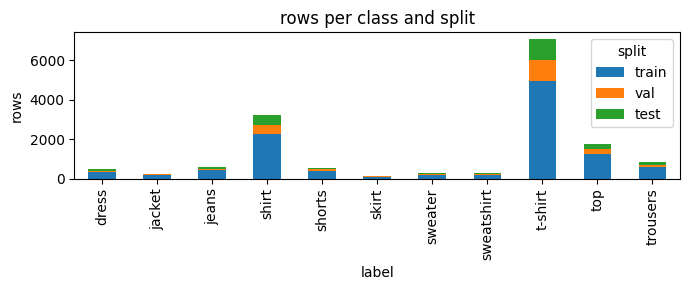

batch (32, 3, 224, 224) torch.float32 | range [-2.12,2.64] | labels [8, 9, 3, 8, 8, 8, 9, 8]


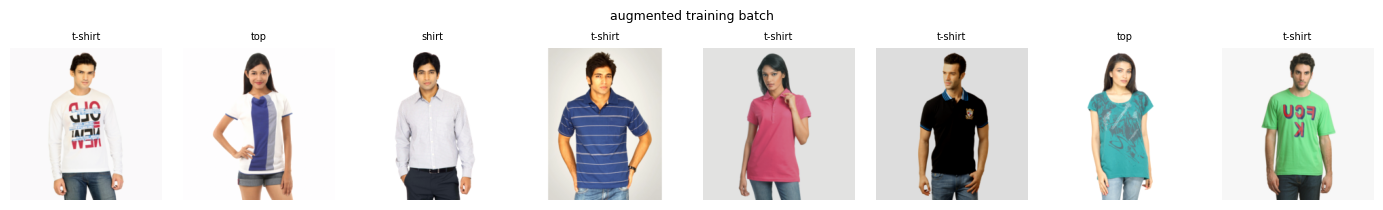

In [20]:
CLASS_WEIGHTS = None
if DATA_OK:
    tr_df = train_pool[train_pool["split"] == "train"]          # training data only
    vc = tr_df["label"].value_counts().reindex(CLASSES, fill_value=0)
    imbalance = float(vc.max() / max(vc.min(), 1))
    print(f"train class imbalance ratio (max/min): {imbalance:.1f}")
    if CFG["class_weighting"] == "always" or (CFG["class_weighting"] == "auto"
                                              and imbalance > CFG["imbalance_ratio_threshold"]):
        w = (vc.sum() / (len(CLASSES) * vc.clip(lower=1))) ** CFG["class_weight_power"]
        w = (w / w.mean()).to_numpy(dtype=np.float32)
        CLASS_WEIGHTS = torch.tensor(w)
        print(f"class weights ON (inverse frequency ^ {CFG['class_weight_power']}, no balanced sampler):",
              dict(zip(CLASSES, w.round(2))))
    else:
        print("class weighting OFF — imbalance below threshold or disabled")

    fig, ax = plt.subplots(figsize=(7, 3))
    train_pool.groupby(["label", "split"]).size().unstack(fill_value=0)[SPLITS].plot(kind="bar", stacked=True, ax=ax)
    ax.set_title("rows per class and split"); ax.set_ylabel("rows")
    plt.tight_layout(); plt.savefig(WORK / "figures" / "class_split_distribution.png", dpi=90); plt.show()

    xb, yb, idb = next(iter(train_loader))
    assert xb.shape[1:] == (3, S, S) and xb.dtype == torch.float32 and torch.isfinite(xb).all()
    assert int(yb.min()) >= 0 and int(yb.max()) < len(CLASSES)
    print(f"batch {tuple(xb.shape)} {xb.dtype} | range [{xb.min():.2f},{xb.max():.2f}] | labels {yb[:8].tolist()}")
    k = min(8, len(xb))
    inv = xb[:k] * torch.tensor(CFG["normalize_std"]).view(1, 3, 1, 1) + torch.tensor(CFG["normalize_mean"]).view(1, 3, 1, 1)
    fig, axes = plt.subplots(1, k, figsize=(1.75 * k, 2.1), squeeze=False)
    for a, img, lab in zip(axes[0], inv, yb[:k]):
        a.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy()); a.set_title(CLASSES[int(lab)], fontsize=7); a.axis("off")
    fig.suptitle("augmented training batch", fontsize=9)
    plt.tight_layout(); plt.savefig(WORK / "figures" / "augmented_batch.png", dpi=90); plt.show()

## 11. Model factory, smoke tests, trivial baseline

Pretrained weights resolve as: configured local file (strict load) → torchvision download → stop
with instructions. Random initialisation is never a silent fallback: it is allowed in SMOKE mode
only, and every such run is tagged `smoke_only`.

In [21]:
# Explicit pretrained identifiers (not ".DEFAULT", which can change between torchvision versions).
WEIGHT_ID = {"resnet18": ("ResNet18_Weights", "IMAGENET1K_V1"),
             "mobilenet_v3_small": ("MobileNet_V3_Small_Weights", "IMAGENET1K_V1"),
             "efficientnet_b0": ("EfficientNet_B0_Weights", "IMAGENET1K_V1")}
LAST_BLOCKS = {"resnet18": ["layer4", "fc"],
               "mobilenet_v3_small": ["features.9", "features.10", "features.11", "features.12", "classifier"],
               "efficientnet_b0": ["features.6", "features.7", "features.8", "classifier"]}
HEAD_NAMES = ("fc", "classifier")
_DL_FAIL = {}

if TORCH_OK:
    def load_backbone(arch):
        """Return (model with ImageNet head, source string, pretrained: bool). Never silent."""
        cls, name = WEIGHT_ID[arch]
        local = CFG["local_weights"].get(arch)
        if local:
            if not Path(local).is_file():
                raise RuntimeError(f"CFG['local_weights']['{arch}'] = {local} does not exist.")
            sd = torch.load(local, map_location="cpu", weights_only=True)
            for key in ("state_dict", "model"):
                if isinstance(sd, dict) and key in sd and isinstance(sd[key], dict):
                    sd = sd[key]
            m = tvm.get_model(arch, weights=None)
            try:
                m.load_state_dict(sd, strict=True)       # a wrong file must fail, not load nothing
            except RuntimeError as e:
                raise RuntimeError(f"{local} is not a torchvision {arch} ImageNet checkpoint: "
                                   f"{str(e)[:300]}") from None
            return m, f"local:{Path(local).name} sha256={sha256_file(local)[:12]}", True
        reason = "download_disabled"
        if CFG["allow_weight_download"] and arch not in _DL_FAIL:
            try:
                return tvm.get_model(arch, weights=getattr(getattr(tvm, cls), name)), f"torchvision:{cls}.{name}", True
            except Exception as e:                       # no internet, blocked host, bad hash...
                _DL_FAIL[arch] = f"download_failed({type(e).__name__})"
        reason = _DL_FAIL.get(arch, reason)
        if not CFG["allow_random_init"]:
            raise RuntimeError(
                f"No pretrained weights for {arch} [{reason}]. Either enable Internet in the notebook "
                f"settings, or attach the torchvision checkpoint for {cls}.{name} as an input and set "
                f"CFG['local_weights']['{arch}'] = '<path to .pth>'. Refusing to train from random init.")
        return tvm.get_model(arch, weights=None), f"{reason} -> RANDOM INIT (smoke only)", False

    def replace_head(m, n_classes):
        if hasattr(m, "fc"):
            m.fc = nn.Linear(m.fc.in_features, n_classes)
        elif isinstance(m.classifier, nn.Sequential):
            m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n_classes)
        else:
            m.classifier = nn.Linear(m.classifier.in_features, n_classes)
        return m

    def build_model(arch, n_classes):
        m, src, pretrained = load_backbone(arch)
        return replace_head(m, n_classes), src, pretrained

    def freeze_backbone(model):
        for name, p in model.named_parameters():
            p.requires_grad = name.split(".")[0] in HEAD_NAMES
    def unfreeze_last(model, arch):
        for name, p in model.named_parameters():
            p.requires_grad = any(name == x or name.startswith(x + ".") for x in LAST_BLOCKS[arch])
    def frozen_bn_eval(model):
        """Call after model.train(): BatchNorm layers whose parameters are frozen must not update
        their running statistics, in the head phase AND in the still-frozen early blocks later."""
        for mod in model.modules():
            if isinstance(mod, nn.modules.batchnorm._BatchNorm):
                ps = list(mod.parameters())
                if ps and not any(p.requires_grad for p in ps):
                    mod.eval()

    for arch in CFG["architectures"]:
        try:
            _m, src, pre = load_backbone(arch)
            PRETRAINED[arch] = {"ok": True, "pretrained": pre, "source": src}
            del _m
        except RuntimeError as e:
            PRETRAINED[arch] = {"ok": False, "pretrained": False, "source": str(e)}
            print("PRETRAINED WEIGHTS UNAVAILABLE:", e)
    display(pd.DataFrame(PRETRAINED).T)
    MODELS_OK = all(v["ok"] for v in PRETRAINED.values())
    if any(v["ok"] and not v["pretrained"] for v in PRETRAINED.values()):
        print("Random initialisation is in use (SMOKE only): every such run is tagged smoke_only "
              "and is not a transfer-learning result.")
TRAIN_OK = DATA_OK and MODELS_OK and CFG["run_training"]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 135MB/s]


,ok,pretrained,source
resnet18,True,True,torchvision:ResNet18_Weights.IMAGENET1K_V1
mobilenet_v3_small,True,True,torchvision:MobileNet_V3_Small_Weights.IMAGENE...


In [22]:
def evaluate(model, dl, device, collect=False):
    model.eval()
    Y, S_, I = [], [], []
    with torch.no_grad():
        for xb, yb, idb in dl:
            S_.append(model(xb.to(device, non_blocking=True)).float().softmax(1).cpu())
            Y.append(yb); I.extend(idb)
    y, s = torch.cat(Y).numpy(), torch.cat(S_).numpy()
    return metrics_from(y, s), ({"ids": list(I), "y": y, "pred": s.argmax(1), "scores": s} if collect else None)

def metrics_from(y, s, labels=None):
    p = s.argmax(1)
    labels = list(range(s.shape[1])) if labels is None else labels    # classes the macro average covers
    res = {"macro_f1": float(f1_score(y, p, labels=labels, average="macro", zero_division=0)),
           "weighted_f1": float(f1_score(y, p, labels=labels, average="weighted", zero_division=0)),
           "accuracy": float(accuracy_score(y, p))}
    if s.shape[1] > 2:
        res["top2_accuracy"] = float((np.argsort(-s, axis=1)[:, :2] == y[:, None]).any(1).mean())
    return res

if DATA_OK and MODELS_OK:
    # ---- smoke test: plumbing only. None of these numbers are model results. ----
    arch0 = CFG["architectures"][0]
    sm, _, _ = build_model(arch0, len(CLASSES))
    sm = sm.to(DEVICE)
    xb, yb, _ = next(iter(train_loader))
    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
    bn_means = lambda m: {n: b.clone() for n, b in m.named_buffers() if n.endswith("running_mean")}

    # (1) head phase: finite loss/gradients, and NO BatchNorm statistic may move
    freeze_backbone(sm); sm.train(); frozen_bn_eval(sm)
    before = bn_means(sm)
    opt = torch.optim.AdamW([p for p in sm.parameters() if p.requires_grad], lr=1e-3)
    loss = nn.functional.cross_entropy(sm(xb), yb); loss.backward()
    gnorm = sum(float(p.grad.norm()) for p in sm.parameters() if p.grad is not None)
    assert torch.isfinite(loss) and np.isfinite(gnorm) and gnorm > 0, "non-finite loss or no gradient"
    assert all(p.grad is None for n, p in sm.named_parameters() if n.split(".")[0] not in HEAD_NAMES)
    opt.step()
    assert all(torch.equal(v, before[n]) for n, v in bn_means(sm).items()), "frozen BatchNorm stats moved"

    # (2) fine-tune phase: only BatchNorm inside the unfrozen blocks may move
    unfreeze_last(sm, arch0); sm.train(); frozen_bn_eval(sm)
    before = bn_means(sm)
    sm(xb)
    moved = [n for n, v in bn_means(sm).items() if not torch.equal(v, before[n])]
    assert all(any(n.startswith(x + ".") for x in LAST_BLOCKS[arch0]) for n in moved), moved
    print(f"BatchNorm check: head phase 0 layers updated; fine-tune phase {len(moved)} "
          f"(all inside {LAST_BLOCKS[arch0][:-1]})")

    # (3) validation inference on a few batches, (4) checkpoint save/reload
    vdf = train_pool[train_pool["split"] == "val"].head(4 * CFG["batch_size"])
    vres, _ = evaluate(sm, DataLoader(GarmentDS(vdf, False), batch_size=CFG["batch_size"]), DEVICE)
    ck = WORK / "cache" / "smoke_ckpt.pt"
    torch.save({"state_dict": sm.state_dict()}, ck)
    sm2, _, _ = build_model(arch0, len(CLASSES))
    sm2.load_state_dict(torch.load(ck, map_location="cpu", weights_only=True)["state_dict"])
    sm2 = sm2.to(DEVICE).eval(); sm.eval()
    with torch.no_grad():
        d = float((sm(xb[:4]) - sm2(xb[:4])).abs().max())
    assert d < 1e-5, "checkpoint round-trip changed the model"
    ck.unlink()
    print(f"smoke: loss={loss.item():.4f} grad_norm={gnorm:.2f} val-subset macro-F1={vres['macro_f1']:.3f} "
          f"checkpoint reload max|diff|={d:.1e}")
    del sm, sm2, opt, xb, yb
    set_status("smoke_test", "measured", "forward/backward, BatchNorm freezing, eval, checkpoint round-trip")
    print("Smoke numbers are plumbing checks, not model results.")
else:
    set_status("smoke_test", "skipped", "blocked by validity gates or missing pretrained weights")

BatchNorm check: head phase 0 layers updated; fine-tune phase 5 (all inside ['layer4'])
smoke: loss=2.6418 grad_norm=12.99 val-subset macro-F1=0.101 checkpoint reload max|diff|=0.0e+00
[MEASURED] smoke_test — forward/backward, BatchNorm freezing, eval, checkpoint round-trip
Smoke numbers are plumbing checks, not model results.


In [23]:
# Trivial baseline: always predict the training majority class.
BASELINE = None
if DATA_OK:
    maj = int(train_pool[train_pool["split"] == "train"]["label_idx"].value_counts().idxmax())
    yv = train_pool[train_pool["split"] == "val"]["label_idx"].to_numpy()
    sv = np.zeros((len(yv), len(CLASSES)), dtype=np.float32); sv[:, maj] = 1.0
    mb = metrics_from(yv, sv)
    BASELINE = {"experiment_id": "E00_majority", "architecture": "majority_class", "pretrained": "n/a",
                "strategy": "always predict the training majority class", "status": "measured",
                "smoke_only": False, "epochs_completed": 0, "seed": SEED,
                "val_macro_f1": mb["macro_f1"], "val_weighted_f1": mb["weighted_f1"],
                "val_accuracy": mb["accuracy"], "note": f"always predicts '{CLASSES[maj]}'"}
    print(f"majority baseline ('{CLASSES[maj]}'): macro-F1 {mb['macro_f1']:.4f} | accuracy {mb['accuracy']:.4f}")
    print("A trained model must clearly beat this to be worth anything.")

majority baseline ('t-shirt'): macro-F1 0.0572 | accuracy 0.4593
A trained model must clearly beat this to be worth anything.


## 12. Transfer-learning experiments

Per candidate: (1) train the new head with the backbone and its BatchNorm statistics frozen;
(2) fine-tune the last blocks with a lower backbone learning rate. Cross-entropy, AdamW, cosine schedule
per phase, early stopping on validation macro-F1, best checkpoint kept, budget checked before every epoch.
Finished runs are reused; `import_previous_run` brings in an earlier run's experiments, which are accepted
only if their fingerprint matches this run's split, taxonomy, preprocessing and hyper-parameters.

In [24]:
class Budget:
    def __init__(self, minutes):
        self.total, self.t0 = minutes * 60, time.time()
    def left(self):
        return self.total - (time.time() - self.t0)
    def afford(self, seconds, margin=1.15):
        return self.left() > seconds * margin
    def report(self):
        return f"{(time.time() - self.t0)/60:.1f} of {self.total/60:g} min used"

BUDGET = Budget(CFG["budget_minutes"])        # the model-experiment clock starts here
print(f"audit {AUDIT_SECONDS/60:.1f} min + pixel cache {PIXEL_CACHE_SECONDS/60:.1f} min are outside the "
      f"{CFG['budget_minutes']} min experiment budget")

# Optional: bring in the finished experiments of an earlier run instead of retraining them.
if CFG["import_previous_run"] and TRAIN_OK:
    root_ = INPUT_ROOT if CFG["import_previous_run"] == "auto" else Path(CFG["import_previous_run"])
    cands = [p.parent for p in root_.rglob("models") if p.is_dir() and (p.parent / "experiments").is_dir()]
    if not cands:
        raise FileNotFoundError(f"{CFG['import_previous_run']} has no folder containing both models/ and experiments/")
    src = sorted(cands, key=lambda p: len(p.parts))[0]
    for d in sorted(p for p in (src / "models").iterdir() if (p / "result.json").is_file() and (p / "model_weights.pt").is_file()):
        dst = WORK / "models" / d.name
        if not (dst / "result.json").exists():
            dst.mkdir(parents=True, exist_ok=True)
            for f in ("result.json", "model_weights.pt"):
                shutil.copy(d / f, dst / f)
            for f in (src / "experiments").glob(f"*_{d.name}.*"):
                shutil.copy(f, WORK / "experiments" / f.name)
            IMPORTED.add(d.name)
    print(f"imported {len(IMPORTED)} finished experiment(s) from {src}: {sorted(IMPORTED)}")
    print("Each is reused only if its fingerprint (split, taxonomy, preprocessing, hyper-parameters) matches this run.")

DEFAULT_HP = {k: CFG[k] for k in ["lr_head", "lr_head_finetune", "lr_backbone", "weight_decay",
                                  "label_smoothing", "head_epochs", "finetune_epochs",
                                  "early_stop_patience", "batch_size"]}

def run_epoch(model, dl, crit, opt, scaler):
    model.train()
    frozen_bn_eval(model)                     # frozen blocks keep their BatchNorm statistics
    amp = DEVICE == "cuda" and AMP_DTYPE is not None
    dt = torch.bfloat16 if AMP_DTYPE == "bfloat16" else torch.float16
    tot, n = 0.0, 0
    for xb, yb, _ in dl:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=dt, enabled=amp):
            loss = crit(model(xb), yb)
        if not torch.isfinite(loss):
            raise FloatingPointError("non-finite training loss — lower the learning rate or disable AMP")
        if scaler.is_enabled():
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else:
            loss.backward(); opt.step()
        tot += loss.item() * xb.size(0); n += xb.size(0)
    return tot / max(n, 1)

@torch.no_grad()
def bench_latency(model, device, reps=20, warmup=5):
    """Model forward only, batch 1, ms per image. Preprocessing is measured separately at export."""
    m = copy.deepcopy(model).to(device).eval()
    x = torch.randn(1, 3, CFG["image_size"], CFG["image_size"], device=device)
    for _ in range(warmup):
        m(x)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        m(x)
    if device == "cuda":
        torch.cuda.synchronize()
    return round((time.perf_counter() - t0) / reps * 1000, 2)

def load_trained(row):
    m, _, _ = build_model(row["architecture"], len(CLASSES))   # backbone values are overwritten below
    m.load_state_dict(torch.load(row["checkpoint"], map_location="cpu", weights_only=True)["state_dict"], strict=True)
    return m.to(DEVICE).eval()

audit 15.0 min + pixel cache 5.6 min are outside the 150 min experiment budget


In [25]:
def train_experiment(exp_id, arch, hp_over=None, seed=None, note=""):
    """One transfer-learning run. Returns (result row, validation predictions or None)."""
    hp = {**DEFAULT_HP, **(hp_over or {})}
    seed = SEED if seed is None else seed
    fp = fp_of({"arch": arch, "hp": hp, "seed": seed, "split": SPLIT_FP, "tax": TAX_FP, "pre": PREPROCESS,
                "weights": [WEIGHT_ID[arch], CFG["local_weights"].get(arch), CFG["allow_random_init"]],
                "class_weights": None if CLASS_WEIGHTS is None else CLASS_WEIGHTS.tolist(), "mode": MODE})
    ckpt_dir = WORK / "models" / exp_id
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    res_path, pred_path = ckpt_dir / "result.json", WORK / "experiments" / f"valpreds_{exp_id}.npz"
    hist_path = WORK / "experiments" / f"history_{exp_id}.csv"
    row = {"experiment_id": exp_id, "architecture": arch, "seed": seed, "note": note, "status": "failed",
           "smoke_only": False, "epochs_completed": 0, "fingerprint": fp,
           "strategy": f"head {hp['head_epochs']}ep (frozen backbone+BN) -> last blocks {hp['finetune_epochs']}ep",
           "hyperparams": json.dumps(hp), "class_weighting": CLASS_WEIGHTS is not None}

    # A finished run with the same fingerprint (data, taxonomy, config) is reused, not retrained.
    if CFG["resume"] and res_path.exists() and pred_path.exists() and (ckpt_dir / "model_weights.pt").exists():
        saved = json.loads(res_path.read_text())
        if saved.get("fingerprint") == fp and saved.get("complete"):   # budget-stopped runs resume instead
            z = np.load(pred_path)
            HISTORY[exp_id] = pd.read_csv(hist_path)
            origin = "imported from the previous run" if exp_id in IMPORTED else "reused completed run"
            print(f"  [{exp_id}] {origin} (fingerprint {fp}) — not retrained")
            return ({**saved, "reused": True, "checkpoint": str(ckpt_dir / "model_weights.pt"),
                     "note": (saved.get("note", "") + f" | {origin}").strip(" |")},
                    {"ids": z["ids"].tolist(), "y": z["y"], "pred": z["pred"], "scores": z["scores"]})
        if exp_id in IMPORTED and CFG["on_import_mismatch"] == "stop":
            raise RuntimeError(
                f"Imported experiment {exp_id} has fingerprint {saved.get('fingerprint')} but this run computes {fp}: the "
                f"split, taxonomy, preprocessing or hyper-parameters differ, so its weights and metrics do not belong to "
                f"this data. Compare splits/split_meta.json of both runs, or set CFG['on_import_mismatch']='retrain'.")

    bs = hp["batch_size"]
    while True:
        try:
            return _fit(row, arch, hp, seed, bs, fp, ckpt_dir, res_path, pred_path, hist_path)
        except torch.cuda.OutOfMemoryError:           # explicit, recorded, never silent
            gc.collect(); torch.cuda.empty_cache()
            if bs <= 4:
                row.update(status="failed", note=(note + f" | CUDA out of memory even at batch_size={bs}").strip(" |"))
                return row, None
            bs //= 2
            row["note"] = (row["note"] + f" | OOM: batch_size reduced to {bs} (not comparable 1:1)").strip(" |")
            print(f"  [{exp_id}] CUDA out of memory -> retrying with batch_size={bs}")


def _fit(row, arch, hp, seed, bs, fp, ckpt_dir, res_path, pred_path, hist_path):
    exp_id = row["experiment_id"]
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model, src, pretrained = build_model(arch, len(CLASSES))
    model = model.to(DEVICE)
    row.update(pretrained=src, smoke_only=not pretrained, batch_size_effective=bs,
               params=int(sum(p.numel() for p in model.parameters())))
    tl, vl = loader("train", True, True, bs), loader("val", False, False, bs)
    crit = nn.CrossEntropyLoss(weight=None if CLASS_WEIGHTS is None else CLASS_WEIGHTS.to(DEVICE),
                               label_smoothing=hp["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and AMP_DTYPE == "float16"))
    best, best_ep, hist, patience = -1.0, 0, [], hp["early_stop_patience"]
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_start, t_prior = time.time(), 0.0

    ck, last = None, ckpt_dir / "last_checkpoint.pt"
    if CFG["resume"] and last.exists():
        c = torch.load(last, map_location="cpu", weights_only=True)
        if c.get("fingerprint") == fp and c.get("batch_size") == bs:
            ck = c

    stop_reason = ""
    phases = [("head", hp["head_epochs"]), ("finetune", hp["finetune_epochs"])]
    for pi, (phase, n_ep) in enumerate(phases):
        if n_ep <= 0 or (ck is not None and pi < ck["phase_idx"]):
            continue
        if phase == "head":
            freeze_backbone(model)
            groups = [{"params": [p for p in model.parameters() if p.requires_grad], "lr": hp["lr_head"]}]
        else:
            unfreeze_last(model, arch)
            named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
            groups = [{"params": [p for n, p in named if n.split(".")[0] in HEAD_NAMES], "lr": hp["lr_head_finetune"]},
                      {"params": [p for n, p in named if n.split(".")[0] not in HEAD_NAMES], "lr": hp["lr_backbone"]}]
        opt = torch.optim.AdamW(groups, weight_decay=hp["weight_decay"])
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_ep)     # per phase, stepped per epoch
        start_ep, bad = 0, 0                           # patience restarts with each phase
        if ck is not None:                             # resume inside this phase
            model.load_state_dict(ck["state_dict"]); opt.load_state_dict(ck["optimizer"])
            sched.load_state_dict(ck["scheduler"])
            if ck["scaler"] is not None and scaler.is_enabled():
                scaler.load_state_dict(ck["scaler"])
            torch.set_rng_state(ck["torch_rng"])
            start_ep, bad, best, best_ep, hist = ck["ep_in_phase"], ck["bad"], ck["best"], ck["best_ep"], list(ck["hist"])
            t_prior = sum(h["seconds"] for h in hist)
            row["note"] = (row["note"] + f" | resumed at {phase} epoch {start_ep + 1}").strip(" |")
            print(f"  [{exp_id}] resumed from checkpoint: {len(hist)} epoch(s) already done")
            ck = None
        for ep in range(start_ep, n_ep):
            if bad >= patience:
                print(f"  [{exp_id}] {phase}: early stop (no val macro-F1 gain in {bad} epochs)")
                break
            est = float(np.median([h["seconds"] for h in hist])) if hist else 0.0
            if not BUDGET.afford(est):
                stop_reason = "budget"
                break
            t0 = time.time()
            tr_loss = run_epoch(model, tl, crit, opt, scaler)
            vres, _ = evaluate(model, vl, DEVICE)
            sched.step()
            hist.append({"phase": phase, "epoch": ep + 1, "train_loss": tr_loss, "val_macro_f1": vres["macro_f1"],
                         "val_accuracy": vres["accuracy"], "seconds": time.time() - t0,
                         "lr_head": opt.param_groups[0]["lr"], "lr_backbone": opt.param_groups[-1]["lr"]})
            print(f"  [{exp_id}] {phase} {ep + 1}/{n_ep} loss {tr_loss:.4f} val macro-F1 {vres['macro_f1']:.4f} "
                  f"({hist[-1]['seconds']:.0f}s) | {BUDGET.report()}")
            if vres["macro_f1"] > best:
                best, best_ep, bad = vres["macro_f1"], len(hist), 0
                torch.save({"state_dict": model.state_dict(), "arch": arch, "classes": CLASSES,
                            "epoch": best_ep, "val_macro_f1": best}, ckpt_dir / "model_weights.pt")
            else:
                bad += 1
            torch.save({"state_dict": model.state_dict(), "optimizer": opt.state_dict(),
                        "scheduler": sched.state_dict(),
                        "scaler": scaler.state_dict() if scaler.is_enabled() else None,
                        "phase_idx": pi, "ep_in_phase": ep + 1, "bad": bad, "best": best, "best_ep": best_ep,
                        "hist": hist, "fingerprint": fp, "batch_size": bs, "seed": seed,
                        "torch_rng": torch.get_rng_state(), "config_json": json.dumps(CFG)},
                       ckpt_dir / "last_checkpoint.pt")
        if stop_reason:
            print(f"  [{exp_id}] stopped for budget ({BUDGET.report()}) — best checkpoint kept, run is resumable")
            row["note"] = (row["note"] + " | stopped early: budget").strip(" |")
            break

    row["epochs_completed"] = len(hist)
    if not hist:
        row.update(status="skipped", note=(row["note"] + " | no epoch fitted in the budget").strip(" |"))
        return row, None
    model.load_state_dict(torch.load(ckpt_dir / "model_weights.pt", map_location=DEVICE, weights_only=True)["state_dict"])
    vres, preds = evaluate(model, vl, DEVICE, collect=True)
    rep = pd.DataFrame(classification_report(preds["y"], preds["pred"], labels=list(range(len(CLASSES))),
                                             target_names=CLASSES, output_dict=True, zero_division=0)).T
    rep.to_csv(WORK / "experiments" / f"per_class_{exp_id}.csv")
    row.update({
        "status": "measured", "complete": stop_reason == "", "train_seconds": round(t_prior + time.time() - t_start, 1), "best_epoch": best_ep,
        "val_macro_f1": vres["macro_f1"], "val_weighted_f1": vres["weighted_f1"], "val_accuracy": vres["accuracy"],
        "val_top2_accuracy": vres.get("top2_accuracy"),
        "val_min_class_f1": float(rep.loc[CLASSES, "f1-score"].min()),
        "latency_cpu_ms": bench_latency(model, "cpu"),
        "latency_gpu_ms": bench_latency(model, "cuda") if DEVICE == "cuda" else None,
        "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1) if DEVICE == "cuda" else None,
        "artifact_mb": round((ckpt_dir / "model_weights.pt").stat().st_size / 1e6, 2),
        "checkpoint": str(ckpt_dir / "model_weights.pt")})
    HISTORY[exp_id] = pd.DataFrame(hist)
    HISTORY[exp_id].to_csv(hist_path, index=False)
    np.savez_compressed(pred_path, ids=np.array(preds["ids"]), y=preds["y"], pred=preds["pred"], scores=preds["scores"])
    res_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
    del model, opt
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return row, preds

In [26]:
display(pd.Series({**GATES, "pretrained_weights_ok": MODELS_OK, "run_training_flag": CFG["run_training"]}).to_frame("passed"))
if TRAIN_OK:
    RESULTS.append(BASELINE)
    for i, arch in enumerate(CFG["architectures"], start=1):
        eid = f"E{i:02d}_{arch}"
        print(f"\n=== {eid} ===")
        row, preds = train_experiment(eid, arch, note="baseline transfer run")
        RESULTS.append(row)
        if preds:
            VALPREDS[eid] = preds

    # Optional third architecture: only when a measured run duration fits the remaining budget.
    opt_arch = CFG["optional_architecture"]
    if opt_arch:
        eid = f"E{len(CFG['architectures']) + 1:02d}_{opt_arch}"
        secs = [r["train_seconds"] for r in RESULTS if r.get("status") == "measured" and r.get("train_seconds")]
        if secs and BUDGET.afford(max(secs) * 2):      # leave room for tuning
            print(f"\n=== {eid} (optional; last runs took up to {max(secs)/60:.1f} min) ===")
            try:
                row, preds = train_experiment(eid, opt_arch, note="optional third model")
            except RuntimeError as e:                  # e.g. its pretrained weights are not attached
                row, preds = {"experiment_id": eid, "architecture": opt_arch, "status": "skipped",
                              "smoke_only": False, "epochs_completed": 0, "note": str(e)[:200]}, None
            RESULTS.append(row)
            if preds:
                VALPREDS[eid] = preds
        else:
            print(f"\noptional {opt_arch} skipped — not enough budget left ({BUDGET.report()})")
            RESULTS.append({"experiment_id": eid, "architecture": opt_arch, "status": "skipped",
                            "smoke_only": False, "epochs_completed": 0, "note": "budget"})
    set_status("training", "measured", f"{sum(r.get('status') == 'measured' for r in RESULTS) - 1} neural run(s)")
else:
    why = ("run_training=False" if DATA_OK and MODELS_OK else
           "pretrained weights unavailable — see section 11 for how to attach them" if DATA_OK else
           f"blocked by {[k for k, v in GATES.items() if not v]}")
    set_status("training", "skipped", why)

,passed
torch_and_sklearn,True
pool_ok,True
split_ok,True
pretrained_weights_ok,True
run_training_flag,True



=== E01_resnet18 ===
  [E01_resnet18] head 1/2 loss 0.8263 val macro-F1 0.6758 (19s) | 0.3 of 150 min used
  [E01_resnet18] head 2/2 loss 0.5262 val macro-F1 0.7376 (18s) | 0.6 of 150 min used
  [E01_resnet18] finetune 1/6 loss 0.5240 val macro-F1 0.8045 (19s) | 0.9 of 150 min used
  [E01_resnet18] finetune 2/6 loss 0.2978 val macro-F1 0.8333 (18s) | 1.3 of 150 min used
  [E01_resnet18] finetune 3/6 loss 0.2062 val macro-F1 0.8384 (19s) | 1.6 of 150 min used
  [E01_resnet18] finetune 4/6 loss 0.1287 val macro-F1 0.8871 (18s) | 1.9 of 150 min used
  [E01_resnet18] finetune 5/6 loss 0.0780 val macro-F1 0.8805 (19s) | 2.2 of 150 min used
  [E01_resnet18] finetune 6/6 loss 0.0505 val macro-F1 0.8923 (19s) | 2.5 of 150 min used

=== E02_mobilenet_v3_small ===
  [E02_mobilenet_v3_small] head 1/2 loss 0.7621 val macro-F1 0.6924 (24s) | 3.0 of 150 min used
  [E02_mobilenet_v3_small] head 2/2 loss 0.4246 val macro-F1 0.7741 (19s) | 3.3 of 150 min used
  [E02_mobilenet_v3_small] finetune 1/6 lo

100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


  [E03_efficientnet_b0] head 1/2 loss 0.6012 val macro-F1 0.7912 (27s) | 5.7 of 150 min used
  [E03_efficientnet_b0] head 2/2 loss 0.3760 val macro-F1 0.8130 (20s) | 6.0 of 150 min used
  [E03_efficientnet_b0] finetune 1/6 loss 0.4555 val macro-F1 0.8515 (23s) | 6.4 of 150 min used
  [E03_efficientnet_b0] finetune 2/6 loss 0.2260 val macro-F1 0.8459 (20s) | 6.8 of 150 min used
  [E03_efficientnet_b0] finetune 3/6 loss 0.1635 val macro-F1 0.8596 (20s) | 7.1 of 150 min used
  [E03_efficientnet_b0] finetune 4/6 loss 0.1001 val macro-F1 0.8757 (20s) | 7.4 of 150 min used
  [E03_efficientnet_b0] finetune 5/6 loss 0.0686 val macro-F1 0.8828 (20s) | 7.8 of 150 min used
  [E03_efficientnet_b0] finetune 6/6 loss 0.0511 val macro-F1 0.8882 (20s) | 8.1 of 150 min used
[MEASURED] training — 3 neural run(s)


## 13. Bounded tuning

At most three trials on the strongest candidate, one factor each, chosen from its learning curve.
Same splits, seed and patience. Stops early when gains are marginal. Then one seed replicate of the
finalist if the budget allows.

In [27]:
def neural_rows(include_smoke=True):
    return [r for r in RESULTS if r.get("status") == "measured" and r["architecture"] != "majority_class"
            and not str(r["experiment_id"]).startswith("SEED_") and (include_smoke or not r.get("smoke_only"))]

if TRAIN_OK and CFG["run_tuning"] and neural_rows():
    base = max(neural_rows(), key=lambda r: r["val_macro_f1"])
    arch, base_hp = base["architecture"], json.loads(base["hyperparams"])
    hft = HISTORY[base["experiment_id"]]
    ft = hft[hft["phase"] == "finetune"]
    # Choose what to vary from the observed curve, one factor per trial.
    if len(ft) >= 2 and int(ft["val_macro_f1"].to_numpy().argmax()) == len(ft) - 1 and len(ft) == base_hp["finetune_epochs"]:
        diagnosis = "validation still improving at the last fine-tune epoch (under-trained)"
        TRIALS = [("T1_ft_longer", {"finetune_epochs": base_hp["finetune_epochs"] + 3}),
                  ("T2_lr_bb_x2", {"lr_backbone": base_hp["lr_backbone"] * 2}),
                  ("T3_wd_x10", {"weight_decay": base_hp["weight_decay"] * 10})]
    else:
        diagnosis = "validation peaked before the last fine-tune epoch (over-fitting / step too large)"
        TRIALS = [("T1_lr_bb_div3", {"lr_backbone": base_hp["lr_backbone"] / 3}),
                  ("T2_wd_x10", {"weight_decay": base_hp["weight_decay"] * 10}),
                  ("T3_label_smooth", {"label_smoothing": 0.1})]
    TRIALS = TRIALS[:CFG["max_tuning_trials"]]
    print(f"tuning {base['experiment_id']} (val macro-F1 {base['val_macro_f1']:.4f}) — {diagnosis}")
    print("trial plan:", [(t, list(o)) for t, o in TRIALS], "| same seed, splits and patience")
    best_gain, n_run = 0.0, 0
    for tag, over in TRIALS:
        eid = f"TUNE_{arch}_{tag}"
        why = ("budget" if not BUDGET.afford(base["train_seconds"]) else
               f"gains stayed below {CFG['tuning_min_gain']} after {n_run} trials" if (n_run >= 2 and best_gain < CFG["tuning_min_gain"]) else "")
        if why:
            print(f"{eid} skipped — {why}")
            RESULTS.append({"experiment_id": eid, "architecture": arch, "status": "skipped",
                            "smoke_only": False, "epochs_completed": 0, "note": why})
            continue
        print(f"\n=== {eid} {over} ===")
        row, preds = train_experiment(eid, arch, hp_over={**base_hp, **over}, note=f"tuning: {over}")
        RESULTS.append(row); n_run += 1
        if preds:
            VALPREDS[eid] = preds
            best_gain = max(best_gain, row["val_macro_f1"] - base["val_macro_f1"])
    print(f"\nbest tuning gain over the base run: {best_gain:+.4f} macro-F1")
    set_status("tuning", "measured" if n_run else "skipped", f"{n_run} trial(s) run, {len(TRIALS) - n_run} skipped")

    # Seed stability of the finalist: same hyper-parameters, different seed. Never a selection candidate.
    fin = max(neural_rows(), key=lambda r: r["val_macro_f1"])
    if BUDGET.afford(fin["train_seconds"]):
        print(f"\n=== seed replicate of {fin['experiment_id']} ===")
        row, _ = train_experiment(f"SEED_{fin['experiment_id']}", fin["architecture"],
                                  hp_over=json.loads(fin["hyperparams"]), seed=SEED + 1, note="seed-stability replicate")
        RESULTS.append(row)
        if row["status"] == "measured":
            SEED_STABILITY = {"status": "measured", "experiment": fin["experiment_id"],
                              "seed_a": fin["seed"], "macro_f1_a": fin["val_macro_f1"],
                              "seed_b": row["seed"], "macro_f1_b": row["val_macro_f1"],
                              "abs_difference": abs(fin["val_macro_f1"] - row["val_macro_f1"])}
            print(f"seed {fin['seed']}: {fin['val_macro_f1']:.4f} | seed {row['seed']}: {row['val_macro_f1']:.4f} "
                  f"| |diff| {SEED_STABILITY['abs_difference']:.4f} — differences between experiments smaller "
                  f"than this are not meaningful")
    if SEED_STABILITY["status"] != "measured":
        print("Seed replicate not run — the comparison rests on a single seed.")
else:
    set_status("tuning", "skipped", "disabled, or no trained candidate")

tuning E01_resnet18 (val macro-F1 0.8923) — validation still improving at the last fine-tune epoch (under-trained)
trial plan: [('T1_ft_longer', ['finetune_epochs']), ('T2_lr_bb_x2', ['lr_backbone']), ('T3_wd_x10', ['weight_decay'])] | same seed, splits and patience

=== TUNE_resnet18_T1_ft_longer {'finetune_epochs': 9} ===
  [TUNE_resnet18_T1_ft_longer] head 1/2 loss 0.8263 val macro-F1 0.6758 (19s) | 8.5 of 150 min used
  [TUNE_resnet18_T1_ft_longer] head 2/2 loss 0.5262 val macro-F1 0.7376 (19s) | 8.8 of 150 min used
  [TUNE_resnet18_T1_ft_longer] finetune 1/9 loss 0.5240 val macro-F1 0.8045 (19s) | 9.1 of 150 min used
  [TUNE_resnet18_T1_ft_longer] finetune 2/9 loss 0.3010 val macro-F1 0.8304 (19s) | 9.5 of 150 min used
  [TUNE_resnet18_T1_ft_longer] finetune 3/9 loss 0.2164 val macro-F1 0.8398 (19s) | 9.8 of 150 min used
  [TUNE_resnet18_T1_ft_longer] finetune 4/9 loss 0.1527 val macro-F1 0.8828 (19s) | 10.1 of 150 min used
  [TUNE_resnet18_T1_ft_longer] finetune 5/9 loss 0.1126 v

## 14. Comparison, selection, validation error analysis

,experiment_id,category,architecture,pretrained,strategy,epochs_completed,best_epoch,seed,val_macro_f1,val_accuracy,val_weighted_f1,val_top2_accuracy,val_min_class_f1,train_seconds,params,artifact_mb,latency_cpu_ms,latency_gpu_ms,peak_gpu_mb,note
1,E01_resnet18,trained,resnet18,torchvision:ResNet18_Weights.I...,head 2ep (frozen backbone+BN) ...,8,8.0,42.0,0.892293,0.929437,0.929750,0.988745,0.781609,152.2,11182155.0,44.81,30.64,2.15,402.2,baseline transfer run
4,TUNE_resnet18_T1_ft_longer,trained,resnet18,torchvision:ResNet18_Weights.I...,head 2ep (frozen backbone+BN) ...,10,8.0,42.0,0.888202,0.927273,0.927924,0.989610,0.767442,191.9,11182155.0,44.81,30.92,2.26,402.0,tuning: {'finetune_epochs': 9}
3,E03_efficientnet_b0,trained,efficientnet_b0,torchvision:EfficientNet_B0_We...,head 2ep (frozen backbone+BN) ...,8,8.0,42.0,0.888151,0.931602,0.932172,0.992208,0.770833,174.3,4021639.0,16.39,28.21,7.90,428.1,optional third model
5,TUNE_resnet18_T2_lr_bb_x2,trained,resnet18,torchvision:ResNet18_Weights.I...,head 2ep (frozen backbone+BN) ...,8,8.0,42.0,0.885777,0.923377,0.923285,0.988312,0.751468,154.5,11182155.0,44.81,29.57,2.27,402.0,tuning: {'lr_backbone': 0.0006}
2,E02_mobilenet_v3_small,trained,mobilenet_v3_small,torchvision:MobileNet_V3_Small...,head 2ep (frozen backbone+BN) ...,8,7.0,42.0,0.876820,0.914286,0.915999,0.986147,0.751361,159.0,1529131.0,6.25,10.94,5.21,124.6,baseline transfer run
7,SEED_E01_resnet18,trained,resnet18,torchvision:ResNet18_Weights.I...,head 2ep (frozen backbone+BN) ...,8,7.0,43.0,0.875722,0.919913,0.919326,0.983983,0.744186,154.0,11182155.0,44.81,29.72,2.19,402.0,seed-stability replicate
0,E00_majority,baseline,majority_class,n/a,always predict the training ma...,0,NaN,42.0,0.057226,0.459307,0.289128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,always predicts 't-shirt'
6,TUNE_resnet18_T3_wd_x10,skipped,resnet18,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,gains stayed below 0.003 after...


category
trained     6
baseline    1
skipped     1

latency: model forward only, batch 1, 5 warm-up + 20 timed runs; CPU = x86_64, GPU = Tesla T4 (synchronised). Preprocessing is excluded here and measured at export. Per-class metrics: experiments/per_class_<id>.csv


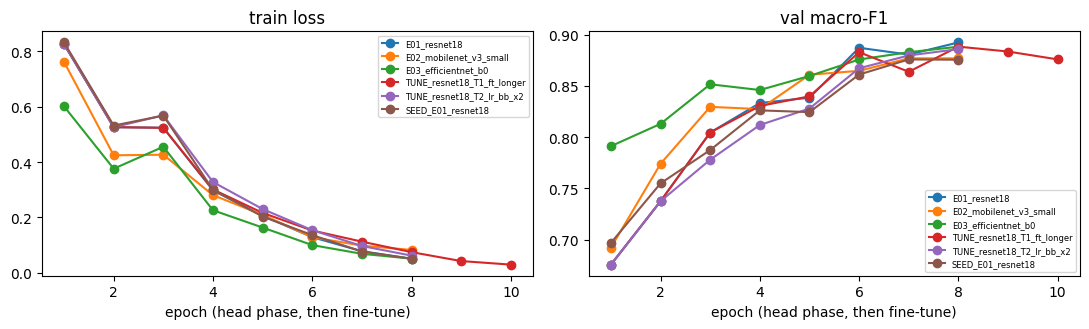

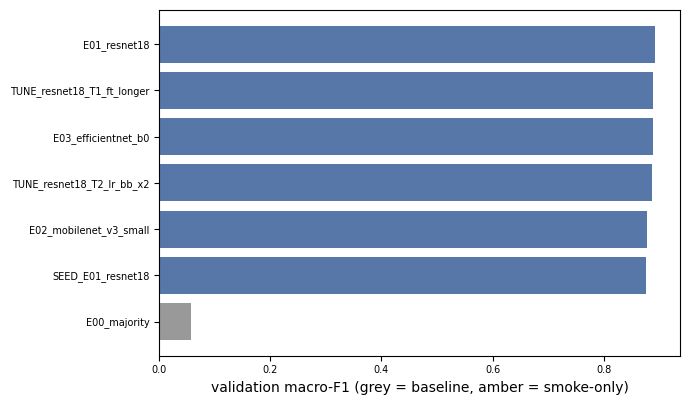

In [28]:
if RESULTS:
    exp_df = pd.DataFrame(RESULTS)
    for c in ["pretrained", "strategy", "hyperparams", "val_macro_f1", "val_weighted_f1", "val_accuracy",
              "val_top2_accuracy", "val_min_class_f1", "best_epoch", "train_seconds", "params", "artifact_mb",
              "latency_cpu_ms", "latency_gpu_ms", "peak_gpu_mb", "checkpoint", "batch_size_effective"]:
        if c not in exp_df:
            exp_df[c] = np.nan
    exp_df["smoke_only"] = exp_df["smoke_only"].fillna(False).astype(bool)
    exp_df["category"] = np.select(
        [exp_df["architecture"] == "majority_class", exp_df["status"] == "failed", exp_df["status"] == "skipped",
         exp_df["smoke_only"]], ["baseline", "failed", "skipped", "smoke_only"], default="trained")
    cols = ["experiment_id", "category", "architecture", "pretrained", "strategy", "epochs_completed", "best_epoch",
            "seed", "val_macro_f1", "val_accuracy", "val_weighted_f1", "val_top2_accuracy", "val_min_class_f1",
            "train_seconds", "params", "artifact_mb", "latency_cpu_ms", "latency_gpu_ms", "peak_gpu_mb",
            "batch_size_effective", "hyperparams", "checkpoint", "note"]
    exp_df = exp_df[cols + [c for c in exp_df.columns if c not in cols]]
    with pd.option_context("display.max_colwidth", 34, "display.max_columns", 40):
        display(exp_df[cols[:19] + ["note"]].sort_values("val_macro_f1", ascending=False))
    print(exp_df["category"].value_counts().to_string())
    print(f"\nlatency: model forward only, batch 1, 5 warm-up + 20 timed runs; CPU = {platform.processor() or platform.machine()}"
          + (f", GPU = {GPU_NAME} (synchronised)" if DEVICE == "cuda" else ", no GPU")
          + ". Preprocessing is excluded here and measured at export. Per-class metrics: experiments/per_class_<id>.csv")
    exp_df.to_csv(WORK / "experiments" / "experiment_results.csv", index=False)

    if HISTORY:
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
        for eid, hh in HISTORY.items():
            axes[0].plot(range(1, len(hh) + 1), hh["train_loss"], marker="o", label=eid)
            axes[1].plot(range(1, len(hh) + 1), hh["val_macro_f1"], marker="o", label=eid)
        axes[0].set_title("train loss"); axes[1].set_title("val macro-F1")
        for a in axes:
            a.set_xlabel("epoch (head phase, then fine-tune)"); a.legend(fontsize=6)
        plt.tight_layout(); plt.savefig(WORK / "figures" / "learning_curves.png", dpi=90); plt.show()

        d = exp_df[exp_df["val_macro_f1"].notna()].sort_values("val_macro_f1")
        fig, ax = plt.subplots(figsize=(7, 0.45 * len(d) + 1))
        ax.barh(d["experiment_id"], d["val_macro_f1"],
                color=[{"baseline": "#999999", "smoke_only": "#d9a441"}.get(c, "#5677a8") for c in d["category"]])
        ax.set_xlabel("validation macro-F1 (grey = baseline, amber = smoke-only)"); ax.tick_params(labelsize=7)
        plt.tight_layout(); plt.savefig(WORK / "figures" / "experiment_comparison.png", dpi=90); plt.show()
else:
    print("No experiments were run — see the gate table above.")

In [29]:
if len(exp_df) and neural_rows():
    TOL = CFG["selection_tolerance"]             # fixed before looking at results
    cand_all = exp_df[exp_df["category"].isin(["trained", "smoke_only"])
                      & ~exp_df["experiment_id"].str.startswith("SEED_")]
    cand = cand_all[cand_all["category"] == "trained"]
    if cand.empty:
        cand = cand_all
        print("NOTE: only smoke-only (random-init) runs exist — this selection demonstrates plumbing only.")
    top = cand.loc[cand["val_macro_f1"].idxmax()]
    within = cand[cand["val_macro_f1"] >= top["val_macro_f1"] - TOL].sort_values(["latency_cpu_ms", "params"])
    chosen, reason = within.iloc[0], f"highest validation macro-F1, then lowest CPU latency within {TOL} macro-F1"
    if CFG["force_selected_experiment"]:
        forced = cand_all[cand_all["experiment_id"] == CFG["force_selected_experiment"]]
        if forced.empty:
            raise ValueError(f"force_selected_experiment={CFG['force_selected_experiment']} is not a measured run")
        chosen, reason = forced.iloc[0], "manual override via CFG['force_selected_experiment']"
    SELECTED = {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in chosen.to_dict().items()}
    display(within[["experiment_id", "val_macro_f1", "val_min_class_f1", "latency_cpu_ms", "params", "artifact_mb"]])
    print(f"top macro-F1 : {top['experiment_id']} ({top['val_macro_f1']:.4f})")
    print(f"SELECTED     : {SELECTED['experiment_id']} ({SELECTED['val_macro_f1']:.4f}, min class F1 "
          f"{SELECTED['val_min_class_f1']:.4f}, {SELECTED['latency_cpu_ms']} ms CPU) — {reason}")
    print("Selected on catalog validation only. Not a production winner; phone-photo behaviour is unknown.")

    # ---- uncertainty policy: measured on validation predictions of the selected model ----
    pr = VALPREDS[SELECTED["experiment_id"]]
    conf, correct = pr["scores"].max(1), pr["pred"] == pr["y"]
    rc = pd.DataFrame([{"threshold": t, "coverage": float((conf >= t).mean()),
                        "n_auto_accepted": int((conf >= t).sum()),
                        "error_among_accepted": float(1 - correct[conf >= t].mean()) if (conf >= t).any() else np.nan}
                       for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]])
    display(rc.round(4))
    rc.to_csv(WORK / "experiments" / "risk_coverage_validation.csv", index=False)
    okt = rc[(rc["error_among_accepted"] <= CFG["review_target_error"]) & (rc["n_auto_accepted"] >= 20)]
    if SELECTED["smoke_only"] or okt.empty:
        REVIEW_POLICY = {"review_threshold": None, "always_review": True,
                         "status": "provisional — no threshold met the target on validation (or smoke-only run); "
                                   "the top suggestion is shown unfiltered and every prediction needs user review"}
    else:
        t = okt.iloc[0]
        REVIEW_POLICY = {"review_threshold": float(t["threshold"]), "always_review": True,
                         "target_error": CFG["review_target_error"],
                         "validation_coverage": float(t["coverage"]),
                         "validation_error_among_accepted": float(t["error_among_accepted"]),
                         "status": "threshold measured on CATALOG validation only; scores are uncalibrated "
                                   "softmax; not validated on phone photos, so always_review stays True"}
    REVIEW_POLICY["score_type"] = "uncalibrated_softmax"
    print("review policy:", json.dumps(REVIEW_POLICY, indent=1))

    SELECTION_REPORT = {"selected": SELECTED["experiment_id"], "rule": reason, "tolerance": TOL,
                        "top_by_macro_f1": top["experiment_id"], "smoke_only": bool(SELECTED["smoke_only"]),
                        "candidates": cand_all[["experiment_id", "category", "val_macro_f1", "val_min_class_f1",
                                                "latency_cpu_ms", "params"]].to_dict("records"),
                        "seed_stability": SEED_STABILITY, "review_policy": REVIEW_POLICY,
                        "selected_on": "catalog validation split only", "split_fingerprint": SPLIT_FP,
                        "taxonomy_fingerprint": TAX_FP}
    (WORK / "reports" / "selection_report.json").write_text(json.dumps(SELECTION_REPORT, indent=2, default=str), encoding="utf-8")
    set_status("selection", "measured" if not SELECTED["smoke_only"] else "provisional", SELECTED["experiment_id"])
else:
    set_status("selection", "skipped", "no measured candidate")

,experiment_id,val_macro_f1,val_min_class_f1,latency_cpu_ms,params,artifact_mb
3,E03_efficientnet_b0,0.888151,0.770833,28.21,4021639.0,16.39
5,TUNE_resnet18_T2_lr_bb_x2,0.885777,0.751468,29.57,11182155.0,44.81
1,E01_resnet18,0.892293,0.781609,30.64,11182155.0,44.81
4,TUNE_resnet18_T1_ft_longer,0.888202,0.767442,30.92,11182155.0,44.81


top macro-F1 : E01_resnet18 (0.8923)
SELECTED     : E03_efficientnet_b0 (0.8882, min class F1 0.7708, 28.21 ms CPU) — highest validation macro-F1, then lowest CPU latency within 0.01 macro-F1
Selected on catalog validation only. Not a production winner; phone-photo behaviour is unknown.


,threshold,coverage,n_auto_accepted,error_among_accepted
0,0.00,1.0000,2310,0.0684
1,0.50,0.9961,2301,0.0665
2,0.60,0.9775,2258,0.0593
3,0.70,0.9541,2204,0.0499
4,0.80,0.9255,2138,0.0412
5,0.90,0.8952,2068,0.0353
6,0.95,0.8563,1978,0.0243
7,0.99,0.7749,1790,0.0123


review policy: {
 "review_threshold": 0.7,
 "always_review": true,
 "target_error": 0.05,
 "validation_coverage": 0.9541125541125541,
 "validation_error_among_accepted": 0.04990925589836659,
 "status": "threshold measured on CATALOG validation only; scores are uncalibrated softmax; not validated on phone photos, so always_review stays True",
 "score_type": "uncalibrated_softmax"
}
[MEASURED] selection — E03_efficientnet_b0


validation error analysis — E03_efficientnet_b0


,precision,recall,f1-score,support
dress,0.863,0.940,0.900,67.000
jacket,0.865,0.842,0.853,38.000
jeans,0.967,0.956,0.961,91.000
shirt,0.971,0.975,0.973,476.000
shorts,0.920,0.976,0.947,83.000
skirt,1.000,0.714,0.833,21.000
sweater,0.842,0.762,0.800,42.000
sweatshirt,0.685,0.881,0.771,42.000
t-shirt,0.967,0.945,0.956,1061.000
top,0.788,0.817,0.802,263.000


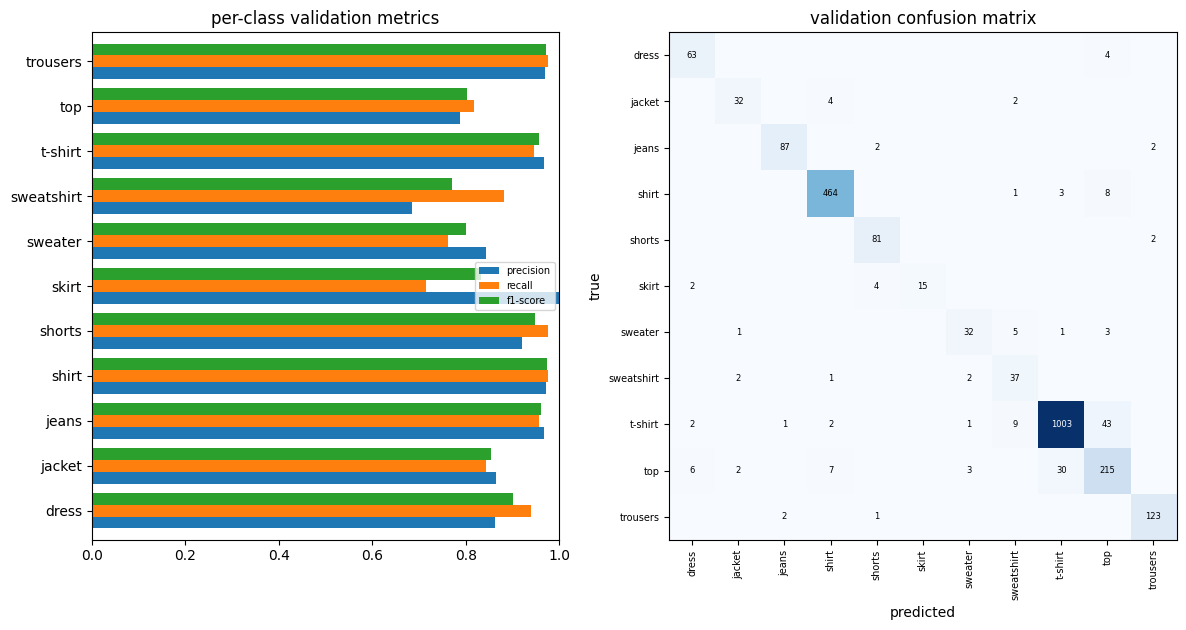

errors: 158/2310 | high-score errors (>0.8): 88


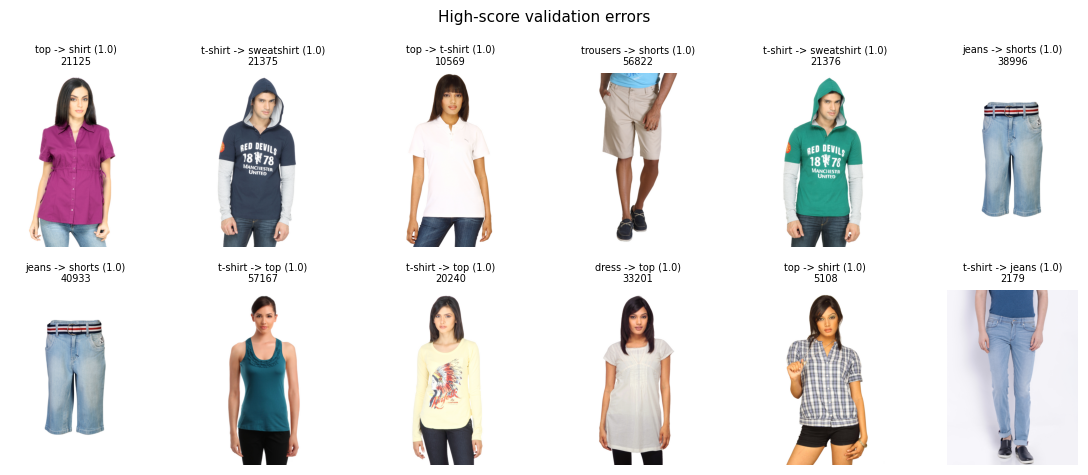

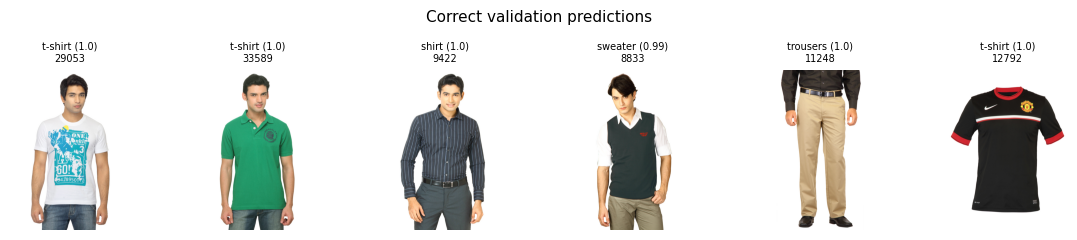

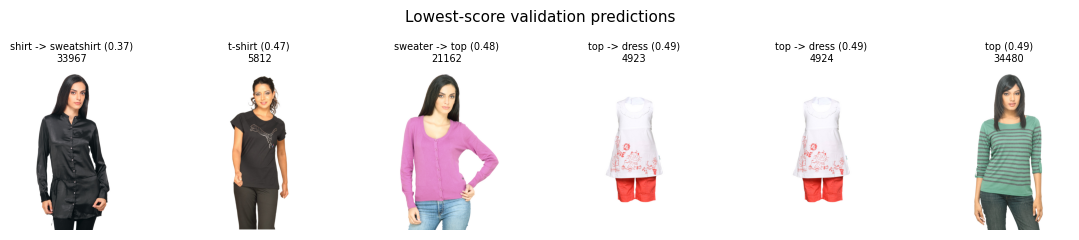


Diagnosis
  - 'sweatshirt': F1 0.77, support 42: ample support -> look at label/taxonomy overlap in the error grid
  - t-shirt -> top: 43 errors (30 in the other direction): symmetric confusion, the two labels may overlap in the catalog (taxonomy/label issue)
  - top -> t-shirt: 30 errors (43 in the other direction): symmetric confusion, the two labels may overlap in the catalog (taxonomy/label issue)
  - t-shirt -> sweatshirt: 9 errors (0 in the other direction): one-directional, check whether the minority class is being absorbed
  - 88 high-score errors: inspect the grid for mislabelled catalog items before blaming the model
  - cropping/resolution: the whole garment is kept (pad + resize); check small details at 224px in the grids
  - background bias and domain shift: every image is a catalog photo; NOT measurable without DressMe photos
  Change the architecture only if these point to model capacity rather than data or taxonomy.


In [30]:
if SELECTED is not None:
    sid = SELECTED["experiment_id"]
    pr = VALPREDS[sid]
    rep = pd.read_csv(WORK / "experiments" / f"per_class_{sid}.csv", index_col=0)
    print(f"validation error analysis — {sid}" + ("  [SMOKE-ONLY: not a real result]" if SELECTED["smoke_only"] else ""))
    display(rep.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 1.6 + 0.42 * len(CLASSES)), gridspec_kw={"width_ratios": [1, 1.1]})
    rep.loc[CLASSES, ["precision", "recall", "f1-score"]].plot(kind="barh", ax=axes[0], width=0.8)
    axes[0].set_xlim(0, 1); axes[0].set_title("per-class validation metrics"); axes[0].legend(fontsize=7)
    cm = confusion_matrix(pr["y"], pr["pred"], labels=list(range(len(CLASSES))))
    axes[1].imshow(cm, cmap="Blues")
    axes[1].set_xticks(range(len(CLASSES)), CLASSES, rotation=90, fontsize=7)
    axes[1].set_yticks(range(len(CLASSES)), CLASSES, fontsize=7)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm[i, j]:
                axes[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                             color="white" if cm[i, j] > cm.max() * .5 else "black")
    axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true"); axes[1].set_title("validation confusion matrix")
    plt.tight_layout(); plt.savefig(WORK / "figures" / "validation_per_class_and_confusion.png", dpi=95); plt.show()

    err = pd.DataFrame({"id": pr["ids"], "true": [CLASSES[i] for i in pr["y"]],
                        "pred": [CLASSES[i] for i in pr["pred"]], "score": pr["scores"].max(1)})
    err["correct"] = err["true"] == err["pred"]
    err = err.merge(train_pool[["id", "image_path", "image_relpath", "articleType"]], on="id", how="left")
    err["shown"] = np.where(err["correct"], err["pred"], err["true"] + " -> " + err["pred"]) + " (" + err["score"].round(2).astype(str) + ")"
    err.drop(columns=["image_path", "shown"]).to_csv(WORK / "experiments" / f"val_predictions_{sid}.csv", index=False)
    wrong = err[~err["correct"]].sort_values("score", ascending=False)
    wrong.drop(columns=["image_path", "shown"]).to_csv(WORK / "experiments" / f"val_errors_{sid}.csv", index=False)
    print(f"errors: {len(wrong)}/{len(err)} | high-score errors (>0.8): {int((wrong['score'] > 0.8).sum())}")
    show_grid(wrong, "High-score validation errors", label_col="shown", n=12)
    show_grid(err[err["correct"]].sample(min(6, int(err["correct"].sum())), random_state=SEED),
              "Correct validation predictions", label_col="shown")
    show_grid(err.nsmallest(6, "score"), "Lowest-score validation predictions", label_col="shown")

    # ---- diagnosis from the measurements above (hypotheses to check in the grids, not conclusions) ----
    sup, f1c = rep.loc[CLASSES, "support"], rep.loc[CLASSES, "f1-score"]
    weak = f1c[f1c < f1c.median() - 0.10].sort_values()
    print("\nDiagnosis")
    for c, v in weak.items():
        cause = ("few validation rows -> noisy estimate, likely under-represented in training (rare class)"
                 if sup[c] < 0.5 * sup.median() else "ample support -> look at label/taxonomy overlap in the error grid")
        print(f"  - '{c}': F1 {v:.2f}, support {int(sup[c])}: {cause}")
    for (t, p), n in wrong.groupby(["true", "pred"]).size().sort_values(ascending=False).head(3).items():
        back = int(((err["true"] == p) & (err["pred"] == t)).sum())
        print(f"  - {t} -> {p}: {n} errors ({back} in the other direction): "
              + ("symmetric confusion, the two labels may overlap in the catalog (taxonomy/label issue)"
                 if back >= 0.5 * n else "one-directional, check whether the minority class is being absorbed"))
    hs = int((wrong["score"] > 0.8).sum())
    print(f"  - {hs} high-score errors: inspect the grid for mislabelled catalog items before blaming the model")
    print("  - cropping/resolution: the whole garment is kept (pad + resize); check small details at "
          f"{CFG['image_size']}px in the grids")
    print("  - background bias and domain shift: every image is a catalog photo; NOT measurable without DressMe photos")
    print("  Change the architecture only if these point to model capacity rather than data or taxonomy.")

In [31]:
# Leakage sensitivity: does validation performance depend on images that have a pixel-similar partner in training?
if SELECTED is not None:
    pr = VALPREDS[SELECTED["experiment_id"]]
    val = pd.DataFrame({"id": pr["ids"], "y": pr["y"], "pred": pr["pred"]})
    sa, sb = near_df["id_a"].map(sp), near_df["id_b"].map(sp)
    rows_ = [{"validation subset": "all", "n": len(val), "accuracy": float((val["y"] == val["pred"]).mean()),
              "macro_f1": float(f1_score(val["y"], val["pred"], labels=list(range(len(CLASSES))), average="macro", zero_division=0))}]
    for name, m in [(f"near-identical (MAD <= {MAD_STRICT})", near_df["thumb_mad"] <= MAD_STRICT),
                    (f"similar (MAD <= {MAD_REPORT})", near_df["thumb_mad"] <= MAD_REPORT)]:
        linked = set(near_df.loc[m & (sa == "val") & (sb == "train"), "id_a"]) | set(near_df.loc[m & (sb == "val") & (sa == "train"), "id_b"])
        for tag, d in [("linked to a training image", val[val["id"].isin(linked)]), ("NOT linked", val[~val["id"].isin(linked)])]:
            rows_.append({"validation subset": f"{name}: {tag}", "n": len(d),
                          "accuracy": float((d["y"] == d["pred"]).mean()) if len(d) else None,
                          "macro_f1": float(f1_score(d["y"], d["pred"], labels=list(range(len(CLASSES))), average="macro", zero_division=0)) if len(d) else None})
    leak_tbl = pd.DataFrame(rows_)
    display(leak_tbl.round(4))
    leak_tbl.to_csv(WORK / "experiments" / "leakage_sensitivity_validation.csv", index=False)
    LEAK_DIAG = {"status": "measured", "rows": leak_tbl.to_dict("records"), "search_coverage": COVERAGE}
    print("Read the 'NOT linked' rows against 'all'. Macro-F1 on a small linked subset is not meaningful (few classes present). "
          f"The search is {COVERAGE}, so this bounds the effect of the links that were found, not of all product overlap.")

,validation subset,n,accuracy,macro_f1
0,all,2310,0.9316,0.8882
1,near-identical (MAD <= 3.0): linked to a train...,37,0.9730,0.4498
2,near-identical (MAD <= 3.0): NOT linked,2273,0.9309,0.8879
3,similar (MAD <= 8.0): linked to a training image,638,0.9561,0.8644
4,similar (MAD <= 8.0): NOT linked,1672,0.9222,0.8788


Read the 'NOT linked' rows against 'all'. Macro-F1 on a small linked subset is not meaningful (few classes present). The search is partial, so this bounds the effect of the links that were found, not of all product overlap.


In [32]:
def load_photo_dir(root):
    """<root>/<class>/<image> or <root>/<class>/<garment>/<image...>. Class folder = taxonomy label."""
    rows, unknown = [], []
    for cdir in sorted(p for p in Path(root).iterdir() if p.is_dir()):
        label = cdir.name.strip().lower()
        if label not in CLASS_TO_IDX:
            unknown.append(cdir.name); continue
        for p in sorted(cdir.rglob("*")):
            if p.is_file() and p.suffix.lower() in IMAGE_EXT:
                rows.append({"image_path": str(p), "label": label, "label_idx": CLASS_TO_IDX[label],
                             "garment": f"{label}/{p.parent.name if p.parent != cdir else p.stem}"})
    return pd.DataFrame(rows, columns=["image_path", "label", "label_idx", "garment"]), unknown

def eval_photos(model, df):
    scores, keep, failed = [], [], []
    for i, p in enumerate(df["image_path"]):
        try:
            x = EVAL_TF(load_rgb(p))
        except (OSError, ValueError) as e:              # unreadable photo: counted, not hidden
            failed.append({"image_path": p, "error": type(e).__name__}); continue
        with torch.no_grad():
            scores.append(model(x[None].to(DEVICE)).float().softmax(1).cpu().numpy()[0]); keep.append(i)
    d = df.iloc[keep].copy()
    if d.empty:
        return {"n_images": 0, "n_unreadable": len(failed)}, d
    s = np.stack(scores)
    d["pred"], d["score"] = [CLASSES[i] for i in s.argmax(1)], s.max(1)
    d["correct"] = d["pred"] == d["label"]
    res = {"n_images": len(d), "n_garments": int(d["garment"].nunique()), "n_unreadable": len(failed),
           **metrics_from(d["label_idx"].to_numpy(), s, labels=sorted(d["label_idx"].unique())),   # macro over classes present
           "garment_level_accuracy": float(d.groupby("garment")["correct"].mean().mean()),
           "classes_present": sorted(d["label"].unique())}
    return res, d

if SELECTED is not None and CFG["dressme_dev_dir"]:
    ddf, unknown = load_photo_dir(CFG["dressme_dev_dir"])
    print("macro-F1 below is averaged over the classes present in the photo set only.")
    print(f"DressMe development photos: {len(ddf)} images, {ddf['garment'].nunique()} garments"
          + (f" | folders not in the taxonomy (ignored, unsupported): {unknown}" if unknown else ""))
    if ddf.empty:
        DRESSME_DEV = {"status": "absent", "note": "folder contains no image under a taxonomy class — NOT a passed evaluation"}
    else:
        rows_ = []
        for r in exp_df[exp_df["category"].isin(["trained", "smoke_only"])].to_dict("records"):
            res, d = eval_photos(load_trained(r), ddf)
            rows_.append({"experiment_id": r["experiment_id"], "catalog_val_macro_f1": r["val_macro_f1"], **res})
            if r["experiment_id"] == SELECTED["experiment_id"]:
                d.to_csv(WORK / "experiments" / "dressme_dev_predictions.csv", index=False)
                show_grid(d[~d["correct"]].assign(id="", shown=lambda x: x["label"] + " -> " + x["pred"]),
                          "DressMe dev photo errors (selected model)", label_col="shown", n=12)
        dev_tbl = pd.DataFrame(rows_)
        display(dev_tbl.drop(columns=["classes_present"], errors="ignore").round(4))
        dev_tbl.to_csv(WORK / "experiments" / "dressme_dev_results.csv", index=False)
        DRESSME_DEV = {"status": "measured", "unknown_folders": unknown,
                       **dev_tbl[dev_tbl["experiment_id"] == SELECTED["experiment_id"]].iloc[0].to_dict()}
        print("Development photos are for diagnosis. To change the selection because of them, set "
              "CFG['force_selected_experiment'] (recorded) — and keep the final photo set untouched.")
    set_status("dressme_dev_photos", "measured" if DRESSME_DEV["status"] == "measured" else "skipped", DRESSME_DEV.get("note", ""))
else:
    set_status("dressme_dev_photos", "skipped", "no development photos supplied — NOT a passed evaluation")

[SKIPPED ] dressme_dev_photos — no development photos supplied — NOT a passed evaluation


## 15. Automatic description

A deterministic template over structured fields — not a generative language model.
1. **Attribute heads** predict sleeve length, pattern and colour from the selected classifier's features,
   trained on weak catalog labels. A garment type is eligible only where the catalog labels the attribute.
2. **Policy** (from the config): sleeve length is stated for eligible garments, pattern only above its
   threshold, colour is never stated — it is offered as a suggestion for the user to confirm.
3. Fabric, brand, size, fit and season are never claimed.

In [33]:
# Attribute heads: sleeve length, pattern, colour. Weak labels from catalog metadata; small linear heads on the
# SELECTED classifier's pooled features + a colour histogram. Train rows only; measured on validation rows.
# The policy thresholds come from CFG (fixed before this run); nothing here is tuned to improve the numbers.
def colour_hist(canvas):                       # canvas: S x S x 3 uint8 (padded + resized). Same code ships in attributes.py
    hh, ww = canvas.shape[:2]
    c = canvas[int(hh * .20):int(hh * .80), int(ww * .25):int(ww * .75)].reshape(-1, 3)
    c = c[c.min(1) < 235]                      # drop the near-white background
    if len(c) == 0:
        return np.zeros(512, dtype=np.float32)
    q = (c >> 5).astype(np.int32)
    return np.sqrt(np.bincount(q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2], minlength=512) / len(c)).astype(np.float32)

HEADS = {}
if CFG["run_attributes"] and SELECTED is not None:
    POLICY = CFG["attribute_policy"]
    # ---- 1. weak labels. Missing stays missing: it is never read as "solid" or "sleeveless" ----
    rows_ = []
    for pid in train_pool["id"]:
        try:
            a = json.loads((JSON_DIR / f"{pid}.json").read_text(encoding="utf-8")).get("data", {}).get("articleAttributes") or {}
        except (OSError, ValueError):
            a = {}
        rows_.append({"id": pid, "raw_pattern": a.get("Pattern"), "raw_sleeve_length": a.get("Sleeve Length")})
    ATTR_A = train_pool[["id", "label", "split", "baseColour", "image_path"]].merge(pd.DataFrame(rows_), on="id")
    ATTR_A = ATTR_A[ATTR_A["split"].isin(["train", "val"])].reset_index(drop=True)      # the test split is not touched
    ATTR_A["raw_color"] = ATTR_A["baseColour"].str.strip().replace("", np.nan)
    ATTR_A["color"] = ATTR_A["raw_color"].map(CFG["color_map"])
    ATTR_A["pattern"] = ATTR_A["raw_pattern"].map(CFG["pattern_map"])
    ATTR_A["sleeve_length"] = ATTR_A["raw_sleeve_length"].map(CFG["sleeve_map"])
    is_tr = (ATTR_A["split"] == "train").to_numpy()
    label_audit = []
    for attr in POLICY:
        raw = ATTR_A[f"raw_{attr}"]
        unsupported = raw[raw.notna() & ATTR_A[attr].isna()].value_counts()
        label_audit.append({"attribute": attr, "rows": len(ATTR_A), "label_missing": int(raw.isna().sum()),
                            "label_usable": int(ATTR_A[attr].notna().sum()), "label_unsupported_value": int(unsupported.sum()),
                            "unsupported_values (excluded)": ", ".join(f"{k} ({v})" for k, v in unsupported.head(8).items())})
    with pd.option_context("display.max_colwidth", 110):
        display(pd.DataFrame(label_audit))

    # ---- 2. features: input of the classifier's last Linear layer + colour histogram, standardised on TRAIN rows ----
    m = load_trained(SELECTED)                                   # eval mode; the classifier itself is not modified
    last_linear = [x for x in m.modules() if isinstance(x, nn.Linear)][-1]
    buf = {}
    hook = last_linear.register_forward_hook(lambda mod, inp, out: buf.__setitem__("f", inp[0].detach().float().cpu()))
    pix = np.load(PIX_PATH, mmap_mode="r") if PIX_PATH is not None else None
    emb, hist, t0 = [], [], time.time()
    with torch.no_grad():
        for s in range(0, len(ATTR_A), 128):
            part = ATTR_A.iloc[s:s + 128]
            canv = [np.array(pix[ROW_OF[i]]) if pix is not None else np.asarray(to_canvas(load_rgb(p)))
                    for i, p in zip(part["id"], part["image_path"])]
            m(torch.stack([TO_TENSOR(Image.fromarray(c)) for c in canv]).to(DEVICE))
            emb.append(buf["f"].numpy()); hist.extend(colour_hist(c) for c in canv)
    hook.remove(); del m
    X = np.concatenate([np.concatenate(emb), np.stack(hist)], axis=1).astype(np.float32)   # order: [embedding, histogram]
    ATTR_MU, ATTR_SD = X[is_tr].mean(0), X[is_tr].std(0) + 1e-6
    ATTR_X = (X - ATTR_MU) / ATTR_SD
    print(f"features {X.shape}: {int(is_tr.sum())} train + {int((~is_tr).sum())} validation rows ({time.time() - t0:.0f}s)")

    def fit_head(Xtr, ytr, n_cls, steps=300):
        torch.manual_seed(SEED)
        lin = nn.Linear(Xtr.shape[1], n_cls).to(DEVICE)
        xt, yt = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
        cnt = np.bincount(ytr, minlength=n_cls).clip(min=1)
        wts = torch.tensor((cnt.sum() / (n_cls * cnt)) ** 0.5, dtype=torch.float32, device=DEVICE)
        opt = torch.optim.AdamW(lin.parameters(), lr=1e-2, weight_decay=1e-2)
        for _ in range(steps):
            opt.zero_grad(); nn.functional.cross_entropy(lin(xt), yt, weight=wts).backward(); opt.step()
        return lin

    def head_probs(attr, Xrows):
        hd = HEADS[attr]
        z = Xrows @ hd["weight"].numpy().T + hd["bias"].numpy()
        p = np.exp(z - z.max(1, keepdims=True))
        return p / p.sum(1, keepdims=True)

    # ---- 3. train, then report with explicit denominators ----
    vp = VALPREDS[SELECTED["experiment_id"]]
    pred_cat = dict(zip(vp["ids"], [CLASSES[i] for i in vp["pred"]]))
    pred_score = dict(zip(vp["ids"], vp["scores"].max(1)))
    thr_cat = REVIEW_POLICY["review_threshold"]
    val_rows = np.flatnonzero(~is_tr)
    n_val, attr_rows, ATTR_DETAIL = len(val_rows), [], {}
    for attr, thr in POLICY.items():
        cov = ATTR_A[is_tr].groupby("label")[attr].apply(lambda s: s.notna().mean())
        eligible = sorted(cov[cov >= CFG["attribute_min_class_coverage"]].index)       # garment types the catalog labels
        use = ATTR_A[attr].notna() & ATTR_A["label"].isin(eligible)
        values = sorted(ATTR_A.loc[use & is_tr, attr].unique())
        if len(values) < 2:
            print(f"{attr}: fewer than two labelled values — no head trained"); continue
        v2i = {v: i for i, v in enumerate(values)}
        tr, va = (use & is_tr).to_numpy(), (use & ~is_tr & ATTR_A[attr].isin(values)).to_numpy()
        lin = fit_head(ATTR_X[tr], ATTR_A.loc[tr, attr].map(v2i).to_numpy(), len(values))
        HEADS[attr] = {"values": values, "classes": eligible, "threshold": thr,
                       "weight": lin.weight.detach().float().cpu(), "bias": lin.bias.detach().float().cpu()}
        # (a) eligible, labelled validation rows — the only rows where agreement with the catalog can be measured
        P, y = head_probs(attr, ATTR_X[va]), ATTR_A.loc[va, attr].map(v2i).to_numpy()
        pred, conf = P.argmax(1), P.max(1)
        per = pd.DataFrame(classification_report(y, pred, labels=list(range(len(values))), target_names=values,
                                                 output_dict=True, zero_division=0)).T
        rc = pd.DataFrame([{"threshold": t, "coverage_of_eligible_labelled": float((conf >= t).mean()),
                            "error_among_answered": float((pred != y)[conf >= t].mean()) if (conf >= t).any() else np.nan}
                           for t in [0.0, 0.5, 0.7, 0.9, 0.95, 0.97, 0.99]])
        ans = conf >= thr if thr is not None else np.zeros(len(conf), dtype=bool)
        maj = np.bincount(ATTR_A.loc[tr, attr].map(v2i).to_numpy(), minlength=len(values)).argmax()
        # (b) end to end on ALL validation images, using the PREDICTED category like the product does
        Pall = head_probs(attr, ATTR_X[val_rows])
        cats = np.array([pred_cat[i] for i in ATTR_A.loc[val_rows, "id"]])
        withheld_cat = np.array([thr_cat is not None and pred_score[i] < thr_cat for i in ATTR_A.loc[val_rows, "id"]])
        inapplicable = ~np.isin(cats, eligible) & ~withheld_cat
        stated = (~withheld_cat) & (~inapplicable) & (Pall.max(1) >= thr if thr is not None else False)
        below = (~withheld_cat) & (~inapplicable) & ~stated
        attr_rows.append({
            "attribute": attr, "policy": "suggestion only" if thr is None else f"stated if score >= {thr}",
            "eligible garment types": ", ".join(eligible),
            "eligible labelled val rows (denominator)": int(va.sum()),
            "accuracy vs catalog": float((pred == y).mean()), "macro_f1 vs catalog": float(per.loc["macro avg", "f1-score"]),
            "majority baseline accuracy": float((y == maj).mean()),
            "answered at policy (share of denominator)": float(ans.mean()),
            "error among answered": float((pred != y)[ans].mean()) if ans.any() else None,
            "all val images": n_val, "stated": int(stated.sum()), "below threshold / suggestion only": int(below.sum()),
            "inapplicable garment type": int(inapplicable.sum()), "category withheld": int(withheld_cat.sum()),
            "stated share of all val images": float(stated.mean())})
        ATTR_DETAIL[attr] = {"per_value": per.round(4).to_dict("index"), "risk_coverage": rc.round(4).to_dict("records")}
        print(f"\n=== {attr} === values {values}")
        display(per.loc[values + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3))
        display(rc.round(3))
    attr_tbl = pd.DataFrame(attr_rows)
    with pd.option_context("display.max_colwidth", 80, "display.max_columns", 30):
        display(attr_tbl.set_index("attribute").T)
    if "sleeve_length" in ATTR_DETAIL and "sleeveless" in ATTR_DETAIL["sleeve_length"]["per_value"]:
        sl = ATTR_DETAIL["sleeve_length"]["per_value"]["sleeveless"]
        print(f"sleeveless is the weakest sleeve value: precision {sl['precision']:.2f}, recall {sl['recall']:.2f} on {int(sl['support'])} rows. "
              f"The sleeve threshold stays at the configured {POLICY['sleeve_length']} as a provisional reviewed-demo policy: "
              f"every description is shown to the user for correction; it is not validated on phone photos.")
    print("How to read this: accuracy and error are AGREEMENT WITH WEAK CATALOG LABELS on the eligible labelled validation rows only. "
          "They are not human-verified factuality and not phone-photo performance. The policy thresholds were explored on these same "
          "validation rows in earlier runs, so the reported error at the threshold is optimistic. The reserved test split is untouched.")
    ATTR = {"status": "measured", "policy": POLICY, "table": attr_tbl.to_dict("records"), "detail": ATTR_DETAIL,
            "label_audit": label_audit,
            "feature": "input of the classifier's last Linear layer, then 512-bin sqrt RGB histogram of the central region "
                       "(rows 20-80%, cols 25-75%, pixels with min channel < 235, 8 levels per channel); "
                       "standardised with training mean/std",
            "checkpoint_dependency": SELECTED["experiment_id"], "split_fingerprint": SPLIT_FP,
            "labels": "weak supervision: catalog baseColour and articleAttributes (Pattern, Sleeve Length)"}
    set_status("description_attributes", "provisional", "weak-label validation only; thresholds from config")
else:
    set_status("description_attributes", "skipped", "disabled, or no selected model")

,attribute,rows,label_missing,label_usable,label_unsupported_value,unsupported_values (excluded)
0,sleeve_length,13105,3208,9709,188,Three-Quarter Sleeves (188)
1,pattern,13105,2292,10659,154,"Embellished (63), Self Design (47), Washed (30), Colourblocked (9), Dyed (5)"
2,color,13105,0,12993,112,"Multi (50), Teal (45), Rust (12), NA (5)"


features (13105, 1792): 10795 train + 2310 validation rows (40s)

=== sleeve_length === values ['long', 'short', 'sleeveless']


,precision,recall,f1-score,support
long,0.918,0.936,0.927,420.0
short,0.963,0.935,0.949,1108.0
sleeveless,0.674,0.820,0.740,111.0
macro avg,0.852,0.897,0.872,1639.0


,threshold,coverage_of_eligible_labelled,error_among_answered
0,0.00,1.000,0.073
1,0.50,0.999,0.073
2,0.70,0.969,0.060
3,0.90,0.919,0.046
4,0.95,0.893,0.042
5,0.97,0.863,0.036
6,0.99,0.813,0.031



=== pattern === values ['checked', 'printed', 'solid', 'striped']


...


=== color === values ['beige', 'black', 'blue', 'brown', 'green', 'grey', 'navy', 'orange', 'pink', 'purple', 'red', 'white', 'yellow']


,precision,recall,f1-score,support
beige,0.453,0.453,0.453,53.0
black,0.765,0.723,0.744,365.0
blue,0.728,0.737,0.732,399.0
brown,0.328,0.386,0.355,57.0
green,0.782,0.731,0.756,216.0
grey,0.625,0.650,0.637,223.0
navy,0.481,0.487,0.484,158.0
orange,0.593,0.516,0.552,31.0
pink,0.664,0.595,0.628,126.0
purple,0.682,0.652,0.667,115.0


,threshold,coverage_of_eligible_labelled,error_among_answered
0,0.00,1.000,0.309
1,0.50,0.960,0.291
2,0.70,0.846,0.252
3,0.90,0.697,0.198
4,0.95,0.625,0.178
5,0.97,0.569,0.159
6,0.99,0.477,0.133


attribute,sleeve_length,pattern,color
policy,stated if score >= 0.0,stated if score >= 0.97,suggestion only
eligible garment types,"jacket, shirt, sweatshirt, t-shirt, top","dress, jacket, shirt, shorts, skirt, sweatshirt, t-shirt, top, trousers","dress, jacket, jeans, shirt, shorts, skirt, sweater, sweatshirt, t-shirt, to..."
eligible labelled val rows (denominator),1639,1835,2291
accuracy vs catalog,0.927395,0.826703,0.690528
macro_f1 vs catalog,0.871814,0.810758,0.642655
majority baseline accuracy,0.676022,0.426703,0.17416
answered at policy (share of denominator),1.0,0.725341,0.0
error among answered,0.072605,0.093163,NaN
all val images,2310,2310,2310
stated,1787,1515,0


sleeveless is the weakest sleeve value: precision 0.67, recall 0.82 on 111 rows. The sleeve threshold stays at the configured 0.0 as a provisional reviewed-demo policy: every description is shown to the user for correction; it is not validated on phone photos.
How to read this: accuracy and error are AGREEMENT WITH WEAK CATALOG LABELS on the eligible labelled validation rows only. They are not human-verified factuality and not phone-photo performance. The policy thresholds were explored on these same validation rows in earlier runs, so the reported error at the threshold is optimistic. The reserved test split is untouched.
[PROVISIONAL] description_attributes — weak-label validation only; thresholds from config


In [34]:
COLOR_VALUES = sorted(set(CFG["color_map"].values()))
DESC_SCHEMA = {
    "version": CFG["description_version"],
    "generator": "deterministic template over structured fields — not a generative language model",
    "fields": {
        "category": {"source": "classifier or user", "allowed": CLASSES + ["unknown"]},
        "color": {"source": "user confirmation only (the model offers suggestions, never states it)",
                  "allowed": COLOR_VALUES + ["unknown"]},
        "pattern": {"source": "attribute head above its threshold, or user",
                    "allowed": ["solid", "striped", "checked", "printed", "floral", "unknown", "not_visible"]},
        "sleeve_length": {"source": "attribute head for eligible garment types, or user",
                          "allowed": ["sleeveless", "short", "long", "unknown", "not_visible"]},
    },
    "plural_categories": ["jeans", "trousers", "shorts"],
    "forbidden_claims": ["material", "fabric_composition", "brand", "size", "fit", "season_suitability"],
    "unknown_policy": "omitted from the text; kept as 'unknown' in the structured output",
}

DESCRIPTION_SRC = '''"""Deterministic garment description: a template over validated structured fields.
No generative language model is involved, and nothing is read from the image here."""
import json
import re
from pathlib import Path

HERE = Path(__file__).resolve().parent
SCHEMA = json.loads((HERE / "description_schema.json").read_text(encoding="utf-8"))
ALLOWED = {k: v["allowed"] for k, v in SCHEMA["fields"].items()}
PLURAL = set(SCHEMA["plural_categories"])


def validate_fields(fields):
    """-> (clean, problems). Keys outside the schema are dropped; disallowed values become "unknown"."""
    clean, problems = {}, []
    for key, allowed in ALLOWED.items():
        v = fields.get(key, "unknown")
        v = v.strip().lower() if isinstance(v, str) else "unknown"
        if v not in allowed:
            problems.append(key + ": value not allowed")
            v = "unknown"
        clean[key] = v
    extra = sorted(set(fields) - set(ALLOWED))
    if extra:
        problems.append("dropped keys: " + ", ".join(map(str, extra)))
    return clean, problems


def parse_model_json(text):
    """Parse a model reply that should contain one flat JSON object -> (clean or None, problems)."""
    m = re.search(r"\\{[^{}]*\\}", text or "", re.S)
    if not m:
        return None, ["no JSON object found"]
    try:
        obj = json.loads(m.group(0))
    except ValueError:
        return None, ["invalid JSON"]
    if not isinstance(obj, dict):
        return None, ["JSON is not an object"]
    return validate_fields(obj)


def render(fields):
    f, _ = validate_fields(fields)
    words = []
    if f["color"] != "unknown":
        words.append(f["color"])
    if f["pattern"] not in ("unknown", "not_visible", "solid"):
        words.append(f["pattern"])
    if f["sleeve_length"] in ("short", "long"):
        words.append(f["sleeve_length"] + "-sleeved")
    elif f["sleeve_length"] == "sleeveless":
        words.append("sleeveless")
    noun = f["category"] if f["category"] != "unknown" else "garment"
    words.append(noun)
    lead = "A pair of " if noun in PLURAL else ("An " if words[0][0] in "aeiou" else "A ")
    return lead + " ".join(words) + "."


def describe(category, category_source="classifier", confirmed=None, predicted=None):
    """category: predicted label or "unknown".
    predicted: {field: value} from the attribute heads (provenance "attribute_model").
    confirmed: {field: value} corrected by the user; overrides everything (provenance "user_confirmed")."""
    fields = {k: "unknown" for k in ALLOWED}
    prov = {k: "not_estimated" for k in ALLOWED}
    fields["category"], prov["category"] = category, category_source
    for source, values in (("attribute_model", predicted), ("user_confirmed", confirmed)):
        for key, value in (values or {}).items():
            v = str(value).strip().lower()
            if key not in ALLOWED or v not in ALLOWED[key]:
                raise ValueError("field not allowed by the schema: %s=%r" % (key, value))
            fields[key], prov[key] = v, source
    clean, problems = validate_fields(fields)
    return {"text": render(clean), "fields": clean, "provenance": prov,
            "category_only": all(clean[k] == "unknown" for k in ("color", "pattern", "sleeve_length")),
            "problems": problems, "schema_version": SCHEMA["version"], "never_claimed": SCHEMA["forbidden_claims"]}
'''
# One source of truth: the notebook imports the very file that is shipped in the bundle.
DESC_DIR = WORK / "description"
(DESC_DIR / "description_schema.json").write_text(json.dumps(DESC_SCHEMA, indent=2), encoding="utf-8")
(DESC_DIR / "description.py").write_text(DESCRIPTION_SRC, encoding="utf-8")
sys.dont_write_bytecode = True
_spec = importlib.util.spec_from_file_location("bo6_description", DESC_DIR / "description.py")
D = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(D)

# Self-checks of the validator and renderer (software checks, not an evaluation).
c0 = CLASSES[0] if CLASSES else "unknown"
ok, pb = D.parse_model_json('Sure! {"category": "%s", "color": "Navy", "pattern": "striped", "sleeve_length": "short", "material": "cotton"}' % c0)
assert ok == {"category": c0, "color": "navy", "pattern": "striped", "sleeve_length": "short"} and pb
assert "cotton" not in D.render(ok) and D.parse_model_json("no json")[0] is None and D.parse_model_json("{broken")[0] is None
assert D.validate_fields({"category": "spaceship", "color": "chartreuse"})[0] == {k: "unknown" for k in DESC_SCHEMA["fields"]}
assert D.render({"category": "unknown"}) == "A garment."
d = D.describe(c0, predicted={"pattern": "striped"}, confirmed={"color": "blue"})
assert d["provenance"] == {"category": "classifier", "color": "user_confirmed", "pattern": "attribute_model", "sleeve_length": "not_estimated"}
for plural in set(DESC_SCHEMA["plural_categories"]) & set(CLASSES):
    assert D.render({"category": plural}) == f"A pair of {plural}."
print("category only          :", D.render({"category": c0}))
print("with predicted attrs   :", D.describe(c0, predicted={"pattern": "striped", "sleeve_length": "short"})["text"])
print("after user confirmation:", D.describe(c0, predicted={"pattern": "striped"}, confirmed={"color": "blue"})["text"])
print("category withheld      :", D.render({"category": "unknown"}))
print("validator, renderer and provenance self-checks passed")

category only          : A dress.
with predicted attrs   : A striped short-sleeved dress.
after user confirmation: A blue striped dress.
category withheld      : A garment.
validator, renderer and provenance self-checks passed


In [35]:
# The description pipeline as the product runs it, written once here and mirrored by attributes.py in the bundle.
def nb_describe(i_row, pid, confirmed=None):
    """i_row: row of ATTR_X (or None when attribute heads are off). Uses the PREDICTED category, never a label."""
    score, pred = float(pred_score[pid]), pred_cat[pid]
    thr = REVIEW_POLICY["review_threshold"]
    confirmed = dict(confirmed or {})
    if "category" in confirmed:
        cat, source = confirmed.pop("category"), "user_confirmed"
    elif thr is not None and score < thr:
        cat, source = "unknown", "withheld_low_score"          # uncertain: no garment type is asserted
    else:
        cat, source = pred, ("classifier" if thr is not None else "classifier_no_validated_threshold")
    predicted, attrs = {}, {}
    for attr, hd in HEADS.items():
        if cat not in hd["classes"]:
            attrs[attr] = {"eligible": False, "reason": "category withheld (low score)" if cat == "unknown"
                           else f"not applicable to '{cat}'", "suggestions": []}
            continue
        p = head_probs(attr, ATTR_X[i_row:i_row + 1])[0]
        order = np.argsort(-p)
        attrs[attr] = {"eligible": True, "reason": None,
                       "suggestions": [{"value": hd["values"][int(j)], "score": float(p[j])} for j in order[:2]]}
        if attr not in confirmed and hd["threshold"] is not None and p[order[0]] >= hd["threshold"]:
            predicted[attr] = hd["values"][int(order[0])]
    return D.describe(cat, source, confirmed, predicted), attrs

desc_df = None
if CFG["run_description"] and SELECTED is not None:
    if not HEADS:                                              # attribute heads off: category-only descriptions
        vp = VALPREDS[SELECTED["experiment_id"]]
        pred_cat = dict(zip(vp["ids"], [CLASSES[i] for i in vp["pred"]]))
        pred_score = dict(zip(vp["ids"], vp["scores"].max(1)))
        row_of_id = {}
    else:
        row_of_id = {pid: i for i, pid in enumerate(ATTR_A["id"])}
    val_ids = train_pool.loc[train_pool["split"] == "val", "id"].tolist()
    info = train_pool.set_index("id")
    allrows = []
    for pid in val_ids:                                        # every validation image, predicted categories
        d, attrs = nb_describe(row_of_id.get(pid), pid)
        allrows.append({"id": pid, "image_relpath": info.at[pid, "image_relpath"], "pipeline": "template+attributes" if HEADS else "template",
                        "predicted_category": pred_cat[pid], "category_score": round(float(pred_score[pid]), 4),
                        "text": d["text"], **{f"field_{k}": v for k, v in d["fields"].items()},
                        "n_model_attributes": sum(v == "attribute_model" for v in d["provenance"].values()),
                        "category_withheld": d["fields"]["category"] == "unknown",
                        "structured_valid": not d["problems"], "provenance": json.dumps(d["provenance"])})
    desc_all = pd.DataFrame(allrows)
    desc_all.to_csv(DESC_DIR / "description_outputs_validation.csv", index=False)
    desc_df = desc_all.sample(min(CFG["description_sample"], len(desc_all)), random_state=SEED).reset_index(drop=True)
    with pd.option_context("display.max_colwidth", 60):
        display(desc_df[["id", "predicted_category", "category_score", "text"]].head(12))
    DESC_STATS = {"validation_images": len(desc_all), "structured_valid": float(desc_all["structured_valid"].mean()),
                  "category_withheld": int(desc_all["category_withheld"].sum()),
                  "category_only": int((desc_all["n_model_attributes"] == 0).sum()),
                  "with_one_model_attribute": int((desc_all["n_model_attributes"] == 1).sum()),
                  "with_two_model_attributes": int((desc_all["n_model_attributes"] == 2).sum()),
                  "colour_in_text_without_user": int((desc_all["field_color"] != "unknown").sum())}
    print("all validation images:", DESC_STATS)
    assert DESC_STATS["colour_in_text_without_user"] == 0, "colour must never be stated without user confirmation"
    print("These counts describe what the template OUTPUTS (how many descriptions carry an attribute). They are not a "
          "factuality score: whether the stated attributes are true needs the human review below.")

    review = desc_df[["id", "image_relpath", "pipeline", "text"]].copy()
    for c in ["n_supported_facts", "n_incorrect_or_unsupported_facts", "n_omitted_visible_facts", "useful_yes_no", "reviewer", "notes"]:
        review[c] = ""
    review.to_csv(DESC_DIR / "description_review_template.csv", index=False)
    desc_df.to_csv(DESC_DIR / "description_outputs.csv", index=False)
    DESC_STATUS = "structure_measured_factuality_pending"
    set_status("description_template", "measured", f"{len(desc_all)} validation outputs; factuality PENDING human review")
else:
    DESC_STATS = {}
    set_status("description_template", "skipped", "no selected model, or description disabled")

,id,predicted_category,category_score,text
0,22217,t-shirt,0.9208,A printed short-sleeved t-shirt.
1,44860,t-shirt,0.9994,A printed short-sleeved t-shirt.
2,14637,shirt,0.9991,A checked long-sleeved shirt.
3,17276,t-shirt,0.9970,A printed short-sleeved t-shirt.
4,45512,t-shirt,0.9999,A printed short-sleeved t-shirt.
5,3992,t-shirt,0.9997,A printed short-sleeved t-shirt.
6,5659,t-shirt,1.0000,A printed short-sleeved t-shirt.
7,7524,t-shirt,1.0000,A short-sleeved t-shirt.
8,41426,trousers,1.0000,A pair of trousers.
9,40974,t-shirt,0.9999,A printed short-sleeved t-shirt.


all validation images: {'validation_images': 2310, 'structured_valid': 1.0, 'category_withheld': 106, 'category_only': 318, 'with_one_model_attribute': 682, 'with_two_model_attributes': 1310, 'colour_in_text_without_user': 0}
These counts describe what the template OUTPUTS (how many descriptions carry an attribute). They are not a factuality score: whether the stated attributes are true needs the human review below.
[MEASURED] description_template — 2310 validation outputs; factuality PENDING human review


In [36]:
# Optional local VLM benchmark. Explicit opt-in; no paid API; skipped clearly when unavailable.
# NOT executed during notebook validation: no VLM checkpoint was available. Before enabling, read
# the chosen model's licence and memory needs on its model card (primary source) — unverified here.
vlm_df = None
if not (CFG["run_vlm"] and CFG["vlm_checkpoint"]):
    print("VLM benchmark skipped: CFG['run_vlm'] is off or no local checkpoint is configured. "
          "The template baseline above does not depend on it.")
elif desc_df is None:
    VLM_STATUS = "skipped: no template outputs to compare against"
    print(VLM_STATUS)
elif not Path(CFG["vlm_checkpoint"]).is_dir():
    VLM_STATUS = f"skipped: checkpoint directory not found ({CFG['vlm_checkpoint']})"
    print(VLM_STATUS)
else:
    try:
        from transformers import pipeline as hf_pipeline
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()      # classifier memory freed first
        vlm = hf_pipeline("image-text-to-text", model=CFG["vlm_checkpoint"], device=0 if DEVICE == "cuda" else -1,
                          model_kwargs={"local_files_only": True})
        PROMPT = ("Describe the single garment in the image. Reply with ONLY one flat JSON object with the keys "
                  "category, color, pattern, sleeve_length. Allowed values — "
                  + "; ".join(f"{k}: {', '.join(v['allowed'])}" for k, v in DESC_SCHEMA["fields"].items())
                  + ". Use \"unknown\" or \"not_visible\" when unsure. Never mention material, brand, size, fit or season.")
        (DESC_DIR / "vlm_prompt.txt").write_text(PROMPT, encoding="utf-8")
        info, out = train_pool.set_index("id"), []
        for r in desc_df.head(CFG["vlm_max_images"]).itertuples():      # same images as the template
            fields, problems, t0 = None, ["not attempted"], time.perf_counter()
            for attempt in range(2):                                    # bounded retries
                try:
                    msg = [{"role": "user", "content": [{"type": "image", "image": load_rgb(info.at[r.id, "image_path"])},
                                                        {"type": "text", "text": PROMPT}]}]
                    reply = vlm(text=msg, max_new_tokens=CFG["vlm_max_new_tokens"], return_full_text=False)[0]["generated_text"]
                    fields, problems = D.parse_model_json(reply if isinstance(reply, str) else json.dumps(reply))
                except (RuntimeError, ValueError, KeyError, TypeError) as e:
                    fields, problems = None, [f"{type(e).__name__}: {str(e)[:80]}"]
                if fields is not None:
                    break
            out.append({"id": r.id, "image_relpath": r.image_relpath, "pipeline": "vlm",
                        "structured_valid": fields is not None and not problems, "parsed": fields is not None,
                        "problems": "; ".join(problems), **(fields or {}),
                        "text": D.render(fields) if fields is not None else "",      # rendered from validated fields only
                        "seconds": round(time.perf_counter() - t0, 2)})
        vlm_df = pd.DataFrame(out)
        display(vlm_df.head(10))
        peak = round(torch.cuda.max_memory_allocated() / 1e6) if DEVICE == "cuda" else None
        print(f"VLM: parsed {vlm_df['parsed'].mean():.0%} | fully valid {vlm_df['structured_valid'].mean():.0%} | "
              f"{vlm_df['seconds'].mean():.2f} s/image | peak GPU MB {peak}")
        print("Agreement between the VLM and the classifier is not evidence of truth.")
        vlm_df.to_csv(DESC_DIR / "vlm_outputs.csv", index=False)
        rv = vlm_df[["id", "image_relpath", "pipeline", "text"]].copy()
        for c in ["n_supported_facts", "n_incorrect_or_unsupported_facts", "n_omitted_visible_facts",
                  "useful_yes_no", "reviewer", "notes"]:
            rv[c] = ""
        pd.concat([pd.read_csv(DESC_DIR / "description_review_template.csv", dtype=str), rv]) \
            .to_csv(DESC_DIR / "description_review_template.csv", index=False)   # same images, both pipelines
        VLM_STATUS = "structure_measured_factuality_pending"
        del vlm
    except (ImportError, OSError, RuntimeError, ValueError, KeyError) as e:
        VLM_STATUS = f"failed: {type(e).__name__}: {str(e)[:200]}"
        print("VLM benchmark FAILED (reported, not hidden):", VLM_STATUS)
set_status("description_vlm", "skipped" if VLM_STATUS.startswith("skipped") else
           ("measured" if VLM_STATUS.startswith("structure") else "failed"), VLM_STATUS)

VLM benchmark skipped: CFG['run_vlm'] is off or no local checkpoint is configured. The template baseline above does not depend on it.
[SKIPPED ] description_vlm — skipped


In [37]:
# Summarise completed human annotations (a filled copy of description_review_template.csv).
DESC_REVIEW = {"status": "pending", "note": "no completed review file — factuality NOT measured"}
if CFG["description_review_csv"] and Path(CFG["description_review_csv"]).is_file():
    rv = pd.read_csv(CFG["description_review_csv"], dtype=str)
    num = ["n_supported_facts", "n_incorrect_or_unsupported_facts", "n_omitted_visible_facts"]
    for c in num:
        rv[c] = pd.to_numeric(rv[c], errors="coerce")
    done = rv.dropna(subset=num)
    if done.empty:
        DESC_REVIEW["note"] = "review file supplied but no row is fully annotated"
    else:
        done = done.assign(useful=done["useful_yes_no"].str.strip().str.lower().map({"yes": 1.0, "no": 0.0}),
                           any_incorrect=(done["n_incorrect_or_unsupported_facts"] > 0).astype(float))
        summ = done.groupby("pipeline").agg(
            n_reviewed=("id", "size"), supported_facts_mean=("n_supported_facts", "mean"),
            incorrect_facts_mean=("n_incorrect_or_unsupported_facts", "mean"),
            omitted_facts_mean=("n_omitted_visible_facts", "mean"),
            share_with_any_incorrect_fact=("any_incorrect", "mean"), useful_rate=("useful", "mean")).round(3)
        display(summ)
        both = done.groupby("id")["pipeline"].nunique()
        print(f"images reviewed for more than one pipeline: {int((both > 1).sum())} (compare pipelines on these only)")
        summ.to_csv(DESC_DIR / "description_review_summary.csv")
        DESC_REVIEW = {"status": "measured", "rows_reviewed": int(len(done)), "rows_unreviewed": int(len(rv) - len(done)),
                       "reviewers": sorted(done["reviewer"].dropna().unique().tolist()),
                       "by_pipeline": summ.reset_index().to_dict("records")}
print("description review:", DESC_REVIEW["status"], "—", DESC_REVIEW.get("note", f"{DESC_REVIEW.get('rows_reviewed')} rows"))
print("Rich-description readiness:", "measured on reviewed rows" if DESC_REVIEW["status"] == "measured"
      else "INCOMPLETE — outputs exported for review; no text-overlap score is used as a substitute.")

description review: pending — no completed review file — factuality NOT measured
Rich-description readiness: INCOMPLETE — outputs exported for review; no text-overlap score is used as a substitute.


## 16. Final evaluation — OFF by default

Runs only with `run_final_test=True`, after model, preprocessing, taxonomy and review policy are
frozen: the selected model only, scored once, result saved and reloaded on reruns.

In [38]:
if CFG["run_final_test"] and SELECTED is not None:
    # Frozen before looking: model weights, preprocessing, taxonomy, split and review policy.
    frozen = {"experiment_id": SELECTED["experiment_id"], "weights_sha256": sha256_file(SELECTED["checkpoint"]),
              "split": SPLIT_FP, "taxonomy": TAX_FP, "preprocessing": fp_of(PREPROCESS),
              "review_threshold": REVIEW_POLICY["review_threshold"],
              "dressme_final_dir": CFG["dressme_final_dir"]}
    rec = WORK / "reports" / f"final_eval_{fp_of(frozen)}.json"
    if rec.exists():
        FINAL = json.loads(rec.read_text())
        print(f"loaded the saved final evaluation ({rec.name}) — the test set is not re-scored")
    else:
        m = load_trained(SELECTED)
        res, pr = evaluate(m, loader("test", False, False), DEVICE, collect=True)
        rep = pd.DataFrame(classification_report(pr["y"], pr["pred"], labels=list(range(len(CLASSES))),
                                                 target_names=CLASSES, output_dict=True, zero_division=0)).T
        rep.to_csv(WORK / "reports" / "final_catalog_test_per_class.csv")
        te = pd.DataFrame({"id": pr["ids"], "true": [CLASSES[i] for i in pr["y"]],
                           "pred": [CLASSES[i] for i in pr["pred"]], "score": pr["scores"].max(1)})
        te.to_csv(WORK / "reports" / "final_catalog_test_predictions.csv", index=False)
        thr = REVIEW_POLICY["review_threshold"]
        conf = pr["scores"].max(1) >= (thr if thr is not None else np.inf)
        FINAL = {"frozen": frozen, "evaluated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                 "catalog_test": {**res, "n": int(len(te)), "errors": int((te["true"] != te["pred"]).sum()),
                                  "coverage_at_review_threshold": float(conf.mean()) if thr is not None else None,
                                  "error_among_auto_accepted": float((pr["pred"] != pr["y"])[conf].mean()) if conf.any() else None,
                                  "per_class": rep.round(4).to_dict("index")},
                 "limitations": "catalog photos from the same source as training; says nothing about phone photos"}
        if CFG["dressme_final_dir"]:
            fdf, unknown = load_photo_dir(CFG["dressme_final_dir"])
            if fdf.empty:
                FINAL["dressme_final"] = "absent: folder has no image under a taxonomy class — NOT a passed evaluation"
            else:
                fres, fd = eval_photos(m, fdf)
                fd.to_csv(WORK / "reports" / "final_dressme_predictions.csv", index=False)
                FINAL["dressme_final"] = {**fres, "unknown_folders": unknown}
        else:
            FINAL["dressme_final"] = "absent: no final DressMe photos supplied — NOT a passed evaluation"
        rec.write_text(json.dumps(FINAL, indent=2, default=str), encoding="utf-8")
        del m
    ct = FINAL["catalog_test"]
    print("catalog test:", {k: round(v, 4) for k, v in ct.items() if isinstance(v, float)}, f"| n={ct['n']}")
    display(pd.DataFrame(ct["per_class"]).T.round(3))
    print("DressMe final photos:", FINAL["dressme_final"] if isinstance(FINAL["dressme_final"], str)
          else {k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL["dressme_final"].items()})
    print("These numbers are reported once. Do not retune or reselect because of them; any retraining "
          "(e.g. on train+val) is a NEW model version with its own evaluation status.")
    set_status("final_evaluation", "measured", f"{FINAL['frozen']['experiment_id']} on the reserved catalog test")
else:
    print("Final evaluation not run (CFG['run_final_test']=False or no selected model). "
          "The catalog test split stays closed; the selected development candidate is exported as-is.")
    set_status("final_evaluation", "pending", "run_final_test=False" if SELECTED is not None else "no selected model")

Final evaluation not run (CFG['run_final_test']=False or no selected model). The catalog test split stays closed; the selected development candidate is exported as-is.
[PENDING ] final_evaluation — run_final_test=False


## 17. Export and independent verification

One export stage writes the whole bundle (classifier, attribute heads, description code, README, model
card), runs the bundle's own `selftest.py` in a **fresh Python process**, and only then writes checksums
and the zip. Entry point: `attributes.GarmentDescriber`; `inference.GarmentClassifier` is the category-only
fallback. "Exported" and "production validated" are different statuses.

In [39]:
INFERENCE_SRC = '''"""BO6 garment classifier (category-only interface). No notebook state, no network access, runs on CPU.

    from inference import GarmentClassifier
    result = GarmentClassifier().predict("photo.jpg")        # path or PIL.Image

For the full description (sleeve length, pattern, colour suggestions) use attributes.GarmentDescriber,
which wraps this class. This file alone is the documented fallback when attribute_heads.pt is absent.
"""
import importlib.util
import json
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from PIL import Image, ImageOps
from torchvision import models as tvm, transforms

HERE = Path(__file__).resolve().parent


def _json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


class GarmentClassifier:
    def __init__(self, bundle=HERE, device="cpu"):
        self.dir = Path(bundle)
        self.arch = _json(self.dir / "architecture.json")
        self.classes = _json(self.dir / "class_mapping.json")["classes"]     # index = model output index
        self.pre = _json(self.dir / "preprocessing.json")
        self.taxonomy = _json(self.dir / "taxonomy.json")
        self.policy = _json(self.dir / "review_policy.json")
        self.device = device
        if self.arch["num_classes"] != len(self.classes):
            raise ValueError("architecture.json and class_mapping.json disagree on the number of classes")
        m = tvm.get_model(self.arch["architecture"], weights=None)           # never downloads weights
        n = len(self.classes)
        if hasattr(m, "fc"):
            m.fc = nn.Linear(m.fc.in_features, n)
        elif isinstance(m.classifier, nn.Sequential):
            m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n)
        else:
            m.classifier = nn.Linear(m.classifier.in_features, n)
        state = torch.load(self.dir / "model_weights.pt", map_location="cpu", weights_only=True)
        m.load_state_dict(state["state_dict"], strict=True)
        self.model = m.to(device).eval()                                     # inference mode: no dropout, frozen BatchNorm
        s = self.pre["image_size"]
        self._resize = transforms.Resize((s, s), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True)
        self._tensor = transforms.Compose([transforms.ToTensor(),
                                           transforms.Normalize(self.pre["mean"], self.pre["std"])])
        spec = importlib.util.spec_from_file_location("bo6_description", self.dir / "description.py")
        self.description = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(self.description)

    def rgb(self, image):
        """Path or PIL image -> upright RGB PIL image. Unreadable input raises ValueError."""
        try:
            if isinstance(image, Image.Image):
                im = image
            else:
                with Image.open(image) as f:
                    f.load()
                    im = f.copy()
            if self.pre["exif_transpose"]:
                im = ImageOps.exif_transpose(im)      # phone photos: honour the orientation tag
            return im.convert("RGB")
        except (OSError, SyntaxError, ValueError) as e:
            raise ValueError("unreadable image: %s" % type(e).__name__) from None

    def canvas(self, image):
        """Padded-to-square, resized RGB image: the exact pixels the model sees."""
        im = self.rgb(image)
        w, h = im.size
        if w != h:
            side = max(w, h)
            sq = Image.new("RGB", (side, side), tuple(self.pre["pad_fill"]))
            sq.paste(im, ((side - w) // 2, (side - h) // 2))
            im = sq
        return self._resize(im)

    def logits(self, images):
        x = torch.stack([self._tensor(self.canvas(i)) for i in images]).to(self.device)
        with torch.no_grad():
            return self.model(x).float().cpu().numpy()

    def classify(self, image, confirmed=None):
        """-> (result dict, category used for the description, its provenance, remaining confirmed fields)."""
        lg = self.logits([image])[0]
        pr = np.exp(lg - lg.max())
        pr = pr / pr.sum()
        order = np.argsort(-pr)
        score = float(pr[order[0]])
        thr = self.policy["review_threshold"]         # None = no validated threshold
        confident = thr is not None and score >= thr
        out = {
            "category": self.classes[int(order[0])],
            "score": score,                                   # raw softmax, NOT a calibrated probability
            "score_type": "uncalibrated_softmax",
            "suggestions": [{"category": self.classes[int(i)], "score": float(pr[i])} for i in order[:2]],
            "category_confident": bool(confident),
            "needs_user_review": bool(self.policy["always_review"] or not confident),
            "model_version": self.arch["experiment_id"],
            "taxonomy_version": self.taxonomy["version"],
        }
        confirmed = dict(confirmed or {})
        if "category" in confirmed:
            cat, source = str(confirmed.pop("category")).strip().lower(), "user_confirmed"
            if cat not in self.classes:
                raise ValueError("confirmed category is not a supported class: %r" % cat)
        elif confident:
            cat, source = out["category"], "classifier"
        elif thr is None:
            cat, source = out["category"], "classifier_no_validated_threshold"
        else:
            cat, source = "unknown", "withheld_low_score"     # low score: no garment type is asserted in the text
        return out, cat, source, confirmed

    def predict(self, image, confirmed=None):
        """Category-only description. confirmed: user-corrected fields, e.g. {"category": "shirt", "color": "blue"}."""
        out, cat, source, confirmed = self.classify(image, confirmed)
        d = self.description.describe(cat, source, confirmed)
        out.update(description=d["text"], description_fields=d["fields"], description_provenance=d["provenance"],
                   description_version=d["schema_version"], interface="GarmentClassifier (category only)")
        return out


if __name__ == "__main__":
    if len(sys.argv) == 2:
        print(json.dumps(GarmentClassifier().predict(sys.argv[1]), indent=2))
    else:
        print("usage: python inference.py <image>    (full description: python attributes.py <image>)")
'''

ATTRIBUTES_SRC = '''"""BO6 full description interface: category + sleeve length + pattern, and colour suggestions.

    from attributes import GarmentDescriber
    result = GarmentDescriber().predict("photo.jpg")          # path or PIL.Image

Sleeve length and pattern come from small linear heads on the classifier's own features (trained on weak
catalog labels). Colour is only ever SUGGESTED: it enters the sentence after the user confirms it.
"""
import importlib.util
import json
import sys
from pathlib import Path

import numpy as np
import torch

HERE = Path(__file__).resolve().parent


def colour_hist(canvas):
    """512-bin sqrt RGB histogram of the central region, near-white background removed."""
    h, w = canvas.shape[:2]
    c = canvas[int(h * .20):int(h * .80), int(w * .25):int(w * .75)].reshape(-1, 3)
    c = c[c.min(1) < 235]
    if len(c) == 0:
        return np.zeros(512, dtype=np.float32)
    q = (c >> 5).astype(np.int32)
    return np.sqrt(np.bincount(q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2], minlength=512) / len(c)).astype(np.float32)


class GarmentDescriber:
    def __init__(self, bundle=HERE, device="cpu"):
        bundle = Path(bundle)
        spec = importlib.util.spec_from_file_location("bo6_inference", bundle / "inference.py")
        inf = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(inf)
        self.clf = inf.GarmentClassifier(bundle=bundle, device=device)       # same weights, eval mode
        pack = torch.load(bundle / "attribute_heads.pt", map_location="cpu", weights_only=True)
        if pack["checkpoint_sha256"] != self.clf.arch["weights_sha256"]:
            raise ValueError("attribute_heads.pt was trained on a different classifier checkpoint")
        self.mu, self.sd = pack["mu"].numpy(), pack["sd"].numpy()
        self.heads = {a: {**h, "weight": h["weight"].numpy(), "bias": h["bias"].numpy()} for a, h in pack["heads"].items()}
        self._buf = {}
        last = [m for m in self.clf.model.modules() if isinstance(m, torch.nn.Linear)][-1]
        last.register_forward_hook(lambda mod, inp, out: self._buf.__setitem__("f", inp[0].detach().float().cpu().numpy()))

    def features(self, image):
        """[classifier embedding, colour histogram], standardised with the training statistics."""
        canvas = self.clf.canvas(image)
        with torch.no_grad():
            self.clf.model(self.clf._tensor(canvas)[None].to(self.clf.device))
        return (np.concatenate([self._buf["f"][0], colour_hist(np.asarray(canvas))]) - self.mu) / self.sd

    def probabilities(self, image):
        x, out = self.features(image), {}
        for attr, h in self.heads.items():
            z = h["weight"] @ x + h["bias"]
            p = np.exp(z - z.max())
            out[attr] = p / p.sum()
        return out

    def predict(self, image, confirmed=None):
        """confirmed: user-corrected fields; they override every prediction."""
        out, cat, source, confirmed = self.clf.classify(image, confirmed)
        probs, predicted, attrs = self.probabilities(image), {}, {}
        for attr, h in self.heads.items():
            info = {"eligible": cat in h["classes"], "reason": None, "threshold": h["threshold"],
                    "score_type": "uncalibrated_softmax", "suggestions": []}
            if not info["eligible"]:              # nothing is predicted or suggested for this garment type
                info["reason"] = "category withheld (low score)" if cat == "unknown" else "not applicable to '%s'" % cat
            else:
                p = probs[attr]
                order = np.argsort(-p)
                info["suggestions"] = [{"value": h["values"][int(i)], "score": float(p[i])} for i in order[:2]]
                if attr not in confirmed and h["threshold"] is not None and p[order[0]] >= h["threshold"]:
                    predicted[attr] = h["values"][int(order[0])]
            attrs[attr] = info
        d = self.clf.description.describe(cat, source, confirmed, predicted)
        for attr, info in attrs.items():
            info["value"], info["source"] = d["fields"][attr], d["provenance"][attr]
            info["stated_in_description"] = d["fields"][attr] not in ("unknown", "not_visible")
        out.update(description=d["text"], description_fields=d["fields"], description_provenance=d["provenance"],
                   description_version=d["schema_version"], attributes=attrs,
                   color_suggestions=attrs.get("color", {}).get("suggestions", []),
                   interface="GarmentDescriber (category + attributes)")
        return out


if __name__ == "__main__":
    if len(sys.argv) < 2:
        print("usage: python attributes.py <image> [<image> ...]")
    else:
        d = GarmentDescriber()
        print(json.dumps([d.predict(p) for p in sys.argv[1:]], indent=2 if len(sys.argv) == 2 else None))
'''

SELFTEST_SRC = '''"""Software checks of the exported bundle. Run in a fresh process: python selftest.py [reference.npz]
They establish that the code behaves as specified - not that predictions are accurate on real photos."""
import io
import json
import sys
import tempfile
from pathlib import Path

import numpy as np
from PIL import Image

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
from attributes import GarmentDescriber      # noqa: E402
from inference import GarmentClassifier      # noqa: E402

checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "passed": bool(ok), "detail": str(detail)})

d = GarmentDescriber()
clf = d.clf
ref = np.load(HERE / "parity_reference.npz")
imgs = [Image.fromarray(ref["img%d" % i]) for i in range(int(ref["n"]))]

check("eval mode, no gradients", not any(m.training for m in clf.model.modules()) and isinstance(clf.logits(imgs[:1]), np.ndarray))
lg = clf.logits(imgs)
check("classifier logit parity (synthetic images)", np.abs(lg - ref["logits"]).max() <= 1e-4, "max diff %.2e" % np.abs(lg - ref["logits"]).max())
for attr in d.heads:
    got = np.stack([d.probabilities(im)[attr] for im in imgs])
    check("attribute probability parity: %s (synthetic)" % attr, np.abs(got - ref["prob_" + attr]).max() <= 1e-4,
          "max diff %.2e" % np.abs(got - ref["prob_" + attr]).max())

outs = [d.predict(im) for im in imgs]
ok_elig = True
for o in outs:
    cat = o["description_fields"]["category"]
    for attr, info in o["attributes"].items():
        applies = cat in d.heads[attr]["classes"]
        ok_elig &= info["eligible"] == applies
        if not applies:
            ok_elig &= info["suggestions"] == [] and info["value"] == "unknown" and bool(info["reason"])
check("ineligible attributes: no value, no suggestions, reason given", ok_elig)
check("model predictions are never marked user_confirmed",
      all("user_confirmed" not in o["description_provenance"].values() for o in outs))
check("colour is never stated without user confirmation", all(o["description_fields"]["color"] == "unknown" for o in outs))
check("scores are labelled uncalibrated", all(o["score_type"] == "uncalibrated_softmax" for o in outs))

saved = clf.policy["review_threshold"]
clf.policy["review_threshold"] = 1.01                       # force the low-score path
low = d.predict(imgs[0])
clf.policy["review_threshold"] = saved
check("low category score: garment type withheld, no attributes asserted",
      low["description"] == "A garment." and low["description_provenance"]["category"] == "withheld_low_score"
      and not any(i["eligible"] for i in low["attributes"].values()) and low["needs_user_review"], low["description"])

c0 = clf.classes[0]
colour = clf.description.ALLOWED["color"][0]
usr = d.predict(imgs[0], confirmed={"category": c0, "color": colour, "sleeve_length": "long"})
check("user overrides win and are marked user_confirmed",
      usr["description_fields"]["category"] == c0 and usr["description_fields"]["color"] == colour
      and usr["description_fields"]["sleeve_length"] == "long" and colour in usr["description"]
      and all(usr["description_provenance"][k] == "user_confirmed" for k in ("category", "color", "sleeve_length")), usr["description"])
try:
    d.predict(imgs[0], confirmed={"color": "not-a-colour"})
    check("invalid user value is rejected", False)
except ValueError:
    check("invalid user value is rejected", True)
check("plural garments", all(clf.description.render({"category": c}) == "A pair of %s." % c
                             for c in clf.description.PLURAL if c in clf.classes))
check("unknown everything renders safely", clf.description.render({}) == "A garment.")

with tempfile.TemporaryDirectory() as tmp:
    bad = Path(tmp) / "broken.jpg"
    bad.write_bytes(b"this is not an image")
    buf = io.BytesIO(); imgs[0].save(buf, "JPEG"); cut = Path(tmp) / "truncated.jpg"; cut.write_bytes(buf.getvalue()[:200])
    for name, p in (("corrupt file", bad), ("truncated file", cut)):
        try:
            d.predict(str(p)); check("%s raises ValueError" % name, False)
        except ValueError as e:
            check("%s raises ValueError" % name, True, e)

base = GarmentClassifier().predict(imgs[0])
check("category-only fallback interface works", base["category"] == outs[0]["category"] and "attributes" not in base
      and base["description_fields"]["pattern"] == "unknown")

if len(sys.argv) > 1:                                       # real validation images supplied by the notebook
    ext = np.load(sys.argv[1], allow_pickle=False)
    paths = [str(p) for p in ext["paths"]]
    lg2 = clf.logits(paths)
    check("classifier logit parity (%d validation images)" % len(paths), np.abs(lg2 - ext["logits"]).max() <= 1e-4,
          "max diff %.2e" % np.abs(lg2 - ext["logits"]).max())
    res = [d.predict(p) for p in paths]
    for attr in d.heads:
        got = np.stack([d.probabilities(p)[attr] for p in paths])
        check("attribute probability parity: %s (validation images)" % attr, np.abs(got - ext["prob_" + attr]).max() <= 1e-3,
              "max diff %.2e" % np.abs(got - ext["prob_" + attr]).max())
    expected = json.loads(str(ext["expected_json"]))
    same = [r["description"] == e["text"] and r["description_fields"] == e["fields"] and r["description_provenance"] == e["provenance"]
            for r, e in zip(res, expected)]
    check("rendered text, fields and provenance parity (validation images)", all(same), "%d/%d identical" % (sum(same), len(same)))
    example_validation = {"image": Path(paths[0]).name, **res[0]}
else:
    example_validation = None

print(json.dumps({"passed": all(c["passed"] for c in checks), "n_checks": len(checks), "checks": checks,
                  "example": outs[0], "example_validation": example_validation}))
'''
for name, src in [("inference.py", INFERENCE_SRC), ("attributes.py", ATTRIBUTES_SRC), ("selftest.py", SELFTEST_SRC),
                  ("description.py", DESCRIPTION_SRC)]:
    compile(src, name, "exec")
print("standalone sources compile: inference.py, attributes.py, selftest.py, description.py")

standalone sources compile: inference.py, attributes.py, selftest.py, description.py


In [40]:
def write_bundle(folder: Path, row):
    """Everything needed to reload one trained candidate. Weights = best validation checkpoint."""
    folder.mkdir(parents=True, exist_ok=True)
    src = Path(row["checkpoint"])
    if src.resolve() != (folder / "model_weights.pt").resolve():
        shutil.copy(src, folder / "model_weights.pt")
    j = lambda name, obj: (folder / name).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    eid = row["experiment_id"]
    j("architecture.json", {"architecture": row["architecture"], "experiment_id": eid,
                            "num_classes": len(CLASSES), "head": "final Linear layer replaced",
                            "pretrained_source": row.get("pretrained"), "smoke_only": bool(row.get("smoke_only")),
                            "weights_format": "torch state_dict under key 'state_dict'",
                            "weights_sha256": sha256_file(folder / "model_weights.pt")})
    j("class_mapping.json", {"classes": CLASSES, "class_to_idx": CLASS_TO_IDX,
                             "ordering": "list position = model output index"})
    j("taxonomy.json", TAXONOMY)
    j("preprocessing.json", PREPROCESS)
    j("training_config.json", {"hyperparams": json.loads(row["hyperparams"]), "seed": row.get("seed"),
                               "strategy": row.get("strategy"), "epochs_completed": row.get("epochs_completed"),
                               "best_epoch": row.get("best_epoch"), "batch_size_effective": row.get("batch_size_effective"),
                               "class_weights": None if CLASS_WEIGHTS is None else dict(zip(CLASSES, CLASS_WEIGHTS.tolist())),
                               "amp_dtype": AMP_DTYPE, "split_fingerprint": SPLIT_FP, "taxonomy_fingerprint": TAX_FP,
                               "experiment_fingerprint": row.get("fingerprint"), "notebook_config": CFG})
    per_class = pd.read_csv(WORK / "experiments" / f"per_class_{eid}.csv", index_col=0).round(4).to_dict("index")
    j("validation_metrics.json", {**{k: row.get(k) for k in ["val_macro_f1", "val_weighted_f1", "val_accuracy",
                                                              "val_top2_accuracy", "val_min_class_f1", "best_epoch",
                                                              "latency_cpu_ms", "latency_gpu_ms", "params"]},
                                  "split": "catalog validation", "per_class": per_class})
    j("environment.json", ENV)
    (folder / "model_card.md").write_text(
        f"# {eid}\n\n"
        f"- architecture: {row['architecture']} · pretrained source: {row.get('pretrained')}\n"
        f"- taxonomy {CFG['taxonomy_version']} ({TAX_FP}) — {len(CLASSES)} classes: {', '.join(CLASSES)}\n"
        f"- validation macro-F1 {row.get('val_macro_f1'):.4f} · accuracy {row.get('val_accuracy'):.4f} "
        f"(catalog validation split {SPLIT_FP})\n"
        f"- smoke_only: {bool(row.get('smoke_only'))}"
        + ("  ← random-init plumbing run, NOT a usable model\n" if row.get("smoke_only") else "\n") +
        f"- status: exported; reload-verified only for the selected bundle; NOT production validated\n\n"
        f"## Limitations\n"
        f"- Trained and validated on catalog photos (plain backgrounds). Phone-photo performance is unmeasured.\n"
        f"- Scores are uncalibrated softmax outputs.\n"
        f"- Taxonomy mapping is provisional (no human visual verification); other garment types are unsupported.\n"
        f"- Split assurance: {SPLIT_ASSURANCE}.\n", encoding="utf-8")
    return folder


EXPORTED = []
for r in RESULTS:
    if r.get("status") == "measured" and r.get("checkpoint"):
        EXPORTED.append(str(write_bundle(WORK / "models" / r["experiment_id"], r).relative_to(WORK)))
print(f"exported {len(EXPORTED)} trained candidate bundle(s):", *EXPORTED, sep="\n  - ")


def _fmt(v, nd=4):
    return "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else (f"{v:.{nd}f}" if isinstance(v, float) else str(v))

def _attr_lines():
    if not HEADS:
        return ["- Attribute heads were not trained in this run: descriptions are category-only."]
    L = []
    for r in ATTR["table"]:
        L.append(f"- **{r['attribute']}** — policy: {r['policy']}. Eligible garment types: {r['eligible garment types']}. "
                 f"On the {r['eligible labelled val rows (denominator)']} eligible, catalog-labelled validation rows: accuracy "
                 f"{_fmt(r['accuracy vs catalog'])}, macro-F1 {_fmt(r['macro_f1 vs catalog'])} (majority baseline "
                 f"{_fmt(r['majority baseline accuracy'])}); answered at the policy threshold {_fmt(r['answered at policy (share of denominator)'], 3)} "
                 f"of those rows with error {_fmt(r['error among answered'])}. Across all {r['all val images']} validation images with "
                 f"predicted categories: stated {r['stated']}, below threshold or suggestion-only {r['below threshold / suggestion only']}, "
                 f"inapplicable garment type {r['inapplicable garment type']}, category withheld {r['category withheld']}.")
    return L

def make_readme():
    ex = json.dumps(EXAMPLE_OUTPUT, indent=2) if EXAMPLE_OUTPUT else "(run `python selftest.py` to print an example)"
    entry = "attributes.GarmentDescriber" if HEADS else "inference.GarmentClassifier"
    return "\n".join([
        "# DressMe BO6 — garment classification and description bundle", "",
        "**Status: exported ML prototype, production validation pending.**", "",
        "## Problem",
        "Typing every garment into a digital wardrobe is slow. BO6 turns one garment photo into a suggested category and a short "
        "structured description that the user reviews and corrects before saving.", "",
        "## What is implemented",
        f"1. Category classification: {SELECTED['architecture']} fine-tuned from ImageNet, {len(CLASSES)} classes "
        f"({', '.join(CLASSES)}), top-2 suggestions with uncalibrated scores.",
        "2. Description: a deterministic template over structured fields (category, sleeve length, pattern). "
        "It is **not** produced by a generative language model.",
        "3. Colour: two suggestions for the user to confirm. Colour is never written into the sentence until the user confirms it.",
        "4. Every prediction is flagged for user review.", "",
        "## Which interface to use",
        f"- **`{entry}`** — the entry point for the application." + (" Category, description with sleeve/pattern, colour suggestions." if HEADS else ""),
        "- `inference.GarmentClassifier` — category-only fallback (works without `attribute_heads.pt`).", "",
        "```python", "from attributes import GarmentDescriber" if HEADS else "from inference import GarmentClassifier",
        f"model = {'GarmentDescriber' if HEADS else 'GarmentClassifier'}()            # CPU, no network access",
        "result = model.predict('photo.jpg')    # path or PIL.Image",
        "result = model.predict('photo.jpg', confirmed={'color': 'blue'})   # after the user corrects a field", "```", "",
        "## Installation assumptions",
        f"Python with the versions in `requirements.txt` (torch {ENV['torch']}, torchvision {ENV['torchvision']}). Keep all files of this "
        "folder together. " + ("Run `python selftest.py` after installing: it checks the code paths in a fresh process and must print "
        "`\"passed\": true`. " if HEADS else "") + "An unreadable image raises `ValueError`.", "",
        "## Input and output",
        "Input: one photo of one mostly visible garment. Output (real output of this bundle for one validation image; the image itself "
        "is not shipped):", "", "```json", ex, "```", "",
        "- `score` and every attribute score are raw softmax values, **not calibrated probabilities**.",
        "- `attributes.<name>.eligible = false` means the attribute is not predicted for that garment type; no value or suggestion is returned.",
        "- `description_provenance` says where each field came from: `classifier`, `attribute_model`, `user_confirmed`, "
        "`withheld_low_score` or `not_estimated`.", "",
        "## Limitations",
        "- Trained and validated on catalog photos (mostly worn by models, plain backgrounds). No phone-photo evaluation exists.",
        "- A garment outside the supported classes is still forced into one of them.",
        "- Attribute accuracy is agreement with weak catalog labels, not human-verified truth. See `model_card.md`.",
        "- Not included: multi-garment detection, segmentation, label OCR, a review UI or wardrobe storage.", ""])

def make_model_card():
    rep = pd.read_csv(WORK / "experiments" / f"per_class_{SELECTED['experiment_id']}.csv", index_col=0)
    weak = rep.loc[CLASSES].sort_values("f1-score").head(4)
    L = [f"# Model card — {SELECTED['experiment_id']} ({CFG['taxonomy_version']})", "",
         "**Status: exported ML prototype, production validation pending.**", "",
         "## Classifier",
         f"- {SELECTED['architecture']}, pretrained source `{SELECTED['pretrained']}`; head trained, then last blocks fine-tuned."
         + ("  **SMOKE-ONLY random-init run: not a usable model.**" if SELECTED["smoke_only"] else ""),
         f"- Data: Fashion Product Images (Kaggle), Apparel subset; {int((train_pool['split'] == 'train').sum())} train / "
         f"{int((train_pool['split'] == 'val').sum())} validation / {int((train_pool['split'] == 'test').sum())} reserved test rows; split fingerprint `{SPLIT_FP}`.",
         f"- Catalog validation: macro-F1 {_fmt(SELECTED['val_macro_f1'])}, accuracy {_fmt(SELECTED['val_accuracy'])}, top-2 accuracy "
         f"{_fmt(SELECTED.get('val_top2_accuracy'))}; majority-class baseline macro-F1 {_fmt(BASELINE['val_macro_f1'])}.",
         f"- Selection: {SELECTION_REPORT['rule']}. Seed stability: {json.dumps(SEED_STABILITY)}.",
         f"- Review policy: threshold {REVIEW_POLICY['review_threshold']}, always_review {REVIEW_POLICY['always_review']} — {REVIEW_POLICY['status']}.", "",
         "### Weakest classes on validation", "| class | precision | recall | F1 | support |", "|---|---|---|---|---|"]
    L += [f"| {c} | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1-score']:.3f} | {int(r['support'])} |" for c, r in weak.iterrows()]
    L += ["", "## Attribute heads (weak labels)",
          "Linear heads on the classifier's pooled features plus a 512-bin RGB histogram, standardised with training statistics. "
          "Labels come from catalog metadata (`baseColour`, `articleAttributes`). Missing labels stay missing; unsupported values "
          "(e.g. three-quarter sleeves, rare patterns) are excluded. Details and mappings: `attribute_card.json`.", ""] + _attr_lines()
    L += ["", "The thresholds were explored on the same validation rows used to report them, so the error at the threshold is "
          "optimistic. The sleeve threshold is a provisional reviewed-demo policy: every description is shown to the user.", "",
          "## Leakage and split", f"- {SPLIT_ASSURANCE}.",
          "- Sensitivity check (validation rows without a pixel-similar training image vs all): "
          + ("; ".join(f"{r['validation subset']}: n={r['n']}, acc {_fmt(r['accuracy'])}, macro-F1 {_fmt(r['macro_f1'])}" for r in LEAK_DIAG["rows"])
             if LEAK_DIAG["status"] == "measured" else "not measured"),
          "- Product identity is not established by any automatic check; near-duplicate risk is reduced, not eliminated.",
          "- Taxonomy is provisional (mapped from catalog label strings, no human visual review).", "",
          "## Evaluation gaps",
          f"- Final catalog test: {'run once — macro-F1 ' + _fmt(FINAL['catalog_test']['macro_f1']) if isinstance(FINAL.get('catalog_test'), dict) else 'not run (reserved split closed)'}.",
          f"- Real phone photos: {DRESSME_DEV['status']} (development), {'measured' if isinstance(FINAL.get('dressme_final'), dict) else 'absent'} (final).",
          "- Description factuality: no human review completed.",
          "- Scores are uncalibrated softmax values.", ""]
    return "\n".join(L)

exported 6 trained candidate bundle(s):
  - models/E01_resnet18
  - models/E02_mobilenet_v3_small
  - models/E03_efficientnet_b0
  - models/TUNE_resnet18_T1_ft_longer
  - models/TUNE_resnet18_T2_lr_bb_x2
  - models/SEED_E01_resnet18


In [41]:
# Selected bundle: one export stage writes everything (classifier, attribute heads, docs), then verifies it in a
# fresh process, then writes checksums and the zip. Re-running this cell rebuilds the same complete bundle.
SEL = WORK / "selected_model"
if SELECTED is not None:
    if SEL.exists():
        shutil.rmtree(SEL)
    write_bundle(SEL, SELECTED)
    w = lambda name, text: (SEL / name).write_text(text, encoding="utf-8")
    arch_j = json.loads((SEL / "architecture.json").read_text())
    w("inference.py", INFERENCE_SRC); w("description.py", DESCRIPTION_SRC)
    w("description_schema.json", json.dumps(DESC_SCHEMA, indent=2))
    w("review_policy.json", json.dumps(REVIEW_POLICY, indent=2))
    w("selection_report.json", json.dumps(SELECTION_REPORT, indent=2, default=str))
    w("fingerprints.json", json.dumps({
        "styles_csv_sha256": STYLES_SHA, "dataset_unit": UNIT.name, "split": SPLIT_FP, "split_protocol": protocol,
        "taxonomy": TAX_FP, "preprocessing": fp_of(PREPROCESS), "experiment": SELECTED.get("fingerprint"),
        "weights_sha256": arch_j["weights_sha256"], "mode": MODE}, indent=2))
    w("requirements.txt", f"torch=={ENV['torch']}\ntorchvision=={ENV['torchvision']}\nnumpy=={ENV['numpy']}\npillow=={ENV['pillow']}\n")
    if isinstance(FINAL.get("catalog_test"), dict):
        w("final_test_report.json", json.dumps(FINAL, indent=2, default=str))

    HAS_ATTR, EXAMPLE_OUTPUT = bool(HEADS), None
    if HAS_ATTR:
        w("attributes.py", ATTRIBUTES_SRC); w("selftest.py", SELFTEST_SRC)
        torch.save({"mu": torch.tensor(ATTR_MU), "sd": torch.tensor(ATTR_SD), "checkpoint_sha256": arch_j["weights_sha256"],
                    "heads": {a: {"values": list(h["values"]), "classes": list(h["classes"]), "threshold": h["threshold"],
                                  "weight": h["weight"], "bias": h["bias"]} for a, h in HEADS.items()}}, SEL / "attribute_heads.pt")
        w("attribute_card.json", json.dumps({**{k: v for k, v in ATTR.items() if k != "status"},
            "label_maps": {"color": CFG["color_map"], "pattern": CFG["pattern_map"], "sleeve_length": CFG["sleeve_map"]},
            "eligibility_rule": f"garment type eligible when >= {CFG['attribute_min_class_coverage']:.0%} of its training rows carry the label",
            "normalisation": "(features - training mean) / (training std + 1e-6); feature order [embedding, histogram]"},
            indent=2, default=str))
        pd.DataFrame(ATTR["table"]).to_csv(DESC_DIR / "attribute_heads_validation.csv", index=False)

    # ---- references computed by the in-notebook model: synthetic (portable) + validation images (this machine) ----
    m = load_trained(SELECTED).to("cpu")
    last_linear = [x for x in m.modules() if isinstance(x, nn.Linear)][-1]
    buf = {}
    hook = last_linear.register_forward_hook(lambda mod, inp, out: buf.__setitem__("f", inp[0].detach().float().numpy()))
    def nb_forward(canvases):                                # list of PIL canvases -> (logits, attribute probabilities)
        with torch.no_grad():
            lg = m(torch.stack([TO_TENSOR(c) for c in canvases])).numpy()
        probs = {}
        if HAS_ATTR:
            Xr = (np.concatenate([buf["f"], np.stack([colour_hist(np.asarray(c)) for c in canvases])], 1) - ATTR_MU) / ATTR_SD
            probs = {a: head_probs(a, Xr.astype(np.float32)) for a in HEADS}
        return lg, probs
    prng = np.random.default_rng(SEED)
    synth = [prng.integers(0, 256, size=s, dtype=np.uint8) for s in [(80, 60, 3), (64, 64, 3), (50, 90, 3)]]
    lg, probs = nb_forward([to_canvas(Image.fromarray(a)) for a in synth])
    np.savez(SEL / "parity_reference.npz", n=len(synth), logits=lg, **{f"img{i}": a for i, a in enumerate(synth)},
             **{f"prob_{a}": p for a, p in probs.items()})
    vsel = train_pool[train_pool["split"] == "val"].groupby("label").head(4)          # a few validation images per class
    vpaths = [str(Path(p).resolve()) for p in vsel["image_path"]]
    lg, probs = nb_forward([to_canvas(load_rgb(p)) for p in vpaths])
    hook.remove()
    expected = []
    if HAS_ATTR and desc_df is not None:
        for pid in vsel["id"]:
            d, _ = nb_describe(row_of_id[pid], pid)
            expected.append({"text": d["text"], "fields": d["fields"], "provenance": d["provenance"]})
    ext = (WORK / "cache" / "selftest_validation_reference.npz").resolve()     # outside the bundle: no dataset images shipped
    np.savez(ext, paths=np.array(vpaths), logits=lg, expected_json=np.array(json.dumps(expected)),
             **{f"prob_{a}": p for a, p in probs.items()})

    # ---- optional ONNX (classifier only): kept only if runtime parity is verified ----
    if CFG["export_onnx"]:
        onnx_path = SEL / "model.onnx"
        try:
            import onnxruntime as ort
            x = torch.stack([TO_TENSOR(to_canvas(Image.fromarray(a))) for a in synth])
            with torch.no_grad():
                ref_lg = m(x).numpy()
            kw = dict(input_names=["image"], output_names=["logits"], opset_version=17,
                      dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}})
            try:
                torch.onnx.export(m, x, str(onnx_path), dynamo=False, **kw)
            except TypeError:
                torch.onnx.export(m, x, str(onnx_path), **kw)
            got = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"]).run(None, {"image": x.numpy()})[0]
            diff = float(np.abs(got - ref_lg).max())
            if diff <= 1e-3 and (got.argmax(1) == ref_lg.argmax(1)).all():
                ONNX_STATUS = f"classifier exported, onnxruntime parity verified (max|diff| {diff:.1e}); attribute heads are not in the ONNX file"
            else:
                onnx_path.unlink(); ONNX_STATUS = f"failed: parity not met (max|diff| {diff:.1e}); file removed"
        except Exception as e:                             # optional step: reported as failed, never as success
            for p in SEL.glob("model.onnx*"):
                p.unlink()
            ONNX_STATUS = f"failed: {type(e).__name__}: {str(e)[:160]}"
        print("ONNX:", ONNX_STATUS)
    del m

    # ---- independent verification: the bundle's own selftest, in a fresh Python process ----
    if HAS_ATTR:
        proc = subprocess.run([sys.executable, "-B", "selftest.py", str(ext)], capture_output=True, text=True, cwd=str(SEL), timeout=1800)
        if proc.returncode != 0:
            SELFTEST = {"status": "failed", "stderr": proc.stderr[-1500:]}
            print("BUNDLE SELFTEST CRASHED:\n", proc.stderr[-1500:])
        else:
            st = json.loads(proc.stdout.strip().splitlines()[-1])
            SELFTEST = {"status": "passed" if st["passed"] else "failed", "n_checks": st["n_checks"], "checks": st["checks"],
                        "process": "fresh python subprocess on CPU, bundle files only",
                        "validation_images": len(vpaths), "synthetic_images": len(synth)}
            EXAMPLE_OUTPUT = st.get("example_validation") or st["example"]
            with pd.option_context("display.max_colwidth", 90, "display.max_rows", 60):
                display(pd.DataFrame(st["checks"]))
            (WORK / "reports" / "bundle_selftest.json").write_text(json.dumps(SELFTEST, indent=2), encoding="utf-8")
    else:
        SELFTEST = {"status": "skipped", "note": "attribute heads disabled: category-only bundle"}
    print(f"bundle selftest: {SELFTEST['status']}" + (f" ({sum(c['passed'] for c in SELFTEST['checks'])}/{SELFTEST['n_checks']} checks)"
                                                      if "checks" in SELFTEST else ""))
    print("This is software consistency evidence (same code path, same numbers in a fresh process). It says nothing about accuracy.")

    # ---- documentation generated from this run's measurements (after the selftest, before the checksums) ----
    w("README.md", make_readme()); w("model_card.md", make_model_card())

    # ---- consistency, then checksums and zip LAST, after every bundle file is final ----
    sd = torch.load(SEL / "model_weights.pt", map_location="cpu", weights_only=True)["state_dict"]
    head_out = [v.shape[0] for k, v in sd.items() if k.endswith("weight") and v.ndim == 2][-1]
    consistency = {
        "class_mapping == taxonomy classes": json.loads((SEL / "class_mapping.json").read_text())["classes"]
                                             == json.loads((SEL / "taxonomy.json").read_text())["classes"] == CLASSES,
        "head outputs == number of classes": head_out == len(CLASSES) == arch_j["num_classes"],
        "weights sha256 matches architecture.json": sha256_file(SEL / "model_weights.pt") == arch_j["weights_sha256"],
        "description schema categories == classes": DESC_SCHEMA["fields"]["category"]["allowed"][:-1] == CLASSES,
        "split fingerprint identical in bundle and split_meta.json":
            json.loads((SEL / "fingerprints.json").read_text())["split"] == json.loads((WORK / "splits" / "split_meta.json").read_text())["fingerprint"] == SPLIT_FP,
    }
    if HAS_ATTR:
        consistency["attribute heads bound to this checkpoint"] = \
            torch.load(SEL / "attribute_heads.pt", map_location="cpu", weights_only=True)["checkpoint_sha256"] == arch_j["weights_sha256"]
    manifest = {p.name: {"bytes": p.stat().st_size, "sha256": sha256_file(p)}
                for p in sorted(SEL.iterdir()) if p.is_file() and p.name != "checksums.json"}
    w("checksums.json", json.dumps(manifest, indent=2))
    zpath = WORK / "selected_model_bundle.zip"
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(SEL.iterdir()):
            if p.is_file():
                z.write(p, p.name)
    with zipfile.ZipFile(zpath) as z:
        consistency["zip contents match checksums"] = all(
            hashlib.sha256(z.read(n)).hexdigest() == manifest[n]["sha256"] for n in manifest) \
            and set(z.namelist()) == set(manifest) | {"checksums.json"}
        consistency["no image files in zip"] = not any(Path(n).suffix.lower() in IMAGE_EXT for n in z.namelist())
    display(pd.Series(consistency).to_frame("ok"))
    ok = all(consistency.values()) and SELFTEST["status"] in ("passed", "skipped")
    VERIFY = {"status": "measured" if ok else "failed", "consistency": consistency, "selftest": SELFTEST["status"],
              "bundle_files": len(manifest) + 1, "bundle_mb": round(zpath.stat().st_size / 1e6, 1)}
    print(f"bundle: {zpath.name} ({VERIFY['bundle_mb']} MB, {VERIFY['bundle_files']} files)")
    set_status("export", VERIFY["status"], f"selected={SELECTED['experiment_id']}, selftest {SELFTEST['status']}, onnx: {ONNX_STATUS}")
    print("Status:", "EXPORT VERIFICATION FAILED." if not ok else
          "software smoke run only — not a usable model." if SELECTED["smoke_only"] else
          "exported ML prototype, production validation pending.")
else:
    set_status("export", "skipped", "no selected model")

,check,passed,detail
0,"eval mode, no gradients",True,
1,classifier logit parity (synthetic images),True,max diff 0.00e+00
2,attribute probability parity: sleeve_length (synthetic),True,max diff 0.00e+00
3,attribute probability parity: pattern (synthetic),True,max diff 0.00e+00
4,attribute probability parity: color (synthetic),True,max diff 0.00e+00
5,"ineligible attributes: no value, no suggestions, reason given",True,
6,model predictions are never marked user_confirmed,True,
7,colour is never stated without user confirmation,True,
8,scores are labelled uncalibrated,True,
9,"low category score: garment type withheld, no attributes asserted",True,A garment.


bundle selftest: passed (22/22 checks)
This is software consistency evidence (same code path, same numbers in a fresh process). It says nothing about accuracy.


,ok
class_mapping == taxonomy classes,True
head outputs == number of classes,True
weights sha256 matches architecture.json,True
description schema categories == classes,True
split fingerprint identical in bundle and split_meta.json,True
attribute heads bound to this checkpoint,True
zip contents match checksums,True
no image files in zip,True


bundle: selected_model_bundle.zip (15.3 MB, 23 files)
[MEASURED] export — selected=E03_efficientnet_b0, selftest passed, onnx: disabled
Status: exported ML prototype, production validation pending.


## 18. Measured summary and next steps

In [43]:
n_cat = lambda cat: int((exp_df["category"] == cat).sum()) if len(exp_df) else 0
final_ran = isinstance(FINAL.get("catalog_test"), dict)
phone_final = isinstance(FINAL.get("dressme_final"), dict)
STATUS_LINE = "exported ML prototype, production validation pending" if VERIFY.get("status") == "measured" and not (SELECTED or {}).get("smoke_only") \
    else ("software smoke run only — not a usable model" if SELECTED is not None else "audit only — no model selected")
SUMMARY = {
    "notebook": "BO6_garment_classification_and_description", "final_status": STATUS_LINE, "mode": MODE,
    "started_utc": ENV["run_started_utc"], "finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "audit_minutes": round(AUDIT_SECONDS / 60, 1), "pixel_cache_minutes": round(PIXEL_CACHE_SECONDS / 60, 1),
    "experiment_budget_minutes": CFG["budget_minutes"], "environment": ENV, "config": CFG, "status": STATUS, "gates": GATES,
    "source": {"dataset_unit": UNIT.name, "styles_csv_sha256": STYLES_SHA, "styles_csv_bytes": len(raw),
               "ignored_units": len(IGNORED_UNITS), "total_input_files": TOTAL_FILES},
    "metadata": {"source_records": TOTAL_RECORDS, "structurally_valid": len(valid_recs), "malformed": len(malformed),
                 "repaired": len(repaired), "quarantined_malformed": len(quarantine),
                 "quarantined_duplicate_id_conflicts": int(len(dup_conflict_rows)),
                 "identical_duplicates_collapsed": int(N_COLLAPSED), "styles_clean_rows": len(styles_clean)},
    "images": {"files": len(all_files), "inspected_with_full_decode": len(images_df),
               "decode_failures": int((~images_df["decoded"]).sum()), **corr},
    "duplicate_audit_whole_dataset": {"exact_groups": n_groups, "exact_groups_conflicting_target": len(TGT_CONFLICT),
                                      "near_duplicate_search": COVERAGE_DETAIL, "coverage": COVERAGE, "policy": CFG["near_dup_policy"]},
    "taxonomy": {"version": CFG["taxonomy_version"], "fingerprint": TAX_FP, "classes": CLASSES, "review": "provisional_no_human_verification"},
    "split_current": {"fingerprint": SPLIT_FP, "protocol": protocol, "assurance": SPLIT_ASSURANCE, "checks": checks,
                      "n": train_pool["split"].value_counts().to_dict()},
    "experiments": {c: n_cat(c) for c in ["baseline", "trained", "smoke_only", "failed", "skipped"]},
    "imported_experiments": sorted(IMPORTED),
    "selected_model": None if SELECTED is None else {
        k: SELECTED.get(k) for k in ["experiment_id", "architecture", "pretrained", "smoke_only", "val_macro_f1", "val_accuracy",
                                     "val_top2_accuracy", "val_min_class_f1", "latency_cpu_ms", "params", "fingerprint"]},
    "seed_stability": SEED_STABILITY, "review_policy": REVIEW_POLICY, "leakage_sensitivity": LEAK_DIAG,
    "attributes": ATTR, "description": {"template": DESC_STATUS, "outputs": DESC_STATS, "vlm": VLM_STATUS, "human_review": DESC_REVIEW},
    "dressme_dev_photos": DRESSME_DEV, "final_evaluation": FINAL,
    "export_verification": VERIFY, "bundle_selftest": SELFTEST, "onnx": ONNX_STATUS,
    "not_implemented": ["review-and-save UI", "wardrobe persistence / backend service", "multi-garment detection", "label OCR",
                        "BO7 integration"],
    "dataset_terms": "UNVERIFIED — read the licence on the dataset's Kaggle page before redistributing images or a model trained on them",
}
(WORK / "reports" / "bo6_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=str), encoding="utf-8")
(WORK / "reports" / "project_state.json").write_text(json.dumps({k: SUMMARY[k] for k in [
    "final_status", "finished_utc", "mode", "taxonomy", "split_current", "selected_model", "review_policy", "seed_stability",
    "final_evaluation", "dressme_dev_photos", "export_verification", "not_implemented"]} | {
    "attribute_policy": ATTR.get("policy"), "attribute_results": ATTR.get("table"),
    "open_items": ["phone-photo evaluation", "final catalog test (once, after freezing)", "human review of descriptions",
                   "taxonomy visual review (t-shirt vs top)", "near-duplicate / product-identity review", "dataset licence check"]},
    indent=2, default=str), encoding="utf-8")

L = []
A = L.append
A("# BO6 — Results"); A("")
A(f"**Status: {STATUS_LINE}.**"); A("")
A(f"Mode {MODE} · {SUMMARY['finished_utc']} · device {ENV['device']}" + (f" ({GPU_NAME})" if GPU_NAME else "") + f" · seed {SEED}")
A(f"Audit {SUMMARY['audit_minutes']} min · pixel cache {SUMMARY['pixel_cache_minutes']} min · experiment budget cap {CFG['budget_minutes']} min"
  + (f" · {len(IMPORTED)} experiment(s) imported from a previous run, not retrained" if IMPORTED else ""))
A(""); A("## What ran, was skipped, or failed")
for stage, s in STATUS.items():
    A(f"- `{stage}`: **{s['state']}**" + (f" — {s['detail']}" if s["detail"] else ""))
A(""); A("## Data (measured in this run)")
A("| item | value |"); A("|---|---|")
md = SUMMARY["metadata"]
A(f"| CSV records: total / valid / malformed | {TOTAL_RECORDS:,} / {md['structurally_valid']:,} / {md['malformed']} |")
A(f"| malformed: repaired / quarantined | {md['repaired']} / {md['quarantined_malformed']} |")
A(f"| images: files / fully decoded / failures | {len(all_files):,} / {int(images_df['decoded'].sum()):,} / {SUMMARY['images']['decode_failures']} |")
A(f"| metadata rows without image / orphan images | {corr['metadata_without_image']} / {corr['orphan_images']} |")
A(f"| exact duplicate groups, whole dataset (conflicting target) | {n_groups} ({len(TGT_CONFLICT)}) |")
A(f"| pixel-similar pairs found, whole dataset | {COVERAGE_DETAIL['pairs_kept']:,} (search coverage: {COVERAGE}) |")
A(f"| classes | {len(CLASSES)}: {', '.join(CLASSES)} |")
A(f"| current split train / val / test | {' / '.join(str(SUMMARY['split_current']['n'].get(s, 0)) for s in SPLITS)} (fingerprint {SPLIT_FP}) |")
A(f"| current split checks | exact copies crossing: {checks['exact_sha256_crossing_splits']}; near-identical pairs crossing: "
  f"{checks['near_identical_pairs_crossing_splits']}; similar pairs crossing: {checks['similar_pairs_crossing_splits']} |")
A(""); A("## Classifier")
if SELECTED is None:
    A("No model selected — " + STATUS.get("training", {}).get("detail", "training did not run") + ".")
else:
    A(f"- selected **{SELECTED['experiment_id']}** ({SELECTED['architecture']}): catalog validation macro-F1 **{SELECTED['val_macro_f1']:.4f}**, "
      f"accuracy {SELECTED['val_accuracy']:.4f}, top-2 accuracy {_fmt(SELECTED.get('val_top2_accuracy'))}, weakest class F1 {SELECTED['val_min_class_f1']:.4f}")
    A(f"- majority-class baseline: macro-F1 {BASELINE['val_macro_f1']:.4f}, accuracy {BASELINE['val_accuracy']:.4f}")
    A(f"- why this model: {SELECTION_REPORT['rule']}")
    A(f"- experiments: {n_cat('trained')} trained, {n_cat('smoke_only')} smoke-only, {n_cat('failed')} failed, {n_cat('skipped')} skipped")
    if SELECTED["smoke_only"]:
        A("- **SMOKE-ONLY**: random-initialised plumbing run. Not a transfer-learning result.")
    A(f"- seed stability: {json.dumps(SEED_STABILITY)}")
    A(f"- review policy: threshold {REVIEW_POLICY['review_threshold']}, always_review {REVIEW_POLICY['always_review']} — {REVIEW_POLICY['status']}")
    if LEAK_DIAG["status"] == "measured":
        A("- leakage sensitivity (validation): " + "; ".join(
            f"{r['validation subset']}: n={r['n']}, accuracy {_fmt(r['accuracy'])}" for r in LEAK_DIAG["rows"]))
A(""); A("## Description")
A("Deterministic template over structured fields — not a generative language model. Colour stays out of the sentence until the user confirms it.")
for line in (_attr_lines() if SELECTED is not None else []):
    A(line)
if DESC_STATS:
    A(f"- template outputs on all {DESC_STATS['validation_images']} validation images (counts of what is written, not a factuality score): "
      f"category only {DESC_STATS['category_only']}, one model attribute {DESC_STATS['with_one_model_attribute']}, "
      f"two {DESC_STATS['with_two_model_attributes']}, category withheld {DESC_STATS['category_withheld']}")
A(f"- human factuality review: **{DESC_REVIEW['status']}** · optional VLM: {VLM_STATUS}")
A(""); A("## Evaluation status")
A(f"- final catalog test: **{'run once — macro-F1 %.4f' % FINAL['catalog_test']['macro_f1'] if final_ran else 'not run (reserved split closed)'}**")
A(f"- phone photos: development **{DRESSME_DEV['status']}**, final **{'measured' if phone_final else 'absent'}** — catalog scores say nothing about phone photos")
A(f"- split: {SPLIT_ASSURANCE}")
A(f"- taxonomy: provisional, no human visual review")
A(""); A("## Export")
A(f"- bundle verification: **{VERIFY.get('status')}**" + (f" — {VERIFY['bundle_files']} files, {VERIFY['bundle_mb']} MB" if "bundle_mb" in VERIFY else ""))
if "checks" in SELFTEST:
    A(f"- fresh-process selftest: **{SELFTEST['status']}**, {sum(c['passed'] for c in SELFTEST['checks'])}/{SELFTEST['n_checks']} checks on "
      f"{SELFTEST['synthetic_images']} synthetic and {SELFTEST['validation_images']} validation images (software consistency, not accuracy)")
    for c in SELFTEST["checks"]:
        if not c["passed"]:
            A(f"  - FAILED: {c['check']} — {c['detail']}")
A(f"- ONNX: {ONNX_STATUS}")
A(f"- entry point: `{'attributes.GarmentDescriber' if HEADS else 'inference.GarmentClassifier'}`; category-only fallback: `inference.GarmentClassifier`")
A(""); A("## Not implemented in BO6")
A("Review-and-save UI, wardrobe persistence and backend service, multi-garment detection, label OCR, BO7 integration.")
A(""); A("## Before production")
A("1. Evaluate on labelled DressMe phone photos (`dressme_dev_dir`, then an untouched `dressme_final_dir`).")
A("2. Human-review the taxonomy (t-shirt vs top) and a sample of descriptions (`description_review_csv`).")
A("3. Freeze model, thresholds and taxonomy, then run the reserved catalog test once (`run_final_test=True`).")
A("4. Install the bundle in the target environment, run `python selftest.py`, and build the upload → review → save flow around it.")
A("5. Confirm the dataset licence.")
(WORK / "reports" / "BO6_RESULTS.md").write_text("\n".join(L) + "\n", encoding="utf-8")
print("\n".join(L))

# Results archive: written LAST, after every report and the bundle are final.
skip_names = {"last_checkpoint.pt", "bo6_results.zip"}
rzip = WORK / "bo6_results.zip"
with zipfile.ZipFile(rzip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(WORK.rglob("*")):
        if p.is_file() and "cache" not in p.relative_to(WORK).parts and p.name not in skip_names:
            z.write(p, p.relative_to(WORK))
print(f"\nDownload: {rzip.name} ({rzip.stat().st_size / 1e6:.0f} MB — everything except caches and resumable checkpoints), "
      f"selected_model_bundle.zip (the deployable bundle), and this executed notebook.")

# BO6 — Results

**Status: exported ML prototype, production validation pending.**

Mode STANDARD · 2026-10-08T02:03:05+00:00 · device cuda (Tesla T4) · seed 42
Audit 15.0 min · pixel cache 5.6 min · experiment budget cap 150 min

## What ran, was skipped, or failed
- `discovery`: **measured** — 2 unit(s), canonical=fashion-dataset
- `metadata_audit`: **measured** — 44,446 rows, 22 repaired, 0 quarantined
- `image_integrity`: **measured** — 44,441 inspected, 0 failed
- `duplicate_audit`: **measured** — 652 exact groups; 55914 near-identical + 1444419 similar pairs measured; policy=report; coverage partial
- `images_csv_audit`: **measured** — 44,446 rows
- `styles_json_audit`: **measured** — 44,446 files, 300 parsed
- `taxonomy`: **provisional** — 11 classes, fp=923229a357d78e97, no human review
- `split`: **provisional** — fp=f7f11d3ef7d2963e, protocol=exact_sha256_only_provisional, catalog test held closed
- `preprocessing`: **measured** — 224px pad+resize, pixel cache on
- `smoke_tes

In [44]:
import os
from IPython.display import FileLink, display
os.chdir("/kaggle/working")
for f in ["bo6/selected_model_bundle.zip", "bo6/bo6_results.zip"]:
    print(f, round(os.path.getsize(f) / 1e6, 1), "MB")
    display(FileLink(f))

bo6/selected_model_bundle.zip 15.3 MB


/kaggle/working/bo6/selected_model_bundle.zip

bo6/bo6_results.zip 237.9 MB


/kaggle/working/bo6/bo6_results.zip

## 19. Optional enhancement: image quality assistant

Rule-based warnings shown **before** classification: photo too small, blurry, too dark, washed out or low contrast.
No trained model is involved. The warnings are advisory: they never block a prediction, and a photo without
warnings is not proof that the garment is fully visible or that the prediction is right.

- The blur threshold is calibrated on validation photos and blurred copies of them (never the test split).
- The other thresholds are fixed starting values.
- All thresholds are **provisional** until they are checked on real DressMe phone photos.

In [46]:
# ===== Optional enhancement: image quality assistant (advisory warnings only) =====
# Rule-based checks, no trained model. It never blocks a prediction and cannot tell whether the garment is
# fully visible or whether the classifier will be right. Thresholds are PROVISIONAL: calibrated here on catalog
# images and synthetic degradations, not on phone photos. Add this cell at the very end and Run All.
QUALITY_SRC = '''"""BO6 image quality assistant: advisory warnings before a photo is classified.

    from quality_checks import check_image
    report = check_image("photo.jpg")      # path or PIL.Image -> measurements, warnings, suggested actions

Rule-based (no model). A clean report does not mean the prediction will be correct."""
import json
import sys
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps

HERE = Path(__file__).resolve().parent
CONFIG = json.loads((HERE / "quality_config.json").read_text(encoding="utf-8"))


def _luminance(image, long_side):
    if isinstance(image, Image.Image):
        im = image
    else:
        with Image.open(image) as f:
            f.load()
            im = f.copy()
    im = ImageOps.exif_transpose(im).convert("RGB")
    size = im.size
    if max(size) > long_side:                       # only ever downscale
        s = long_side / max(size)
        im = im.resize((max(1, round(size[0] * s)), max(1, round(size[1] * s))), Image.BILINEAR)
    return np.asarray(im.convert("L"), dtype=np.float32), size


def measure(image):
    g, (w, h) = _luminance(image, CONFIG["analysis_long_side"])
    lap = (g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4.0 * g[1:-1, 1:-1]) if min(g.shape) > 2 else np.zeros((1, 1))
    return {"width": int(w), "height": int(h), "min_side": int(min(w, h)),
            "brightness_mean": round(float(g.mean()), 2), "brightness_p05": round(float(np.percentile(g, 5)), 2),
            "brightness_p95": round(float(np.percentile(g, 95)), 2), "contrast_std": round(float(g.std()), 2),
            "sharpness": round(float(lap.var()), 2)}


def check_image(image):
    try:
        m = measure(image)
    except (OSError, SyntaxError, ValueError) as e:
        return {"version": CONFIG["version"], "readable": False, "measurements": {}, "advisory_only": True,
                "warnings": [{"code": "unreadable", "message": "The file could not be read as an image (%s)." % type(e).__name__,
                              "action": "Upload a JPEG or PNG photo."}]}
    t, warnings = CONFIG["thresholds"], []
    def warn(code, message, action):
        warnings.append({"code": code, "message": message, "action": action})
    if m["min_side"] < t["min_side_px"]:
        warn("low_resolution", "The photo is small (%d x %d px)." % (m["width"], m["height"]), "Retake it closer or at a higher resolution.")
    if t["blur_sharpness_below"] is not None and m["sharpness"] < t["blur_sharpness_below"]:
        warn("blurry", "The photo looks blurry.", "Hold the phone steady, tap to focus, and retake.")
    if m["brightness_mean"] < t["dark_mean_below"] or m["brightness_p95"] < t["dark_p95_below"]:
        warn("too_dark", "The photo is very dark.", "Add light or move near a window, then retake.")
    if m["brightness_mean"] > t["bright_mean_above"] and m["brightness_p05"] > t["bright_p05_above"]:
        warn("too_bright", "The photo is washed out.", "Avoid direct light or flash, then retake.")
    if m["contrast_std"] < t["low_contrast_std_below"]:
        warn("low_contrast", "The garment is hard to distinguish from the background.", "Use a plain background that contrasts with the garment.")
    return {"version": CONFIG["version"], "readable": True, "measurements": m, "warnings": warnings,
            "advisory_only": True, "thresholds_status": CONFIG["status"]}


if __name__ == "__main__":
    print(json.dumps({p: check_image(p) for p in sys.argv[1:]}))
'''
from PIL import ImageFilter

if SELECTED is None:
    set_status("quality_assistant", "skipped", "no exported bundle to attach it to")
else:
    LONG = 512
    def _lum(im):
        im = im.convert("RGB")
        if max(im.size) > LONG:
            s = LONG / max(im.size)
            im = im.resize((max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s))), Image.BILINEAR)
        return im
    def degrade(im, kind):                               # synthetic degradations of a clear photo
        a = np.asarray(im, dtype=np.float32)
        if kind == "blurred":
            return im.filter(ImageFilter.GaussianBlur(max(1.5, max(im.size) / 100)))
        if kind == "dark":
            return Image.fromarray((a * 0.18).clip(0, 255).astype(np.uint8))
        if kind == "bright":
            return Image.fromarray((255 - (255 - a) * 0.06).clip(0, 255).astype(np.uint8))
        if kind == "small":
            s = 120 / max(im.size)
            return im.resize((max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s))), Image.BILINEAR)
        return im

    # Calibration images: validation rows only (never the test split).
    cal = train_pool[train_pool["split"] == "val"].sample(min(300, int((train_pool["split"] == "val").sum())), random_state=SEED)
    def sharp(im):
        g = np.asarray(_lum(im).convert("L"), dtype=np.float32)
        return float((g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4.0 * g[1:-1, 1:-1]).var()) if min(g.shape) > 2 else 0.0
    clear_s, blur_s = [], []
    for p in cal["image_path"]:
        im = load_rgb(p)
        clear_s.append(sharp(im)); blur_s.append(sharp(degrade(_lum(im), "blurred")))
    lo, hi = float(np.percentile(blur_s, 95)), float(np.percentile(clear_s, 5))
    blur_thr = round(float(np.sqrt(max(lo, 1e-6) * max(hi, 1e-6))), 2) if hi > lo else None
    print(f"sharpness on {len(cal)} validation images: clear 5th pct {hi:.1f}, median {np.median(clear_s):.1f} | "
          f"synthetically blurred 95th pct {lo:.1f} -> blur threshold {blur_thr}"
          + ("" if blur_thr is not None else "  (clear and blurred overlap: blur warning DISABLED)"))

    QUALITY_CONFIG = {
        "version": "quality-v0.1", "analysis_long_side": LONG,
        "status": "provisional: calibrated on catalog validation images and synthetic degradations, not on phone photos",
        "thresholds": {"min_side_px": int(CFG["image_size"]), "blur_sharpness_below": blur_thr,
                       "dark_mean_below": 50.0, "dark_p95_below": 110.0,
                       "bright_mean_above": 245.0, "bright_p05_above": 200.0, "low_contrast_std_below": 12.0},
        "threshold_sources": {"min_side_px": "the classifier's input size",
                              "blur_sharpness_below": "geometric mean of the 5th percentile of clear and 95th percentile of blurred validation images",
                              "others": "fixed starting values, not tuned"},
        "sharpness_definition": "variance of the 4-neighbour Laplacian of the luminance, image downscaled to a 512 px long side",
        "calibration": {"n_images": int(len(cal)), "split": "validation", "split_fingerprint": SPLIT_FP},
        "limits": "cannot detect a cropped or partly hidden garment, several garments, or a wrong subject",
    }
    (SEL / "quality_config.json").write_text(json.dumps(QUALITY_CONFIG, indent=2), encoding="utf-8")
    (SEL / "quality_checks.py").write_text(QUALITY_SRC, encoding="utf-8")

sharpness on 300 validation images: clear 5th pct 122.6, median 286.6 | synthetically blurred 95th pct 1.6 -> blur threshold 13.84


,image set,n,expected warning,share with the expected warning,share with any warning,warnings seen
0,clear,60,(none),NaN,0.0,
1,blurred,60,blurry,1.0,1.0,blurry (60)
2,dark,60,too_dark,1.0,1.0,"too_dark (60), blurry (40), low_contrast (29)"
3,bright,60,too_bright,1.0,1.0,"blurry (60), too_bright (60), low_contrast (60)"
4,small,60,low_resolution,1.0,1.0,low_resolution (60)


unreadable file -> The file could not be read as an image (UnidentifiedImageError).
How to read this: 'clear' rows show the false-warning rate on catalog photos; the other rows show whether a strong SYNTHETIC degradation is caught. Real blur, shadows and phone lighting are different, so every threshold needs checking on your own phone photos before the warnings are trusted.


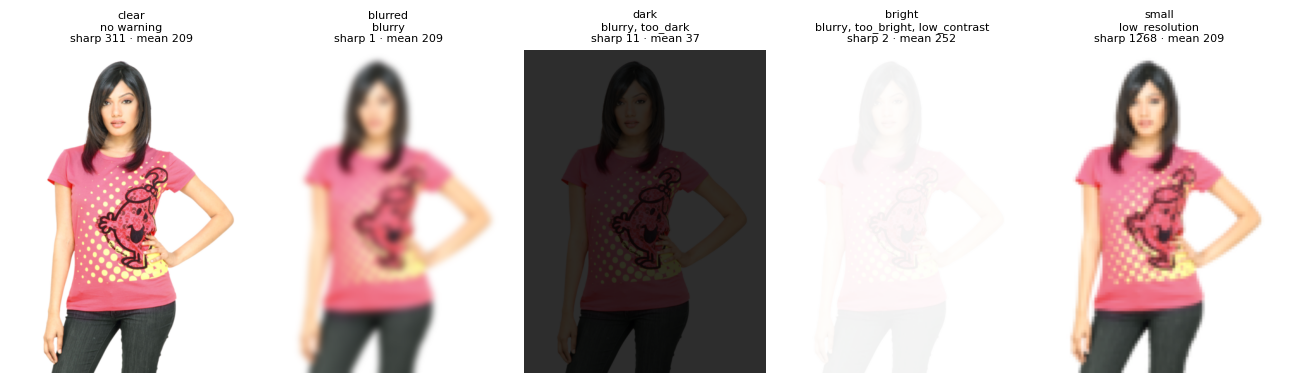

example report for the blurred image:
{
  "version": "quality-v0.1",
  "readable": true,
  "measurements": {
    "width": 384,
    "height": 512,
    "min_side": 384,
    "brightness_mean": 208.53,
    "brightness_p05": 68.0,
    "brightness_p95": 255.0,
    "contrast_std": 62.97,
    "sharpness": 1.34
  },
  "warnings": [
    {
      "code": "blurry",
      "message": "The photo looks blurry.",
      "action": "Hold the phone steady, tap to focus, and retake."
    }
  ],
  "advisory_only": true,
  "thresholds_status": "provisional: calibrated on catalog validation images and synthetic degradations, not on phone photos"
}


In [47]:
# Fresh-process evaluation of the rules (needs the previous cell).
if SELECTED is not None:
    # Evaluate the rules in a FRESH process, on files: clear images and four synthetic degradations of each.
    qdir = WORK / "cache" / "quality_examples"
    shutil.rmtree(qdir, ignore_errors=True); qdir.mkdir(parents=True)
    kinds, files = ["clear", "blurred", "dark", "bright", "small"], []
    for i, p in enumerate(cal["image_path"].head(60)):
        base = _lum(load_rgb(p))
        for k in kinds:
            f = qdir / f"{i:03d}_{k}.png"
            degrade(base, k).save(f); files.append(str(f.resolve()))
    (qdir / "broken.jpg").write_bytes(b"not an image"); files.append(str((qdir / "broken.jpg").resolve()))
    proc = subprocess.run([sys.executable, "-B", "quality_checks.py"] + files, capture_output=True, text=True, cwd=str(SEL), timeout=1800)
    if proc.returncode != 0:
        raise RuntimeError("quality_checks.py failed in a fresh process:\n" + proc.stderr[-1500:])
    rep = json.loads(proc.stdout.strip().splitlines()[-1])
    expected = {"blurred": "blurry", "dark": "too_dark", "bright": "too_bright", "small": "low_resolution"}
    rows_ = []
    for k in kinds:
        rs = [v for f, v in rep.items() if f.endswith(f"_{k}.png")]
        codes = [{w["code"] for w in r["warnings"]} for r in rs]
        rows_.append({"image set": k, "n": len(rs),
                      "expected warning": expected.get(k, "(none)"),
                      "share with the expected warning": float(np.mean([expected[k] in c for c in codes])) if k in expected else None,
                      "share with any warning": float(np.mean([bool(c) for c in codes])),
                      "warnings seen": ", ".join(f"{c} ({n})" for c, n in Counter(x for c in codes for x in c).most_common())})
    q_tbl = pd.DataFrame(rows_)
    with pd.option_context("display.max_colwidth", 90):
        display(q_tbl.round(3))
    broken = rep[str((qdir / "broken.jpg").resolve())]
    assert broken["readable"] is False and broken["warnings"][0]["code"] == "unreadable"
    print("unreadable file ->", broken["warnings"][0]["message"])
    print("How to read this: 'clear' rows show the false-warning rate on catalog photos; the other rows show whether a strong "
          "SYNTHETIC degradation is caught. Real blur, shadows and phone lighting are different, so every threshold needs "
          "checking on your own phone photos before the warnings are trusted.")

    # One worked example for the report.
    fig, axes = plt.subplots(1, len(kinds), figsize=(2.6 * len(kinds), 3.9))
    for ax, k in zip(axes, kinds):
        f = str((qdir / f"000_{k}.png").resolve())
        with Image.open(f) as im:
            ax.imshow(im)
        r = rep[f]
        ax.set_title(f"{k}\n" + (", ".join(w["code"] for w in r["warnings"]) or "no warning")
                     + f"\nsharp {r['measurements']['sharpness']:.0f} · mean {r['measurements']['brightness_mean']:.0f}", fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.savefig(WORK / "figures" / "quality_assistant_examples.png", dpi=100); plt.show()
    print("example report for the blurred image:")
    print(json.dumps(rep[str((qdir / "000_blurred.png").resolve())], indent=2))
    (WORK / "reports" / "quality_assistant.json").write_text(json.dumps(
        {"config": QUALITY_CONFIG, "evaluation": rows_, "evaluated_in": "fresh python subprocess",
         "note": "synthetic degradations of catalog validation images; not phone photos"}, indent=2), encoding="utf-8")
    q_tbl.to_csv(WORK / "reports" / "quality_assistant_evaluation.csv", index=False)

In [48]:
# Document the module, then refresh checksums, the bundle zip and the results zip (in that order).
if SELECTED is not None:
    # Document it, then refresh checksums, the bundle zip and the results zip (in that order).
    readme = (SEL / "README.md").read_text(encoding="utf-8")
    if "quality_checks" not in readme:
        (SEL / "README.md").write_text(readme + "\n".join([
            "", "## Optional: image quality assistant", "",
            "```python", "from quality_checks import check_image", "report = check_image('photo.jpg')   # warnings + suggested actions", "```", "",
            "Rule-based warnings (small, blurry, dark, washed out, low contrast). Advisory only: it never blocks a prediction, and a clean "
            "report does not mean the garment is fully visible or that the prediction is right. Thresholds in `quality_config.json` are "
            "provisional and were not validated on phone photos.", ""]), encoding="utf-8")
    manifest = {p.name: {"bytes": p.stat().st_size, "sha256": sha256_file(p)}
                for p in sorted(SEL.iterdir()) if p.is_file() and p.name != "checksums.json"}
    (SEL / "checksums.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    zpath = WORK / "selected_model_bundle.zip"
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(SEL.iterdir()):
            if p.is_file():
                z.write(p, p.name)
    with zipfile.ZipFile(zpath) as z:
        assert all(hashlib.sha256(z.read(n)).hexdigest() == manifest[n]["sha256"] for n in manifest), "zip does not match checksums"
    if (SEL / "selftest.py").exists():                     # the classifier/description self-test must still pass
        st = subprocess.run([sys.executable, "-B", "selftest.py"], capture_output=True, text=True, cwd=str(SEL), timeout=1800)
        ok = st.returncode == 0 and json.loads(st.stdout.strip().splitlines()[-1])["passed"]
        print("bundle self-test after adding the module:", "passed" if ok else "FAILED")
        assert ok, st.stderr[-800:]
    set_status("quality_assistant", "provisional", f"advisory warnings; thresholds not validated on phone photos; bundle now {len(manifest) + 1} files")
    with open(WORK / "reports" / "BO6_RESULTS.md", "a", encoding="utf-8") as f:
        f.write("\n## Optional enhancement: image quality assistant\n"
                f"- `quality_checks.check_image(photo)` returns measurements, warnings and suggested actions; advisory only.\n"
                f"- thresholds: provisional ({QUALITY_CONFIG['status']}); evaluation on synthetic degradations: `reports/quality_assistant_evaluation.csv`.\n")
    rzip = WORK / "bo6_results.zip"
    with zipfile.ZipFile(rzip, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(WORK.rglob("*")):
            if p.is_file() and "cache" not in p.relative_to(WORK).parts and p.name not in {"last_checkpoint.pt", "bo6_results.zip"}:
                z.write(p, p.relative_to(WORK))
    print(f"refreshed: {zpath.name} ({zpath.stat().st_size / 1e6:.1f} MB, {len(manifest) + 1} files) and {rzip.name} ({rzip.stat().st_size / 1e6:.0f} MB)")

bundle self-test after adding the module: passed
[PROVISIONAL] quality_assistant — advisory warnings; thresholds not validated on phone photos; bundle now 25 files
refreshed: selected_model_bundle.zip (15.3 MB, 25 files) and bo6_results.zip (238 MB)


In [49]:
import os
from IPython.display import FileLink, display
os.chdir("/kaggle/working")
for f in ["bo6/selected_model_bundle.zip", "bo6/bo6_results.zip"]:
    print(f, round(os.path.getsize(f) / 1e6, 1), "MB")
    display(FileLink(f))

bo6/selected_model_bundle.zip 15.3 MB


/kaggle/working/bo6/selected_model_bundle.zip

bo6/bo6_results.zip 238.2 MB


/kaggle/working/bo6/bo6_results.zip